# *EDA FOR DB2 ***

In [1]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [2]:
import os

DB2_ROOTS = [
    '/kaggle/input/datasets/farahellabban/ninapro-db2-1',
    '/kaggle/input/datasets/farahellabban/ninapro-db2-2',
    '/kaggle/input/datasets/farahellabban/ninapro-db2-3',
    '/kaggle/input/datasets/farahellabban/ninapro-db2-4',
]
DB4_ROOTS = ['/kaggle/input/datasets/farahellabban/ninapro-db4']
DB3_ROOTS = ['/kaggle/input/datasets/farahellabban/ninapro-db3-amp']

for name, roots in [('DB2', DB2_ROOTS), ('DB4', DB4_ROOTS), ('DB3', DB3_ROOTS)]:
    print(f"===== {name} =====")
    for r in roots:
        if os.path.exists(r):
            print(f"  ✅ {r}")
            print(f"     -> {os.listdir(r)[:6]}")
        else:
            print(f"  ❌ NOT FOUND: {r}  (copy the exact path from Kaggle side panel)")

===== DB2 =====
  ✅ /kaggle/input/datasets/farahellabban/ninapro-db2-1
     -> ['DB2_s6', 'DB2_s4', 'DB2_s9', 'DB2_s8', 'DB2_s7', 'DB2_s1']
  ✅ /kaggle/input/datasets/farahellabban/ninapro-db2-2
     -> ['DB2_s20', 'DB2_s17', 'DB2_s18', 'DB2_s13', 'DB2_s12', 'DB2_s15']
  ✅ /kaggle/input/datasets/farahellabban/ninapro-db2-3
     -> ['DB2_s23', 'DB2_s21', 'DB2_s30', 'DB2_s24', 'DB2_s25', 'DB2_s29']
  ✅ /kaggle/input/datasets/farahellabban/ninapro-db2-4
     -> ['DB2_s40', 'DB2_s35', 'DB2_s38', 'DB2_s39', 'DB2_s31', 'DB2_s37']
===== DB4 =====
  ✅ /kaggle/input/datasets/farahellabban/ninapro-db4
     -> ['s1', 's10', 's8', 's5', 's7', 's9']
===== DB3 =====
  ✅ /kaggle/input/datasets/farahellabban/ninapro-db3-amp
     -> ['s6_0', 's7_0', 's10_0', 's4_0', 's1_0', 's3_0']


In [3]:
import os, glob, re
import numpy as np
import scipy.io as sio
from scipy.io import whosmat

# ==========================================
# 1. Full Inventory: scan ALL .mat files once, parse subject & exercise from FILENAME
# ==========================================
def build_inventory(roots):
    inv = {}   # inv[subject][exercise] = [file paths]
    for r in roots:
        for f in glob.glob(os.path.join(r, '**', '*.mat'), recursive=True):
            m = re.search(r'S(\d+)_E(\d+)', os.path.basename(f))
            if m:
                subj, ex = int(m.group(1)), int(m.group(2))
                inv.setdefault(subj, {}).setdefault(ex, []).append(f)
    return inv

def summarize(name, inv):
    print(f"\n{'='*70}\n{name}\n{'='*70}")
    subjects = sorted(inv.keys())
    print(f"Subjects found ({len(subjects)}): {subjects}")
    for s in subjects:
        exs = sorted(inv[s].keys())
        print(f"  S{s:>2}: exercises {exs} | files/EX: " +
              ", ".join(f"E{e}={len(inv[s][e])}" for e in exs))
    return subjects

inv_db2 = build_inventory(DB2_ROOTS)
inv_db4 = build_inventory(DB4_ROOTS)
inv_db3 = build_inventory(DB3_ROOTS)

summarize("NINAPRO DB2 (Delsys, 12ch, 2kHz)", inv_db2)
summarize("NINAPRO DB4 (Cometa, 12ch, 2kHz)", inv_db4)
summarize("NINAPRO DB3 (Amputees, Delsys)", inv_db3)

# ==========================================
# 2. Structure Probe: keys + shapes WITHOUT loading data (RAM-safe)
# ==========================================
def probe_structure(inv, subj, exercise, tag):
    files = inv.get(subj, {}).get(exercise, [])
    if not files:
        print(f"  [{tag}] S{subj}_E{exercise}: FILE NOT FOUND")
        return
    path = files[0]
    info = whosmat(path)
    print(f"\n  [{tag}] {os.path.basename(path)}")
    for name, shape, dtype in info:
        print(f"      {name:<12} shape={str(shape):<18} dtype={dtype}")

print(f"\n{'='*70}\nSTRUCTURE PROBE (one file per dataset per exercise)\n{'='*70}")
for tag, inv in [('DB2', inv_db2), ('DB4', inv_db4), ('DB3', inv_db3)]:
    s = sorted(inv.keys())[0]
    for ex in [1, 2, 3]:
        probe_structure(inv, s, ex, tag)

# ==========================================
# 3. Label Range Probe: which classes live in which exercise?
#    (loads ONLY the tiny label arrays, not the signals)
# ==========================================
print(f"\n{'='*70}\nLABEL RANGES PER EXERCISE (class mapping check)\n{'='*70}")
def probe_labels(inv, subj, exercise, tag):
    files = inv.get(subj, {}).get(exercise, [])
    if not files:
        return
    d = sio.loadmat(files[0], variable_names=['restimulus', 'repetition'])
    labs = np.unique(d['restimulus'].flatten())
    reps = np.unique(d['repetition'].flatten())
    print(f"  [{tag}] S{subj}_E{exercise}: classes {labs.min()}..{labs.max()} "
          f"(n={len(labs)}) reps={reps.tolist()}")
    print(f"           classes: {labs.tolist()}")

for tag, inv in [('DB2', inv_db2), ('DB4', inv_db4), ('DB3', inv_db3)]:
    s = sorted(inv.keys())[0]
    for ex in [1, 2, 3]:
        probe_labels(inv, s, ex, tag)


NINAPRO DB2 (Delsys, 12ch, 2kHz)
Subjects found (40): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
  S 1: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 2: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 3: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 4: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 5: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 6: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 7: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 8: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S 9: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S10: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S11: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S12: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S13: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S14: exercises [1, 2, 3] | files/EX: E1=1, E2=1, E3=1
  S15: ex

CLASS DISTRIBUTION AUDIT (labels only, fast)

[DB2] E2: 24 classes | 101,084,541 samples | REST = 42.5%
    class   0: 43,005,908
    class  18: 2,503,835
    class  19: 2,240,167
    class  20: 2,328,417
    class  21: 2,018,979
    class  22: 2,413,416
    class  23: 2,378,305
    class  24: 2,879,537
    class  25: 2,490,929
    class  26: 2,744,619
    class  27: 2,300,305
    class  28: 2,482,717
    class  29: 2,588,059
    class  30: 2,585,906
    class  31: 2,755,932
    class  32: 2,896,376
    class  33: 2,727,346
    class  34: 3,000,318
    class  35: 2,642,238
    class  36: 2,712,735
    class  37: 2,300,841
    class  38: 2,695,825
    class  39: 2,065,866
    class  40: 2,325,965

[DB3] E2: 24 classes | 23,902,445 samples | REST = 39.8%
    class   0: 9,502,853
    class  18:   621,539
    class  19:   624,804
    class  20:   593,958
    class  21:   635,008
    class  22:   639,623
    class  23:   614,338
    class  24:   707,476
    class  25:   647,799
    class  2

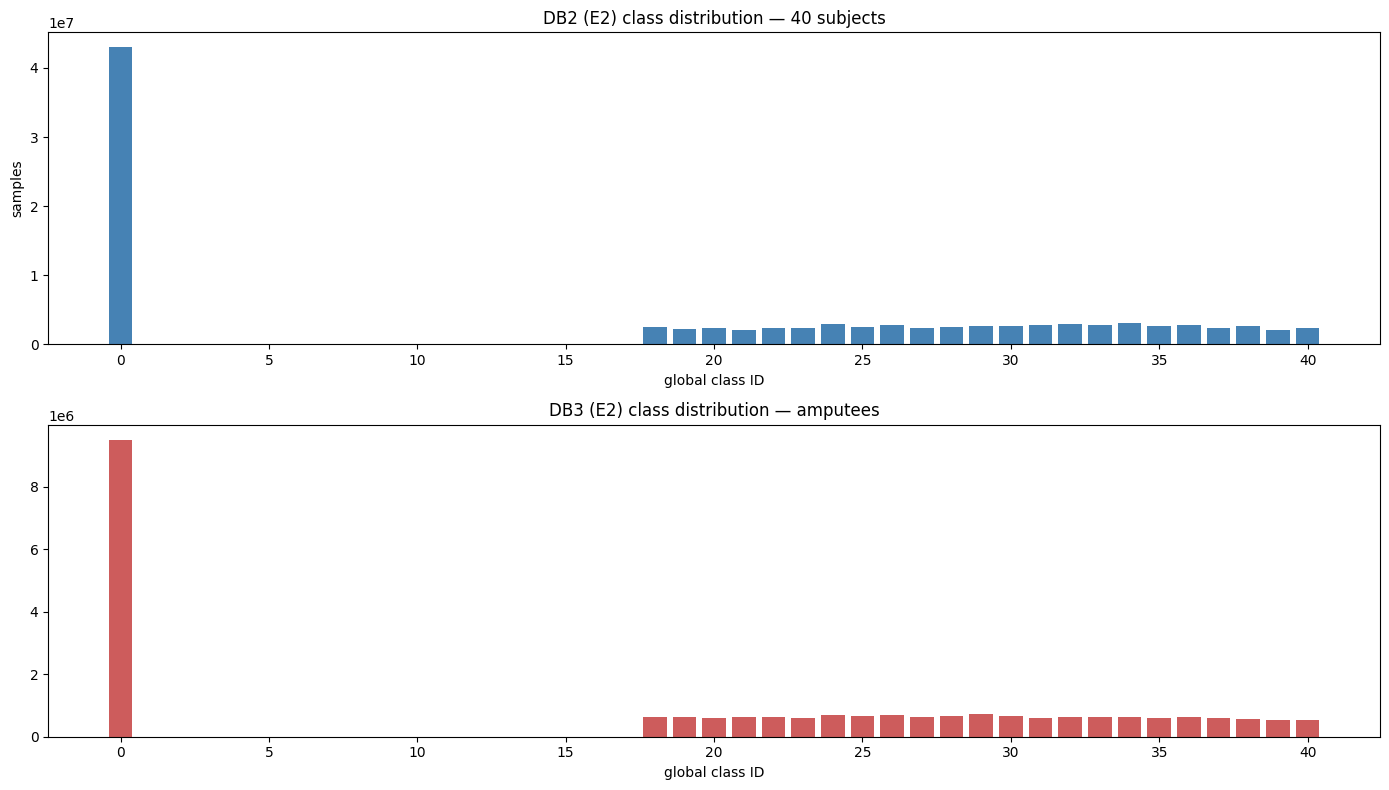

In [6]:
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

# ==========================================
# 1. Label-only audit (RAM-safe: loads restimulus only)
# ==========================================
def audit_labels(inv, subjects, exercise, tag):
    rows = []
    subj_class_sets = {}
    for s in subjects:
        files = inv.get(s, {}).get(exercise, [])
        if not files:
            print(f"  [{tag}] S{s}: FILE MISSING"); continue
        d = sio.loadmat(files[0], variable_names=['restimulus'])
        labs = np.asarray(d['restimulus']).flatten().astype(int)
        uniq, cnt = np.unique(labs, return_counts=True)
        subj_class_sets[s] = set(uniq.tolist())
        for u, c in zip(uniq, cnt):
            rows.append({'dataset': tag, 'subject': s, 'class': int(u), 'samples': int(c)})
    df = pd.DataFrame(rows)
    agg = df.groupby('class')['samples'].sum().sort_index()
    total = agg.sum()
    rest = int(agg.get(0, 0))
    print(f"\n[{tag}] E{exercise}: {len(agg)} classes | {total:,} samples | REST = {rest/total*100:.1f}%")
    for cls, n in agg.items():
        print(f"    class {cls:>3}: {n:>9,}")
    return agg, subj_class_sets, df

print("="*70); print("CLASS DISTRIBUTION AUDIT (labels only, fast)"); print("="*70)
agg2,  sets2,  df2   = audit_labels(inv_db2, sorted(inv_db2), 2, 'DB2')
agg3,  sets3,  df3   = audit_labels(inv_db3, sorted(inv_db3), 2, 'DB3')
agg42, sets42, df42  = audit_labels(inv_db4, sorted(inv_db4), 2, 'DB4-E2')
agg43, sets43, df43  = audit_labels(inv_db4, sorted(inv_db4), 3, 'DB4-E3')

# ==========================================
# 2. Shared Class Set (DB2 ∩ DB3) = هيبقى الـ evaluation set الرسمي
# ==========================================
shared23 = sorted(set(agg2.index) & set(agg3.index))
print("\n" + "="*70)
print(f"SHARED CLASSES DB2 ∩ DB3 (E2): {shared23}")
print(f"  → {len(shared23)} classes = الـ Shared Class Set بتاع الاختبار السريري")

# ==========================================
# 3. Per-subject missing classes (مهم للـ Few-Shot planning)
# ==========================================
print("\nPer-subject missing classes:")
for tag, sets, agg in [('DB2', sets2, agg2), ('DB3', sets3, agg3)]:
    allc = set(agg.index)
    for s, st in sorted(sets.items()):
        miss = sorted(allc - st)
        if miss:
            print(f"  [{tag}] S{s:>2} missing: {miss}")

# ==========================================
# 4. Movement naming (قاموس المشروع — VERIFY من جدول حركات NinaPro الرسمي قبل المناقشة)
# ==========================================
MOVEMENT_NAMES = {
    0:  'Rest',
    18: 'Hand Open',            19: 'Hand Close',
    20: 'Wrist Flexion',        21: 'Wrist Extension',
    22: 'Ulnar Deviation',      23: 'Radial Deviation',
    24: 'Supination',           25: 'Power Grip',
    26: 'Lateral Grip',         27: 'Tip Grip',
    28: 'Hook Grip',            29: 'Cylindrical Grip',
}
print("\nShared classes with project names:")
for c in shared23:
    print(f"    {c:>3} → {MOVEMENT_NAMES.get(c, 'NAME-TBD')}")

# ==========================================
# 5. DB4 local-label warning + mapping hypothesis
# ==========================================
print("\n" + "="*70)
print("DB4 LABELING WARNING: local per-exercise IDs (E2:0-17, E3:0-23).")
print("Hypothesis to verify vs official NinaPro movement table:")
print("  DB4-E3 local k (1..23)  <->  global ID (17+k)  [i.e. DB2-E2 order]")
print("  DB4-E2 local k (1..17)  <->  global ID ???     [needs official list]")
print("="*70)

# ==========================================
# 6. Save CSVs + plots for the thesis
# ==========================================
df_all = pd.concat([df2, df3, df42, df43], ignore_index=True)
df_all.to_csv('/kaggle/working/eda_class_counts.csv', index=False)
print("\n✅ Saved: /kaggle/working/eda_class_counts.csv")

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].bar(agg2.index, agg2.values, color='steelblue')
axes[0].set_title('DB2 (E2) class distribution — 40 subjects')
axes[0].set_xlabel('global class ID'); axes[0].set_ylabel('samples')
axes[1].bar(agg3.index, agg3.values, color='indianred')
axes[1].set_title('DB3 (E2) class distribution — amputees')
axes[1].set_xlabel('global class ID')
plt.tight_layout(); plt.show()

CROSSTALK AUDIT: E1 vs E2 (Subject 1)
  E1 (basic finger):  crosstalk index = 0.1258 ± 0.0202
  E2 (grasp/func):    crosstalk index = 0.1039 ± 0.0163
  Ratio E1/E2 = 1.21x
  ✅ CONFIRMED: E1 has higher neural crosstalk -> exclusion justified


/tmp/ipykernel_49/3334375139.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


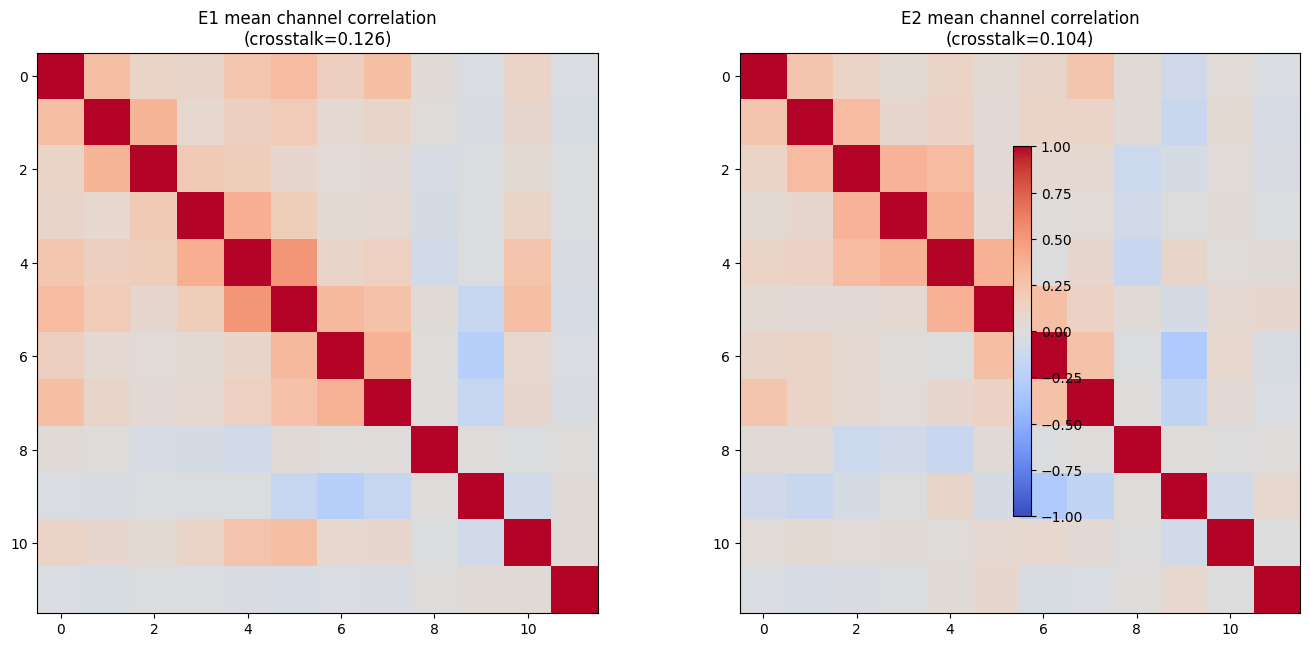

In [7]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

# ==========================================
# 1. Crosstalk Index = متوسط |الارتباط| بين القنوات خارج القطر
# ==========================================
def crosstalk_index(emg_seg):
    """emg_seg: (N, C) -> mean |off-diagonal correlation|, full corr matrix"""
    C = emg_seg.shape[1]
    corr = np.corrcoef(emg_seg.T)
    off_diag_mask = ~np.eye(C, dtype=bool)
    return np.mean(np.abs(corr[off_diag_mask])), corr

def audit_exercise_crosstalk(inv, subj, ex, classes, max_samples=20000):
    """يحسب الـ crosstalk index لكل klasse ويرجع المتوسط + مصفوفة الارتباط المتوسطة"""
    path = inv[subj][ex][0]
    d = sio.loadmat(path, variable_names=['emg', 'restimulus'])
    emg = d['emg'].astype(np.float32)
    labs = d['restimulus'].flatten().astype(int)
    n = min(len(emg), len(labs))          # حماية من الـ off-by-one
    emg, labs = emg[:n], labs[:n]

    per_class, corr_mats = [], []
    for c in classes:
        idx = np.where(labs == c)[0]
        if len(idx) < 2000:
            continue
        idx = idx[:max_samples]
        ci, corr = crosstalk_index(emg[idx])
        per_class.append(ci)
        corr_mats.append(corr)
    per_class = np.array(per_class)
    return per_class.mean(), per_class.std(), np.mean(corr_mats, axis=0)

# ==========================================
# 2. التنفيذ: مقارنة E1 vs E2 على نفس المريض (S1)
# ==========================================
E1_CLASSES = [1, 2, 3, 4, 5, 6, 7, 8]        # basic finger movements
E2_CLASSES = [18, 19, 20, 21, 22, 23, 24]    # core clinical set

print("="*70)
print("CROSSTALK AUDIT: E1 vs E2 (Subject 1)")
print("="*70)
m1, s1, corr1 = audit_exercise_crosstalk(inv_db2, 1, 1, E1_CLASSES)
m2, s2, corr2 = audit_exercise_crosstalk(inv_db2, 1, 2, E2_CLASSES)

print(f"  E1 (basic finger):  crosstalk index = {m1:.4f} ± {s1:.4f}")
print(f"  E2 (grasp/func):    crosstalk index = {m2:.4f} ± {s2:.4f}")
print(f"  Ratio E1/E2 = {m1/max(m2,1e-9):.2f}x")
if m1 > m2:
    print("  ✅ CONFIRMED: E1 has higher neural crosstalk -> exclusion justified")
else:
    print("  ⚠️ Unexpected: revisit the exclusion rationale")

# ==========================================
# 3. Heatmaps للرسالة
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(corr1, cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set_title(f"E1 mean channel correlation\n(crosstalk={m1:.3f})")
im1 = axes[1].imshow(corr2, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_title(f"E2 mean channel correlation\n(crosstalk={m2:.3f})")
fig.colorbar(im0, ax=axes, shrink=0.8)
plt.tight_layout()
plt.show()

In [5]:
# OPTIONAL: paired crosstalk audit over 5 subjects (stronger statistical evidence)
print('Subject |   E1    |   E2    | ratio')
for s in [1, 2, 3, 4, 5]:
    m1, _, _ = audit_exercise_crosstalk(inv_db2, s, 1, [1,2,3,4,5,6,7,8])
    m2, _, _ = audit_exercise_crosstalk(inv_db2, s, 2, [18,19,20,21,22,23,24])
    print(f'   S{s}   | {m1:.4f} | {m2:.4f} | {m1/m2:.2f}x')

Subject |   E1    |   E2    | ratio
   S1   | 0.1258 | 0.1039 | 1.21x
   S2   | 0.1067 | 0.0888 | 1.20x
   S3   | 0.0908 | 0.0682 | 1.33x
   S4   | 0.1009 | 0.0975 | 1.04x
   S5   | 0.0545 | 0.0618 | 0.88x


SIGNAL QUALITY AUDIT  (Subject 1, E2, first 10 s)
DB2 (Delsys, able-bodied)    | RMS =      0.00 ±     0.00 | MAV =      0.00 | 50Hz/EMG power =  2.78
DB3 (Delsys, amputee)        | RMS =      0.00 ±     0.00 | MAV =      0.00 | 50Hz/EMG power =  1.35
DB4 (Cometa, able-bodied)    | RMS =    226.52 ±   155.33 | MAV =    136.10 | 50Hz/EMG power =  3.01


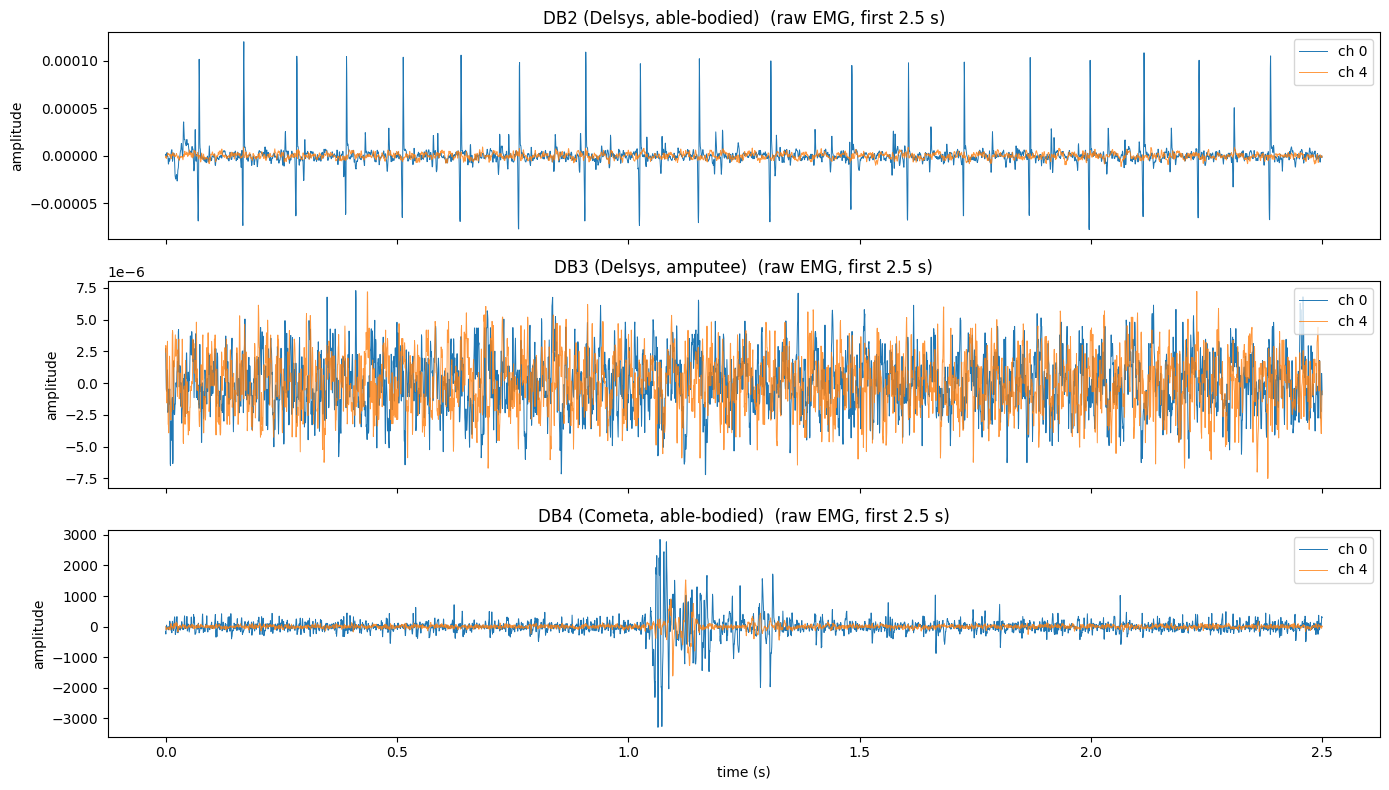

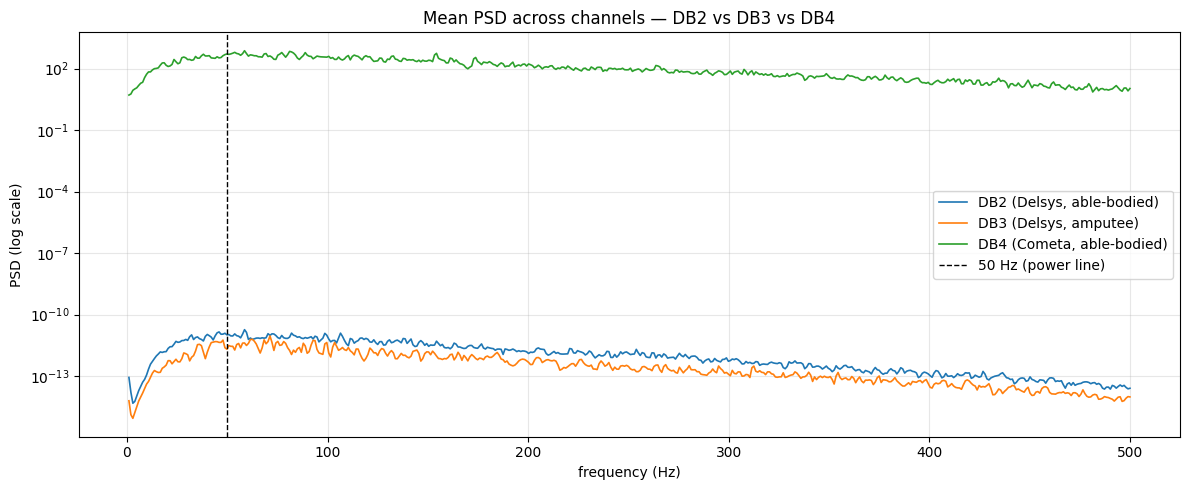

In [8]:
import numpy as np
import scipy.io as sio
from scipy.signal import welch
import matplotlib.pyplot as plt

FS = 2000.0
SNIP = 20000   # 10 seconds

def load_snippet(inv, subj, ex, n=SNIP):
    path = inv[subj][ex][0]
    d = sio.loadmat(path, variable_names=['emg'])
    return d['emg'][:n, :12].astype(np.float32)

print('='*70)
print('SIGNAL QUALITY AUDIT  (Subject 1, E2, first 10 s)')
print('='*70)

snips = {
    'DB2 (Delsys, able-bodied)': load_snippet(inv_db2, 1, 2),
    'DB3 (Delsys, amputee)':     load_snippet(inv_db3, 1, 2),
    'DB4 (Cometa, able-bodied)': load_snippet(inv_db4, 1, 2),
}

summary = {}
for name, x in snips.items():
    rms_ch = np.sqrt(np.mean(x**2, axis=0))       # per-channel RMS
    mav_ch = np.mean(np.abs(x), axis=0)           # per-channel MAV
    f, P = welch(x, fs=FS, nperseg=2048, axis=0)  # PSD per channel
    P_avg = P.mean(axis=1)
    p50   = P_avg[(f >= 49) & (f <= 51)].mean()   # power-line band
    p_emg = P_avg[(f >= 20) & (f <= 450)].mean()  # EMG band
    ratio = p50 / (p_emg + 1e-12)
    summary[name] = dict(rms=rms_ch.mean(), rms_sd=rms_ch.std(),
                         mav=mav_ch.mean(), plr=ratio, f=f, P=P_avg, x=x)
    print(f'{name:28s} | RMS = {rms_ch.mean():9.2f} ± {rms_ch.std():8.2f} | '
          f'MAV = {mav_ch.mean():9.2f} | 50Hz/EMG power = {ratio:5.2f}')

# ---- Figure 1: raw traces side by side ----
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
n_plot = 5000                      # first 2.5 s
t = np.arange(n_plot) / FS
for ax, (name, s) in zip(axes, summary.items()):
    ax.plot(t, s['x'][:n_plot, 0], lw=0.7, label='ch 0')
    ax.plot(t, s['x'][:n_plot, 4], lw=0.7, label='ch 4', alpha=0.8)
    ax.set_title(f'{name}  (raw EMG, first 2.5 s)')
    ax.legend(loc='upper right'); ax.set_ylabel('amplitude')
axes[-1].set_xlabel('time (s)')
plt.tight_layout(); plt.show()

# ---- Figure 2: PSD comparison with 50 Hz marker ----
plt.figure(figsize=(12, 5))
for name, s in summary.items():
    m = (s['f'] > 0) & (s['f'] <= 500)
    plt.semilogy(s['f'][m], s['P'][m], lw=1.2, label=name)
plt.axvline(50, color='k', ls='--', lw=1, label='50 Hz (power line)')
plt.xlabel('frequency (Hz)'); plt.ylabel('PSD (log scale)')
plt.title('Mean PSD across channels — DB2 vs DB3 vs DB4')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

TRUE RMS (scientific notation)
DB2 (Delsys, able-bodied)    RMS = 3.335e-05
DB3 (Delsys, amputee)        RMS = 1.889e-05
DB4 (Cometa, able-bodied)    RMS = 2.747e+02

KINEMATIC (GLOVE) AUDIT (Subject 1, E2, first 10 s)
[DB2] glove (20000, 22) | range [-35, 498] | ch-std 1.5..173.6
[DB3] glove (20000, 22) | range [-58, 314] | ch-std 0.0..0.0
[DB4] no glove keys (confirmed) -> kinematic head trains on DB2/DB3 only

FORCE AUDIT (E3) + forcecal row diagnosis
[DB2] force (877073, 6) | forcecal (2, 6) | raw [-8.6, 22.7]
    rows (0,1) -> normalized [-0.686, 1.537] invalid
    forcecal unusable -> empirical 1-99% normalization
[DB3] force (881748, 6) | forcecal (4, 6) | raw [-2.1, 15.4]
    rows (0,1) -> normalized [-0.223, 1.081] invalid
    rows (2,3) -> normalized [-0.397, 2.571] invalid
    rows (0,2) -> normalized [-284.424, 1009.000] invalid
    rows (1,3) -> normalized [-0.166, 3.455] invalid
    forcecal unusable -> empirical 1-99% normalization
=> DB2 cal rows: empirical | DB3 cal ro

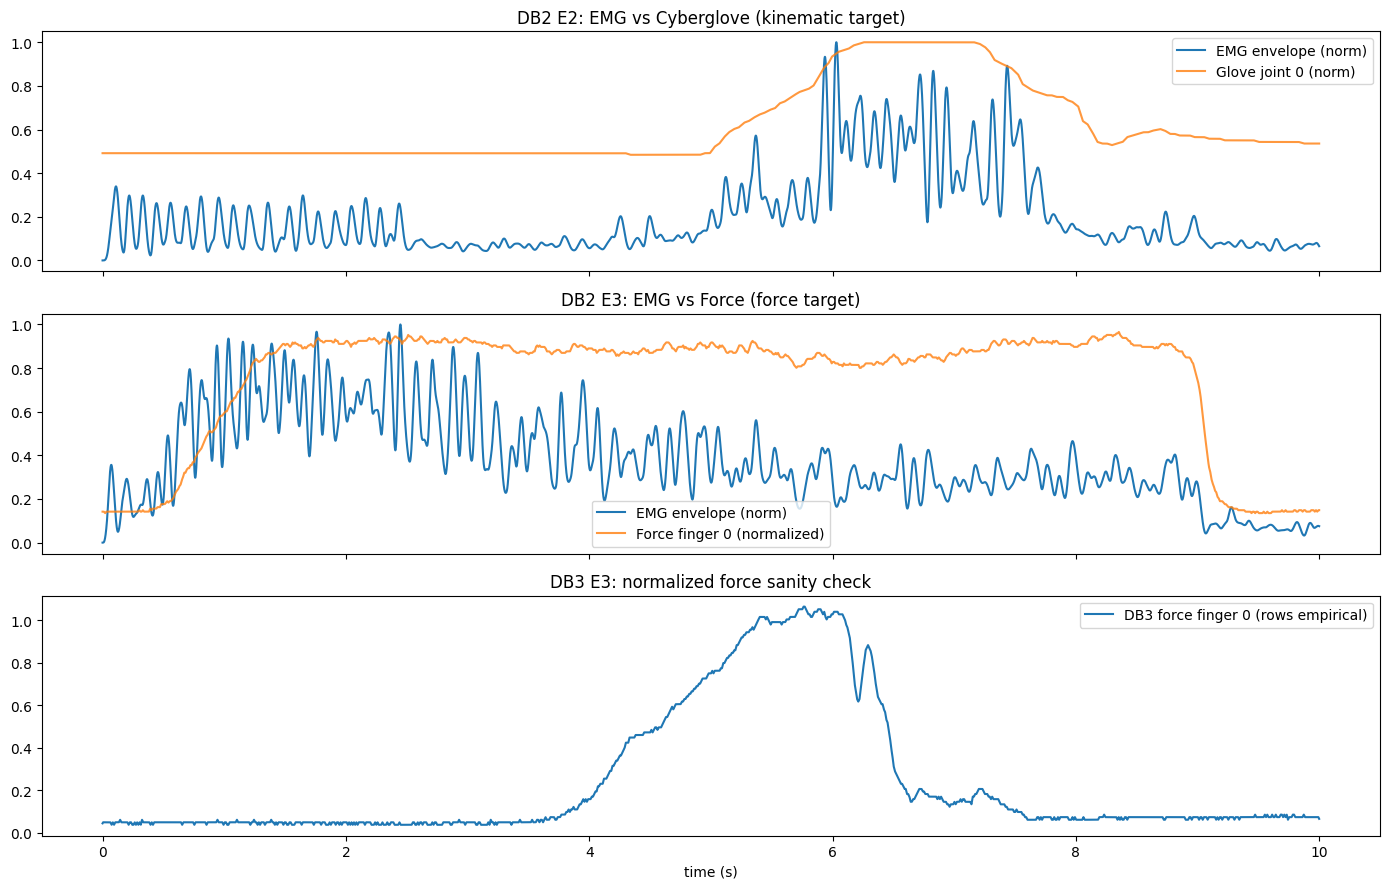


ACTIVATION CONTRAST (rest vs movement RMS)
[DB2] rest RMS = 7.895e-06 | move RMS = 3.607e-05 | contrast = 4.57x
[DB3] rest RMS = 3.308e-06 | move RMS = 1.093e-05 | contrast = 3.30x
[DB4] rest RMS = 1.249e+02 | move RMS = 7.848e+02 | contrast = 6.28x


In [9]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter, iirnotch

FS = 2000.0

def load_vars(inv, subj, ex, keys):
    return sio.loadmat(inv[subj][ex][0], variable_names=keys)

def emg_envelope(emg, ch=0, fs=FS, cutoff=10.0):
    b, a = iirnotch(50.0/(fs/2), 30.0); x = lfilter(b, a, emg[:, ch])
    b2, a2 = butter(4, [20.0/(fs/2), 500.0/(fs/2)], btype='band'); x = lfilter(b2, a2, x)
    b3, a3 = butter(4, cutoff/(fs/2), btype='low'); return lfilter(b3, a3, np.abs(x))

def sync_score(a, b):
    a = (a - a.mean())/(a.std()+1e-9); b = (b - b.mean())/(b.std()+1e-9)
    return float(np.corrcoef(a, b)[0, 1])

# ==========================================
# 0. Formatting fix: true RMS in scientific notation
# ==========================================
print("="*70); print("TRUE RMS (scientific notation)"); print("="*70)
for name, x in snips.items():
    print(f"{name:28s} RMS = {np.sqrt(np.mean(x**2)):.3e}")

# ==========================================
# 1. KINEMATIC AUDIT (Cyberglove, 22 joints)
# ==========================================
print(); print("="*70); print("KINEMATIC (GLOVE) AUDIT (Subject 1, E2, first 10 s)"); print("="*70)
for tag, inv in [("DB2", inv_db2), ("DB3", inv_db3)]:
    g = load_vars(inv, 1, 2, ['glove'])['glove'][:20000].astype(np.float32)
    print(f"[{tag}] glove {g.shape} | range [{g.min():.0f}, {g.max():.0f}] | ch-std {g.std(0).min():.1f}..{g.std(0).max():.1f}")
print("[DB4] no glove keys (confirmed) -> kinematic head trains on DB2/DB3 only")

# ==========================================
# 2. FORCE AUDIT + forcecal row diagnosis (DB3 = 4x6 !)
# ==========================================
print(); print("="*70); print("FORCE AUDIT (E3) + forcecal row diagnosis"); print("="*70)
def audit_force(inv, tag):
    d = load_vars(inv, 1, 3, ['force', 'forcecal'])
    f = d['force'].astype(np.float32); cal = d['forcecal'].astype(np.float32)
    print(f"[{tag}] force {f.shape} | forcecal {cal.shape} | raw [{f.min():.1f}, {f.max():.1f}]")
    for (r0, r1) in [(0,1), (2,3), (0,2), (1,3)]:
        if max(r0, r1) >= cal.shape[0]: continue
        rng = np.where((cal[r1]-cal[r0])==0, 1.0, cal[r1]-cal[r0])
        fn = (f - cal[r0])/rng
        ok = (fn.min() > -0.2) and (fn.max() < 1.2)
        print(f"    rows ({r0},{r1}) -> normalized [{fn.min():.3f}, {fn.max():.3f}] {'VALID' if ok else 'invalid'}")
        if ok: return f, fn, (r0, r1)
    lo, hi = np.percentile(f, 1, axis=0), np.percentile(f, 99, axis=0)
    print("    forcecal unusable -> empirical 1-99% normalization")
    return f, (f-lo)/np.where((hi-lo)==0, 1.0, hi-lo), 'empirical'

f2_raw, f2_norm, rows2 = audit_force(inv_db2, "DB2")
f3_raw, f3_norm, rows3 = audit_force(inv_db3, "DB3")
print(f"=> DB2 cal rows: {rows2} | DB3 cal rows: {rows3}")

# ==========================================
# 3. SYNCHRONY: EMG envelope vs glove vs force
# ==========================================
print(); print("="*70); print("EMG <-> GLOVE / FORCE SYNCHRONY (justifies regression heads)"); print("="*70)
N = 20000
d2 = load_vars(inv_db2, 1, 2, ['emg', 'glove'])
env2 = emg_envelope(d2['emg'][:N]); g2 = d2['glove'][:N].astype(np.float32)
corr_g = np.array([abs(sync_score(env2, g2[:, j])) for j in range(g2.shape[1])])
print(f"[DB2 E2] |corr(EMG env, glove joints)|: mean={corr_g.mean():.3f}, max={corr_g.max():.3f}")

d3 = load_vars(inv_db2, 1, 3, ['emg'])
env3 = emg_envelope(d3['emg'][:N])
corr_f = np.array([abs(sync_score(env3, f2_norm[:N, j])) for j in range(f2_norm.shape[1])])
print(f"[DB2 E3] |corr(EMG env, force fingers)|: mean={corr_f.mean():.3f}, max={corr_f.max():.3f}")

t = np.arange(N)/FS
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(t, env2/env2.max(), label='EMG envelope (norm)')
axes[0].plot(t, g2[:,0]/np.abs(g2[:,0]).max(), label='Glove joint 0 (norm)', alpha=0.8)
axes[0].set_title('DB2 E2: EMG vs Cyberglove (kinematic target)'); axes[0].legend()
axes[1].plot(t, env3/env3.max(), label='EMG envelope (norm)')
axes[1].plot(t, f2_norm[:N,0], label='Force finger 0 (normalized)', alpha=0.8)
axes[1].set_title('DB2 E3: EMG vs Force (force target)'); axes[1].legend()
axes[2].plot(t, f3_norm[:N,0], label=f'DB3 force finger 0 (rows {rows3})')
axes[2].set_title('DB3 E3: normalized force sanity check'); axes[2].legend()
axes[2].set_xlabel('time (s)')
plt.tight_layout(); plt.show()

# ==========================================
# 4. ACTIVATION CONTRAST (rest vs movement) - clinical evidence
# ==========================================
print(); print("="*70); print("ACTIVATION CONTRAST (rest vs movement RMS)"); print("="*70)
for tag, inv in [("DB2", inv_db2), ("DB3", inv_db3), ("DB4", inv_db4)]:
    d = load_vars(inv, 1, 2, ['emg', 'restimulus'])
    emg = d['emg'].astype(np.float32); labs = d['restimulus'].flatten().astype(int)
    m = min(len(emg), len(labs)); emg, labs = emg[:m], labs[:m]
    rms_s = np.sqrt((emg**2).mean(axis=1))
    r0, r1 = rms_s[labs==0].mean(), rms_s[labs!=0].mean()
    print(f"[{tag}] rest RMS = {r0:.3e} | move RMS = {r1:.3e} | contrast = {r1/(r0+1e-12):.2f}x")

In [8]:
import json

EDA_REPORT = {
    "datasets": {
        "DB2": dict(device="Delsys", subjects=40, channels=12, fs=2000,
                    rest_pct=42.5, rms=3.335e-05, activation_contrast=4.57,
                    glove="usable (corr mean 0.398 / max 0.825)",
                    force="empirical 1-99% (forcecal invalid)",
                    role="TRAINING"),
        "DB3": dict(device="Delsys", subjects=10, channels=12, fs=2000,
                    rest_pct=39.8, rms=1.889e-05, activation_contrast=3.30,
                    glove="DEAD (ch-std = 0, amputees wear no cyberglove)",
                    force="empirical 1-99% (all forcecal row combos invalid)",
                    role="CLINICAL TEST (amputees)"),
        "DB4": dict(device="Cometa", subjects=10, channels=12, fs=2000,
                    rest_pct=53.5, rms=2.747e+02, activation_contrast=6.28,
                    glove="absent", force="absent",
                    role="CROSS-DEVICE TEST (local label k -> global 17+k on E3)"),
    },
    "crosstalk_audit": dict(E1=0.1258, E2=0.1039, ratio=1.21,
                            verdict="E1 excluded (higher neural crosstalk)"),
    "powerline_audit": dict(DB2=2.78, DB3=1.35, DB4=3.01,
                            verdict="50Hz notch justified on all datasets"),
    "shared_classes": dict(full_intersection="0,18-40 (24 classes)",
                           core_clinical_set="0,18-29 (13 classes, present in ALL DB3 subjects)",
                           db3_S1_missing="30-40"),
    "regression_targets": dict(kinematic_train_source="DB2 E2 glove only",
                               force_train_source="DB2 E3 + DB3 E3 (empirical norm)",
                               force_sync_corr_mean=0.306, force_sync_corr_max=0.544),
}

print("="*70)
print("FINAL EDA CLOSURE REPORT")
print("="*70)
for name, d in EDA_REPORT["datasets"].items():
    print(f"\n[{name}] {d['device']} | {d['subjects']} subj | {d['channels']}ch @ {d['fs']}Hz")
    print(f"    REST={d['rest_pct']}% | RMS={d['rms']:.3e} | Contrast={d['activation_contrast']}x")
    print(f"    Glove: {d['glove']}")
    print(f"    Force: {d['force']}")
    print(f"    Role : {d['role']}")
print(f"\nCrosstalk: E1={EDA_REPORT['crosstalk_audit']['E1']} vs E2={EDA_REPORT['crosstalk_audit']['E2']} ({EDA_REPORT['crosstalk_audit']['ratio']}x)")
print(f"Shared classes: {EDA_REPORT['shared_classes']['core_clinical_set']}")

with open('/kaggle/working/eda_report.json', 'w') as f:
    json.dump(EDA_REPORT, f, indent=4)
print("\n✅ Saved: /kaggle/working/eda_report.json  (attach to thesis appendix)")
print("="*70)
print("EDA CHAPTER CLOSED — moving to BUILD phase")
print("="*70)

FINAL EDA CLOSURE REPORT

[DB2] Delsys | 40 subj | 12ch @ 2000Hz
    REST=42.5% | RMS=3.335e-05 | Contrast=4.57x
    Glove: usable (corr mean 0.398 / max 0.825)
    Force: empirical 1-99% (forcecal invalid)
    Role : TRAINING

[DB3] Delsys | 10 subj | 12ch @ 2000Hz
    REST=39.8% | RMS=1.889e-05 | Contrast=3.3x
    Glove: DEAD (ch-std = 0, amputees wear no cyberglove)
    Force: empirical 1-99% (all forcecal row combos invalid)
    Role : CLINICAL TEST (amputees)

[DB4] Cometa | 10 subj | 12ch @ 2000Hz
    REST=53.5% | RMS=2.747e+02 | Contrast=6.28x
    Glove: absent
    Force: absent
    Role : CROSS-DEVICE TEST (local label k -> global 17+k on E3)

Crosstalk: E1=0.1258 vs E2=0.1039 (1.21x)
Shared classes: 0,18-29 (13 classes, present in ALL DB3 subjects)

✅ Saved: /kaggle/working/eda_report.json  (attach to thesis appendix)
EDA CHAPTER CLOSED — moving to BUILD phase


In [11]:
import os, glob, re, json
import numpy as np
import scipy.io as sio
from scipy.io import whosmat
from scipy.stats import wilcoxon

# ==========================================
# 0. Safety guard: لو الـ kernel عمل restart، ابني الـ inventories تاني
# ==========================================
def build_inventory(roots):
    inv = {}
    for r in roots:
        for f in glob.glob(os.path.join(r, '**', '*.mat'), recursive=True):
            m = re.search(r'S(\d+)_E(\d+)', os.path.basename(f))
            if m:
                subj, ex = int(m.group(1)), int(m.group(2))
                inv.setdefault(subj, {}).setdefault(ex, []).append(f)
    return inv

if 'inv_db2' not in globals():
    print("[guard] inventories missing -> rebuilding...")
    DB2_ROOTS = ['/kaggle/input/datasets/farahellabban/ninapro-db2-1',
                 '/kaggle/input/datasets/farahellabban/ninapro-db2-2',
                 '/kaggle/input/datasets/farahellabban/ninapro-db2-3',
                 '/kaggle/input/datasets/farahellabban/ninapro-db2-4']
    DB4_ROOTS = ['/kaggle/input/datasets/farahellabban/ninapro-db4']
    DB3_ROOTS = ['/kaggle/input/datasets/farahellabban/ninapro-db3-amp']
    inv_db2 = build_inventory(DB2_ROOTS)
    inv_db4 = build_inventory(DB4_ROOTS)
    inv_db3 = build_inventory(DB3_ROOTS)
else:
    print("[guard] inventories already in memory ✅")

# ==========================================
# AUDIT A: Paired crosstalk E1 vs E2 (10 subjects + Wilcoxon)
# ==========================================
def crosstalk_index(emg_seg):
    C = emg_seg.shape[1]
    corr = np.corrcoef(emg_seg.T)
    mask = ~np.eye(C, dtype=bool)
    return float(np.mean(np.abs(corr[mask])))

def audit_exercise_crosstalk(inv, subj, ex, classes, max_samples=20000):
    d = sio.loadmat(inv[subj][ex][0], variable_names=['emg', 'restimulus'])
    emg = d['emg'].astype(np.float32)
    labs = d['restimulus'].flatten().astype(int)
    n = min(len(emg), len(labs)); emg, labs = emg[:n], labs[:n]
    vals = []
    for c in classes:
        idx = np.where(labs == c)[0]
        if len(idx) < 2000: continue
        vals.append(crosstalk_index(emg[idx[:max_samples]]))
    return float(np.mean(vals))

E1_CLASSES = [1,2,3,4,5,6,7,8]
E2_CLASSES = [18,19,20,21,22,23,24]

print("="*70); print("AUDIT A: PAIRED CROSSTALK E1 vs E2 (10 subjects)"); print("="*70)
e1_scores, e2_scores = [], []
for s in range(1, 11):
    m1 = audit_exercise_crosstalk(inv_db2, s, 1, E1_CLASSES)
    m2 = audit_exercise_crosstalk(inv_db2, s, 2, E2_CLASSES)
    e1_scores.append(m1); e2_scores.append(m2)
    print(f"  S{s:>2}: E1={m1:.4f} | E2={m2:.4f} | ratio={m1/m2:.2f}x {'✅' if m1>m2 else '⚠️'}")

e1_scores = np.array(e1_scores); e2_scores = np.array(e2_scores)
diff = e1_scores - e2_scores
n_consistent = int((diff > 0).sum())
p_val = None
try:
    _, p_val = wilcoxon(e1_scores, e2_scores)
except Exception as e:
    print(f"  (wilcoxon skipped: {e})")
print(f"\n  Consistent (E1>E2): {n_consistent}/10 | mean ratio={(e1_scores/e2_scores).mean():.2f}x")
print(f"  Wilcoxon signed-rank p = {p_val}")

# ==========================================
# AUDIT B: Accelerometer — present? informative? fusion decision
# ==========================================
print(); print("="*70); print("AUDIT B: ACCELEROMETER AUDIT"); print("="*70)
def audit_acc(inv, subj, ex, tag):
    keys = [k for k, _, _ in whosmat(inv[subj][ex][0])]
    if 'acc' not in keys:
        print(f"  [{tag}] acc ABSENT ❌"); return None
    d = sio.loadmat(inv[subj][ex][0], variable_names=['acc', 'restimulus'])
    acc = d['acc'].astype(np.float32); labs = d['restimulus'].flatten().astype(int)
    m = min(len(acc), len(labs)); acc, labs = acc[:m], labs[:m]
    mag = np.linalg.norm(acc.reshape(-1, 12, 3), axis=2)     # per-sensor magnitude (N,12)
    rest, move = mag[labs==0].mean(), mag[labs!=0].mean()
    drift = mag[labs==0].std()
    print(f"  [{tag}] range [{acc.min():.0f},{acc.max():.0f}] | rest={rest:8.2f} | move={move:8.2f} | contrast={move/(rest+1e-9):.2f}x | rest drift={drift:.2f}")
    return move/(rest+1e-9)

audit_acc(inv_db2, 1, 2, 'DB2 E2')
audit_acc(inv_db3, 1, 2, 'DB3 E2')
audit_acc(inv_db4, 1, 2, 'DB4 E2')
print("  DECISION: acc absent in DB4 -> 48ch fusion CANNOT be tested cross-device")
print("            -> PRIMARY backbone stays EMG-only (12ch); acc = optional future experiment")

# ==========================================
# AUDIT C: Glove liveness — DB3 all subjects + DB2 all 40
# ==========================================
print(); print("="*70); print("AUDIT C: GLOVE LIVENESS (all subjects)"); print("="*70)
def glove_alive(inv, subj, rows=50000):
    g = sio.loadmat(inv[subj][2][0], variable_names=['glove'])['glove'][:rows].astype(np.float32)
    stds = g.std(axis=0)
    return int((stds > 1e-6).sum()), float(stds.max())

print("  DB3 (amputees):")
dead3 = []
for s in sorted(inv_db3):
    alive, mx = glove_alive(inv_db3, s)
    if alive == 0: dead3.append(s)
    print(f"    S{s:>2}: alive={alive:>2}/22 | max std={mx:7.2f} {'💀 DEAD' if alive==0 else '✅'}")

print("  DB2: scanning all 40 subjects (may take ~1-2 min)...")
bad2, min_alive = [], 22
for s in sorted(inv_db2):
    alive, mx = glove_alive(inv_db2, s)
    min_alive = min(min_alive, alive)
    if alive < 22: bad2.append((s, alive))
print(f"    -> subjects with <22 alive channels: {bad2 if bad2 else 'NONE ✅'} | min alive = {min_alive}/22")

# ==========================================
# VERDICT + report update
# ==========================================
verdict = {
    "crosstalk_paired": dict(subjects=10, consistent=n_consistent,
                             mean_ratio=float((e1_scores/e2_scores).mean()),
                             wilcoxon_p=None if p_val is None else float(p_val)),
    "accelerometer": dict(DB2="present", DB3="present", DB4="absent",
                          decision="EMG-only 12ch primary backbone; acc = future work"),
    "glove_liveness": dict(DB3_dead_subjects=dead3, DB2_min_alive=min_alive,
                           decision="kinematic head trains on DB2 E2 glove only"),
}
print(); print("="*70); print("CELL 6.5 VERDICT"); print("="*70)
print(f"  A) E1>E2 in {n_consistent}/10 | ratio {(e1_scores/e2_scores).mean():.2f}x | p={p_val}")
print(f"  B) acc: DB2✅ DB3✅ DB4❌ -> EMG-only backbone confirmed")
print(f"  C) DB3 dead={dead3} | DB2 min alive={min_alive}/22 -> kinematic=DB2-only confirmed")
try:
    with open('/kaggle/working/eda_report.json') as f: rep = json.load(f)
    rep['cell6_5_audits'] = verdict
    with open('/kaggle/working/eda_report.json', 'w') as f: json.dump(rep, f, indent=4)
    print("  ✅ eda_report.json updated")
except Exception as e:
    print(f"  (report update skipped: {e})")

[guard] inventories already in memory ✅
AUDIT A: PAIRED CROSSTALK E1 vs E2 (10 subjects)
  S 1: E1=0.1258 | E2=0.1039 | ratio=1.21x ✅
  S 2: E1=0.1067 | E2=0.0888 | ratio=1.20x ✅
  S 3: E1=0.0908 | E2=0.0682 | ratio=1.33x ✅
  S 4: E1=0.1009 | E2=0.0975 | ratio=1.04x ✅
  S 5: E1=0.0545 | E2=0.0618 | ratio=0.88x ⚠️
  S 6: E1=0.0595 | E2=0.0785 | ratio=0.76x ⚠️
  S 7: E1=0.0464 | E2=0.0426 | ratio=1.09x ✅
  S 8: E1=0.0593 | E2=0.0309 | ratio=1.92x ✅
  S 9: E1=0.0917 | E2=0.0779 | ratio=1.18x ✅
  S10: E1=0.0637 | E2=0.0406 | ratio=1.57x ✅

  Consistent (E1>E2): 8/10 | mean ratio=1.22x
  Wilcoxon signed-rank p = 0.064453125

AUDIT B: ACCELEROMETER AUDIT
  [DB2 E2] range [-2,2] | rest=    0.99 | move=    0.99 | contrast=1.00x | rest drift=0.10
  [DB3 E2] range [-1,2] | rest=    0.99 | move=    0.99 | contrast=1.00x | rest drift=0.09
  [DB4 E2] acc ABSENT ❌
  DECISION: acc absent in DB4 -> 48ch fusion CANNOT be tested cross-device
            -> PRIMARY backbone stays EMG-only (12ch); acc = o

In [12]:
import numpy as np, scipy.io as sio
from scipy.stats import wilcoxon
from scipy.signal import butter, lfilter, iirnotch

# ---------- (1) توسيع الـ crosstalk لـ 20 مريض عشان القوة الإحصائية ----------
e1s, e2s = list(e1_scores), list(e2_scores)   # من Cell 6.5
for s in range(11, 21):
    e1s.append(audit_exercise_crosstalk(inv_db2, s, 1, [1,2,3,4,5,6,7,8]))
    e2s.append(audit_exercise_crosstalk(inv_db2, s, 2, [18,19,20,21,22,23,24]))
e1s, e2s = np.array(e1s), np.array(e2s)
n_cons = int((e1s > e2s).sum())
_, p20 = wilcoxon(e1s, e2s)
print(f"CROSSTALK 20 subjects: consistent {n_cons}/20 | ratio {(e1s/e2s).mean():.2f}x | p={p20:.4f}")

# ---------- (2) هل glove الـ S5/S6 في DB3 متزامن مع الـ EMG فعلاً؟ ----------
def emg_env(emg, ch=0, fs=2000.0):
    b,a = iirnotch(50.0/(fs/2), 30.0); x = lfilter(b,a,emg[:,ch])
    b2,a2 = butter(4,[20.0/(fs/2),500.0/(fs/2)],btype='band'); x = lfilter(b2,a2,x)
    b3,a3 = butter(4,10.0/(fs/2),btype='low'); return lfilter(b3,a3,np.abs(x))

for s in [5,6]:
    d = sio.loadmat(inv_db3[s][2][0], variable_names=['emg','glove'])
    N = 20000
    env = emg_env(d['emg'][:N]); g = d['glove'][:N].astype(np.float32)
    alive = [j for j in range(g.shape[1]) if g[:,j].std() > 1.0]
    corrs = [abs(np.corrcoef(env, g[:,j])[0,1]) for j in alive]
    print(f"DB3 S{s}: alive ch={len(alive)} | corr(EMG,glove) mean={np.mean(corrs):.3f} max={np.max(corrs):.3f}")

CROSSTALK 20 subjects: consistent 16/20 | ratio 1.24x | p=0.0010
DB3 S5: alive ch=22 | corr(EMG,glove) mean=0.424 max=0.797
DB3 S6: alive ch=21 | corr(EMG,glove) mean=0.159 max=0.301


In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=8):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc1 = nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False)
        self.relu = nn.ReLU()
        self.fc2 = nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc2(self.relu(self.fc1(self.avg_pool(x))))
        max_out = self.fc2(self.relu(self.fc1(self.max_pool(x))))
        out = avg_out + max_out
        return self.sigmoid(out) * x


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv = nn.Conv2d(2, 1, 3, padding=1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        out = torch.cat([avg_out, max_out], dim=1)
        out = self.conv(out)
        return self.sigmoid(out) * x


class TemporalAttention(nn.Module):
    def __init__(self, hidden_size):
        super(TemporalAttention, self).__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1)
        )

    def forward(self, gru_output):
        attention_weights = self.attention(gru_output)
        attention_weights = F.softmax(attention_weights, dim=1)
        context_vector = torch.sum(attention_weights * gru_output, dim=1)
        return context_vector


class Metric_ContinualNet_v2(nn.Module):
    """
    Multi-Task Metric Continual Network with 3 Heads:
      1) Metric Embedding Head  -> for SupCon Loss (classification)
      2) Kinematic Head         -> 22 joint angles (Cyberglove)
      3) Force Head             -> 6 finger forces (from E3)
    """
    def __init__(self, embedding_dim=32, proj_dim=128, num_sensors=12,
                 num_joints=22, num_forces=6):
        super(Metric_ContinualNet_v2, self).__init__()
        
        self.num_joints = num_joints
        self.num_forces = num_forces
        
        # ============================================================
        # Input Sensor Attention Gate (نفس المعمارية القديمة)
        # ============================================================
        self.sensor_attention = nn.Sequential(
            nn.Linear(num_sensors, num_sensors),
            nn.Sigmoid()
        )
        
        # ============================================================
        # Dilated Multi-Scale Temporal Convolutions (نفس المعمارية القديمة)
        # ============================================================
        self.branch1 = nn.Conv2d(1, 4, kernel_size=(1, 15), stride=(1, 4), padding=(0, 7))
        self.branch2 = nn.Conv2d(1, 4, kernel_size=(1, 9), stride=(1, 4), dilation=(1, 4), padding=(0, 16))
        self.branch3 = nn.Conv2d(1, 8, kernel_size=(1, 9), stride=(1, 4), dilation=(1, 8), padding=(0, 32))
        
        self.bn_temp = nn.BatchNorm2d(16)
        
        # ============================================================
        # Depthwise Separable Spatial Convolutions
        # ============================================================
        self.depthwise = nn.Conv2d(16, 32, kernel_size=(3, 3), padding=0, groups=16)
        self.pointwise = nn.Conv2d(32, 32, kernel_size=1)
        self.bn_spat = nn.BatchNorm2d(32)
        
        # ============================================================
        # Attention Modules
        # ============================================================
        self.ca = ChannelAttention(32)
        self.sa = SpatialAttention()
        
        self.pool = nn.MaxPool2d(kernel_size=(2, 4))
        self.dropout = nn.Dropout(0.4)
        
        # ============================================================
        # Temporal Processing (GRU + Temporal Attention)
        # ============================================================
        s_new = num_sensors // 2
        gru_input_dim = 32 * s_new
        
        self.gru = nn.GRU(
            input_size=gru_input_dim,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )
        self.temporal_attention = TemporalAttention(64)
        
        # ============================================================
        # HEAD 1: Metric Embedding Head (للتصنيف عبر SupCon Loss)
        # ============================================================
        self.embedding_head = nn.Sequential(
            nn.Linear(64, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64, embedding_dim)
        )
        
        self.projection_head = nn.Sequential(
            nn.Linear(embedding_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, proj_dim)
        )
        
        # ============================================================
        # HEAD 2: Kinematic Regression Head (جديد — 22 زاوية مفصل)
        # للتنبؤ بزوايا Cyberglove
        # ============================================================
        self.kinematic_head = nn.Sequential(
            nn.Linear(64, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_joints)
            # بدون Sigmoid لأن الزوايا قد تكون سالبة (حسب المعايرة)
        )
        
        # ============================================================
        # HEAD 3: Force Regression Head (مُحدّث — 6 قيم قوة أصابع)
        # للتنبؤ بقوى أصابع معينة من تمرين E3
        # ============================================================
        self.force_head = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, num_forces),
            nn.Sigmoid()   # القوة بين 0 و 1
        )
    
    def forward(self, x):
        B, W, S = x.shape
        
        # 1) Sensor Attention Gate
        sensor_importance = self.sensor_attention(x.mean(dim=1))
        x = x * sensor_importance.unsqueeze(1)
        
        # 2) Reshape for Conv2d: (B, 1, S, W)
        x = x.permute(0, 2, 1).contiguous()
        x = x.unsqueeze(1)
        
        # 3) Multi-Scale Dilated Convolutions
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        x = torch.cat([b1, b2, b3], dim=1)
        x = F.relu(self.bn_temp(x))
        
        # 4) Depthwise Separable Spatial Convolutions + Attention
        x = F.pad(x, (1, 1, 0, 0), mode='constant', value=0)
        x = F.pad(x, (0, 0, 1, 1), mode='circular')
        x = self.depthwise(x)
        x = F.relu(self.bn_spat(self.pointwise(x)))
        x = self.ca(x)
        x = self.sa(x)
        
        # 5) Pooling + Dropout
        x = self.pool(x)
        x = self.dropout(x)
        
        # 6) Reshape for GRU
        B, C, S_new, T_new = x.shape
        x = x.permute(0, 3, 1, 2).contiguous()
        x = x.view(B, T_new, C * S_new)
        
        # 7) GRU + Temporal Attention
        gru_out, _ = self.gru(x)
        features = self.temporal_attention(gru_out)  # (B, 64)
        
        # 8) Multi-Head Outputs
        base_embeddings = self.embedding_head(features)        # (B, 32)
        proj_embeddings = self.projection_head(base_embeddings)  # (B, 128)
        
        base_embeddings = F.normalize(base_embeddings, p=2, dim=1)
        proj_embeddings = F.normalize(proj_embeddings, p=2, dim=1)
        
        kinematics = self.kinematic_head(features)   # (B, 22)
        forces     = self.force_head(features)        # (B, 6)
        
        return proj_embeddings, base_embeddings, kinematics, forces

In [11]:
# ========= Cell 7-TEST: Shape Sanity Check =========
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_v2 = Metric_ContinualNet_v2(num_sensors=12).to(device)
dummy = torch.randn(4, 400, 12).to(device)
proj, base, kin, force = model_v2(dummy)
print(f"proj : {tuple(proj.shape)}   (expect (4, 128))")
print(f"base : {tuple(base.shape)}   (expect (4, 32))")
print(f"kin  : {tuple(kin.shape)}    (expect (4, 22))")
print(f"force: {tuple(force.shape)}    (expect (4, 6))")
print(f"force range: [{force.min().item():.3f}, {force.max().item():.3f}]  (must be inside [0,1])")
n_params = sum(p.numel() for p in model_v2.parameters())
print(f"Total parameters: {n_params:,} (~{n_params*4/1024:.0f} KB float32)")

proj : (4, 128)   (expect (4, 128))
base : (4, 32)   (expect (4, 32))
kin  : (4, 22)    (expect (4, 22))
force: (4, 6)    (expect (4, 6))
force range: [0.453, 0.589]  (must be inside [0,1])
Total parameters: 80,035 (~313 KB float32)


In [12]:
import numpy as np
import scipy.io as sio
from scipy.signal import butter, lfilter, iirnotch
from sklearn.preprocessing import StandardScaler

FS = 2000.0
WINDOW = 400
MU = 255.0

# ==========================================
# 1. EMG preprocessing chain (same as contract)
# ==========================================
def preprocess_emg(emg, fs=FS, mu=MU):
    w0 = 50.0 / (fs/2.0); b, a = iirnotch(w0, 30.0)
    x = lfilter(b, a, emg, axis=0)
    lo, hi = 20.0/(fs/2.0), 500.0/(fs/2.0)
    b, a = butter(4, [lo, hi], btype='band'); x = lfilter(b, a, x, axis=0)
    x = np.abs(x)
    b, a = butter(4, 10.0/(fs/2.0), btype='low'); x = lfilter(b, a, x, axis=0)
    x = np.clip(x, 0, None)
    return np.log1p(mu * x) / np.log1p(mu)

def preprocess_emg_multiband(emg, fs=FS, mu=MU,
                             bands=((20, 60), (60, 120), (120, 250), (250, 450)),
                             env_cutoff=20.0):
    """Coarse spectral decomposition: 12ch x 4 bands = 48 channels (band-major)."""
    b, a = iirnotch(50.0 / (fs / 2), 30.0)
    x = lfilter(b, a, emg, axis=0)
    b, a = butter(4, [20.0 / (fs / 2), 450.0 / (fs / 2)], btype='band')
    x = lfilter(b, a, x, axis=0)
    outs = []
    for lo, hi in bands:
        b, a = butter(4, [lo / (fs / 2), hi / (fs / 2)], btype='band')
        sb = np.abs(lfilter(b, a, x, axis=0))
        b, a = butter(4, env_cutoff / (fs / 2), btype='low')
        outs.append(lfilter(b, a, sb, axis=0))
    feat = np.clip(np.concatenate(outs, axis=1), 0, None)
    return np.log1p(mu * feat) / np.log1p(mu)

# ==========================================
# 2. Windowing helpers (fast + memory-safe)
# ==========================================
def window_emg(seg, window_size=WINDOW, step=80):
    n = len(seg)
    if n < window_size: return np.zeros((0,) + seg.shape[1:], dtype=np.float32)
    starts = np.arange(0, n - window_size + 1, step, dtype=np.int32)
    idx = starts[:, None] + np.arange(window_size, dtype=np.int32)[None, :]
    return seg[idx].astype(np.float32)

def window_mean(seg, window_size=WINDOW, step=80):
    """Sliding window mean via cumsum -> O(N) memory (for glove/force targets)."""
    n = len(seg)
    if n < window_size: return np.zeros((0, seg.shape[1]), dtype=np.float32)
    starts = np.arange(0, n - window_size + 1, step)
    c = np.vstack([np.zeros((1, seg.shape[1]), np.float64),
                   np.cumsum(seg.astype(np.float64), axis=0)])
    return ((c[starts + window_size] - c[starts]) / window_size).astype(np.float32)

def cap_windows(arrays, cap):
    """Evenly-spaced cap to control RAM & auto-balance per class/subject."""
    n = len(arrays[0])
    if n <= cap: return arrays
    idx = np.unique(np.linspace(0, n - 1, cap).astype(int))
    return [a[idx] for a in arrays]

# ==========================================
# 3. E2 loader: (X, Y, Glove) — classification + kinematic head
# ==========================================
def load_subject_e2(inv, subj, classes, reps, train_reps=[1,3,4,6],
                    step=80, cap_per_class=200, return_glove=True):
    keys = ['emg', 'restimulus', 'repetition'] + (['glove'] if return_glove else [])
    d = sio.loadmat(inv[subj][2][0], variable_names=keys)
    emg = d['emg'].astype(np.float32)
    labs = d['restimulus'].flatten().astype(np.int64)
    repsv = d['repetition'].flatten().astype(np.int64)
    n = min(len(emg), len(labs), len(repsv))
    emg, labs, repsv = emg[:n], labs[:n], repsv[:n]
    tr = np.isin(repsv, train_reps)

    g = None
    if return_glove:
        g = d['glove'][:n].astype(np.float32)
        gm = g[tr].mean(0, keepdims=True)
        gs = g[tr].std(0, keepdims=True); gs[gs < 1e-6] = 1.0   # dead-channel guard
        g = (g - gm) / gs

    emg = preprocess_emg_multiband(emg)
    sc = StandardScaler(); sc.fit(emg[tr])                      # leak-free scaling
    emg = sc.transform(emg).astype(np.float32)

    Xs, Ys, Gs = [], [], []
    for r in reps:
        for c in classes:
            m = (labs == c) & (repsv == r)
            if m.sum() < WINDOW + 10: continue
            se = emg[m]; sg = g[m] if g is not None else None
            if c != 0:                                           # transition cropping
                margin = int(len(se) * 0.15)
                if len(se) > 2*margin + WINDOW:
                    se = se[margin:-margin]
                    if sg is not None: sg = sg[margin:-margin]
            xw = window_emg(se, WINDOW, step)
            if len(xw) == 0: continue
            yw = np.full(len(xw), c, np.int64)
            gw = window_mean(sg, WINDOW, step) if sg is not None else None
            if gw is not None:
                xw, yw, gw = cap_windows([xw, yw, gw], cap_per_class)
                Gs.append(gw)
            else:
                xw, yw = cap_windows([xw, yw], cap_per_class)
            Xs.append(xw); Ys.append(yw)
    X = np.concatenate(Xs); Y = np.concatenate(Ys)
    if return_glove: return X, Y, np.concatenate(Gs)
    return X, Y

# ==========================================
# 4. E3 loader: (X, Force, Activation) — force head
#    (empirical norm + baseline correction, forcecal ignored, off-by-one fixed)
# ==========================================
def load_subject_e3(inv, subj, train_reps=[1,3,4,6], step=200, cap_total=1200):
    d = sio.loadmat(inv[subj][3][0],
                    variable_names=['emg','force','activation','restimulus','repetition'])
    emg = d['emg'].astype(np.float32)
    f   = d['force'].astype(np.float32)
    act = d['activation'].astype(np.float32)
    labs = d['restimulus'].flatten().astype(np.int64)
    repsv = d['repetition'].flatten().astype(np.int64)
    n = min(len(emg), len(f), len(act), len(labs), len(repsv))   # off-by-one fix
    emg, f, act, labs, repsv = emg[:n], f[:n], act[:n], labs[:n], repsv[:n]
    tr = np.isin(repsv, train_reps)

    rest = tr & (labs == 0); move = tr & (labs != 0)
    lo = np.median(f[rest], axis=0, keepdims=True)               # baseline = rest median
    hi = np.percentile(f[move], 99.5, axis=0, keepdims=True)     # empirical peak
    rng = np.where((hi - lo) < 1e-6, 1.0, hi - lo)
    fn = np.clip((f - lo) / rng, 0, 1).astype(np.float32)

    emg = preprocess_emg_multiband(emg)
    sc = StandardScaler(); sc.fit(emg[tr]); emg = sc.transform(emg).astype(np.float32)

    X = window_emg(emg, WINDOW, step)
    F = window_mean(fn, WINDOW, step)
    A = window_mean(act, WINDOW, step)
    m = min(len(X), len(F), len(A))
    X, F, A = cap_windows([X[:m], F[:m], A[:m]], cap_total)
    return X, F, A

# ==========================================
# 5. DEMO: single subject, small caps (fast & light)
# ==========================================
print("="*70); print("CELL 8 DEMO: multi-task loaders (1 subject)"); print("="*70)
core = [0] + list(range(18, 25))
X2, Y2, G2 = load_subject_e2(inv_db2, 1, core, [1,3,4,6], step=80, cap_per_class=50)
print(f"[DB2 S1 E2] X={X2.shape} Y={Y2.shape} G={G2.shape} | classes={np.unique(Y2).tolist()}")
print(f"            glove targets: range [{G2.min():.2f}, {G2.max():.2f}], mean std={G2.std(0).mean():.2f}")

X3, F3, A3 = load_subject_e3(inv_db2, 1, step=200, cap_total=400)
rw = (F3.mean(1) < 0.02); mw = ~rw
print(f"[DB2 S1 E3] X={X3.shape} F={F3.shape} A={A3.shape}")
print(f"            force: rest-windows mean={F3[rw].mean():.3f} | move-windows mean={F3[mw].mean():.3f} | max={F3.max():.3f}")
print(f"            activation move-windows mean={A3[mw].mean():.3f}")

X3b, F3b, A3b = load_subject_e3(inv_db3, 5, step=200, cap_total=400)
print(f"[DB3 S5 E3] X={X3b.shape} | force range [{F3b.min():.2f}, {F3b.max():.2f}] (amputee source OK)")
print("="*70); print("✅ Cell 8 ready — next: full 40-subject assembly + multi-task training")

Xc, Yc, Gc = load_subject_e2(inv_db2, 1, [0]+list(range(18,25)), [1,3,4,6], step=80, cap_per_class=10)
print(f"[MULTIBAND CHECK] X={Xc.shape} (expect (N, 400, 48)) | G={Gc.shape}")

CELL 8 DEMO: multi-task loaders (1 subject)
[DB2 S1 E2] X=(1435, 400, 48) Y=(1435,) G=(1435, 22) | classes=[0, 18, 19, 20, 21, 22, 23, 24]
            glove targets: range [-4.13, 4.28], mean std=1.18
[DB2 S1 E3] X=(400, 400, 48) F=(400, 6) A=(400, 6)
            force: rest-windows mean=0.005 | move-windows mean=0.163 | max=1.000
            activation move-windows mean=0.085
[DB3 S5 E3] X=(400, 400, 48) | force range [0.00, 1.00] (amputee source OK)
✅ Cell 8 ready — next: full 40-subject assembly + multi-task training
[MULTIBAND CHECK] X=(320, 400, 48) (expect (N, 400, 48)) | G=(320, 22)


In [15]:
import numpy as np, torch, gc, copy
import torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from itertools import cycle

# ==========================================
# Configuration
# ==========================================
CORE = [0] + list(range(18, 30))                 # 13 clinical classes ONLY
TRAIN_REPS, VAL_REPS = [1, 3, 4, 6], [2, 5]
SUBJ = list(range(1, 41))                         # 40 able-bodied subjects
NUM_SENSORS = 48                                  # 12 sensors × 4 bands (multi-band)
BATCH_SIZE = 256
EPOCHS = 60
WARMUP = 3
ES_PATIENCE = 20
LR = 1.5e-3
W_KIN, W_FORCE, W_CTR = 0.5, 0.5, 0.5

# ==========================================
# 1) SupCon Loss (self-contained)
# ==========================================
class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super(SupConLoss, self).__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        device = features.device
        features = F.normalize(features, p=2, dim=1)
        batch_size = features.shape[0]
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)
        anchor_dot_contrast = torch.div(torch.matmul(features, features.T), self.temperature)
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()
        logits_mask = torch.scatter(torch.ones_like(mask), 1, torch.arange(batch_size, device=device).view(-1, 1), 0)
        mask = mask * logits_mask
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-9)
        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask.sum(1) + 1e-9)
        loss = -mean_log_prob_pos
        valid_mask = (mask.sum(1) > 0)
        return loss[valid_mask].mean() if valid_mask.sum() > 0 else loss.mean()

# ==========================================
# 2) Center Loss (EMA class centers)
# ==========================================
class CenterLoss(nn.Module):
    def __init__(self, momentum=0.9):
        super().__init__()
        self.momentum = momentum
        self.centers = {}

    def forward(self, feats, labels):
        loss = 0.0
        n = 0
        for c in torch.unique(labels):
            c = c.item()
            Fc = feats[labels == c]
            m = Fc.mean(0)
            if c not in self.centers:
                self.centers[c] = m.detach().clone()
            loss = loss + ((Fc - self.centers[c]) ** 2).sum(1).mean()
            with torch.no_grad():
                self.centers[c] = self.momentum * self.centers[c] + (1 - self.momentum) * m
            n += 1
        return loss / max(1, n)

# ==========================================
# 3) Multi-band strong augmentation
# ==========================================
def augment_multiband(x, device, p_drop=0.15):
    """Sensor dropout across 4 bands + circular time roll + per-sample warp."""
    B, W, S = x.shape                                  # S = 48 (12 sensors × 4 bands, band-major)
    # Sensor dropout: mask shared across the 4 bands of each sensor
    m = (torch.rand(B, 12, 1, device=device) > p_drop).float()
    m48 = torch.cat([m, m, m, m], dim=1).unsqueeze(1)   # (B,1,48) band-major tiling
    x = x * m48
    # Circular time roll per sample
    sh = torch.randint(0, 40, (B, 1), device=device)
    tidx = (torch.arange(W, device=device)[None, :] + sh) % W
    x = torch.gather(x, 1, tidx[:, :, None].expand(B, W, S))
    # Per-sample channel-wise warp + noise
    x = x * torch.empty(B, 1, S, device=device).uniform_(0.8, 1.2) + torch.randn_like(x) * 0.01
    return x

# ==========================================
# 4) Assembly helpers (caps tuned for 48ch RAM budget ~6GB)
# ==========================================
def assemble_e2(subjects, reps, cap):
    XS, YS, GS = [], [], []
    for i, s in enumerate(subjects, 1):
        x, y, g = load_subject_e2(inv_db2, s, CORE, reps, step=80, cap_per_class=cap)
        if len(x):
            XS.append(x); YS.append(y); GS.append(g)
        if i % 10 == 0:
            print(f"... E2 assembled {i}/{len(subjects)}")
    return np.concatenate(XS), np.concatenate(YS), np.concatenate(GS)

def assemble_e3(subjects, cap):
    XS, FS, AS = [], [], []
    for i, s in enumerate(subjects, 1):
        x, f, a = load_subject_e3(inv_db2, s, step=200, cap_total=cap)
        if len(x):
            XS.append(x); FS.append(f); AS.append(a)
        if i % 10 == 0:
            print(f"... E3 assembled {i}/{len(subjects)}")
    return np.concatenate(XS), np.concatenate(FS), np.concatenate(AS)

def balance_with_glove(X, Y, G=None, seed=42):
    classes, counts = np.unique(Y, return_counts=True)
    rest_idx = np.where(Y == 0)[0]
    move_idx = np.where(Y != 0)[0]
    target_rest = int(np.mean([c for cls, c in zip(classes, counts) if cls != 0]))
    if len(rest_idx) > target_rest:
        np.random.seed(seed)
        sel = np.random.choice(rest_idx, target_rest, replace=False)
        idx = np.concatenate([sel, move_idx])
        np.random.shuffle(idx)
        X, Y = X[idx], Y[idx]
        if G is not None:
            G = G[idx]
    return X, Y, G

# ==========================================
# 5) Full assembly (40 subjects, CORE-13, multi-band)
# ==========================================
print("[1/4] Assembling E2 TRAIN (CORE-13 | 48ch | reps [1,3,4,6] | cap 20/rep/class)...")
X_tr, Y_tr, G_tr = assemble_e2(SUBJ, TRAIN_REPS, cap=20)
print("[2/4] Assembling E2 VAL (reps [2,5] | cap 8/rep/class)...")
X_va, Y_va, G_va = assemble_e2(SUBJ, VAL_REPS, cap=8)
print("[3/4] Assembling E3 FORCE TRAIN (cap 500/subject)...")
X_f, F_f, A_f = assemble_e3(SUBJ, cap=500)
print("[4/4] Balancing & converting to tensors (zero-copy)...")
X_tr, Y_tr, G_tr = balance_with_glove(X_tr, Y_tr, G_tr)
X_va, Y_va, G_va = balance_with_glove(X_va, Y_va, G_va)
print(f"  E2 train: X={X_tr.shape} | rest={100*(Y_tr==0).mean():.1f}%")
print(f"  E2 val  : X={X_va.shape} | rest={100*(Y_va==0).mean():.1f}%")
print(f"  E3 force: X={X_f.shape}")
gc.collect()

t_e2  = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(Y_tr), torch.from_numpy(G_tr))
t_e2v = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(Y_va), torch.from_numpy(G_va))
t_e3  = TensorDataset(torch.from_numpy(X_f),  torch.from_numpy(F_f),  torch.from_numpy(A_f))

loader_e2  = DataLoader(t_e2,  batch_size=BATCH_SIZE, shuffle=True,  drop_last=True)
loader_e2v = DataLoader(t_e2v, batch_size=BATCH_SIZE, shuffle=False)
loader_e3  = DataLoader(t_e3,  batch_size=BATCH_SIZE, shuffle=True,  drop_last=True)

del X_tr, Y_tr, G_tr, X_va, Y_va, G_va, X_f, F_f, A_f
gc.collect()

# ==========================================
# 6) Validation helpers (quiet metric: 200 support batches)
# ==========================================
@torch.no_grad()
def proto_val_accuracy(model, support_loader, query_loader, device, max_batches=200):
    model.eval()
    embs, lbls = [], []
    for i, (x, y, g) in enumerate(support_loader):
        if i >= max_batches:
            break
        _, b, _, _ = model(x.to(device))
        embs.append(b.cpu()); lbls.append(y)
    embs = torch.cat(embs)
    lbls = torch.cat(lbls)
    keys = torch.unique(lbls).tolist()
    protos = F.normalize(torch.stack([embs[lbls == k].mean(0) for k in keys]), p=2, dim=1).to(device)
    kt = torch.tensor(keys, device=device)
    corr = tot = 0
    for x, y, g in query_loader:
        _, b, _, _ = model(x.to(device))
        pred = kt[torch.cdist(b, protos).argmin(1)]
        corr += (pred == y.to(device)).sum().item()
        tot += y.size(0)
    return 100. * corr / max(1, tot)

@torch.no_grad()
def val_kin_mae(model, loader, device):
    model.eval()
    s = n = 0.0
    for x, y, g in loader:
        _, _, kin, _ = model(x.to(device))
        s += (kin - g.to(device)).abs().mean().item() * x.size(0)
        n += x.size(0)
    return s / max(1, n)

# ==========================================
# 7) Multi-task training loop (4 losses: SupCon + Kin + Force + Center)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Metric_ContinualNet_v2(num_sensors=NUM_SENSORS).to(device)
criterion_supcon = SupConLoss(temperature=0.07)
center_crit = CenterLoss(momentum=0.9)
opt = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
sched = ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=8)

best_acc, best_wts, no_improve = 0.0, copy.deepcopy(model.state_dict()), 0
print(f"Starting CORE-13 MULTI-BAND Pretraining ({len(loader_e2)} steps/epoch | {EPOCHS} epochs max)...")

for epoch in range(EPOCHS):
    model.train()
    # Linear warmup
    if epoch < WARMUP:
        for g in opt.param_groups:
            g['lr'] = LR * (epoch + 1) / WARMUP

    rc = rk = rf = rt = rn = 0.0
    for (x2, y2, g2), (x3, f3, a3) in zip(loader_e2, cycle(loader_e3)):
        x2, y2, g2 = x2.to(device), y2.to(device), g2.to(device)
        x3, f3, a3 = x3.to(device), f3.to(device), a3.to(device)

        # Strong multi-band augmentation
        x2 = augment_multiband(x2, device)
        x3 = augment_multiband(x3, device)

        opt.zero_grad()

        # Forward pass 1: E2 -> classification + kinematic
        proj, base, kin, _ = model(x2)
        loss_cls = criterion_supcon(proj, y2)
        loss_kin = F.mse_loss(kin, g2)
        loss_ctr = center_crit(base, y2)

        # Forward pass 2: E3 -> force only
        _, _, _, force3 = model(x3)
        loss_force = (a3 * (force3 - f3) ** 2).sum() / (a3.sum() + 1e-6)

        # Total loss
        loss = loss_cls + W_KIN * loss_kin + W_FORCE * loss_force + W_CTR * loss_ctr
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()

        rc += loss_cls.item()
        rk += loss_kin.item()
        rf += loss_force.item()
        rt += loss_ctr.item()
        rn += 1

    # Validation
    val_acc = proto_val_accuracy(model, loader_e2, loader_e2v, device)
    kin_mae = val_kin_mae(model, loader_e2v, device)
    if epoch >= WARMUP:
        sched.step(val_acc)

    marker = ""
    if val_acc > best_acc:
        best_acc = val_acc
        best_wts = copy.deepcopy(model.state_dict())
        marker = " (New Best!)"
        no_improve = 0
    else:
        no_improve += 1

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {opt.param_groups[0]['lr']:.6f} | "
          f"Cls: {rc/rn:.4f} | Kin: {rk/rn:.4f} | Force: {rf/rn:.4f} | Ctr: {rt/rn:.4f} | "
          f"Val Acc: {val_acc:.2f}% | Kin MAE: {kin_mae:.3f}{marker}")

    if no_improve >= ES_PATIENCE:
        print(f"Early stopping at epoch {epoch+1} (no improvement for {ES_PATIENCE} epochs)")
        break

# Restore best weights & save
model.load_state_dict(best_wts)
torch.save(best_wts, '/kaggle/working/backbone_core13_mb.pth')
print(f"✅ CORE-13 MULTI-BAND Pretraining complete!")
print(f"   Best Val Acc: {best_acc:.2f}%")
print(f"   Saved: /kaggle/working/backbone_core13_mb.pth")

[1/4] Assembling E2 TRAIN (CORE-13 | 48ch | reps [1,3,4,6] | cap 20/rep/class)...
... E2 assembled 10/40
... E2 assembled 20/40
... E2 assembled 30/40
... E2 assembled 40/40
[2/4] Assembling E2 VAL (reps [2,5] | cap 8/rep/class)...
... E2 assembled 10/40
... E2 assembled 20/40
... E2 assembled 30/40
... E2 assembled 40/40
[3/4] Assembling E3 FORCE TRAIN (cap 500/subject)...
... E3 assembled 10/40
... E3 assembled 20/40
... E3 assembled 30/40
... E3 assembled 40/40
[4/4] Balancing & converting to tensors (zero-copy)...
  E2 train: X=(41600, 400, 48) | rest=7.7%
  E2 val  : X=(8320, 400, 48) | rest=7.7%
  E3 force: X=(20000, 400, 48)
Starting CORE-13 MULTI-BAND Pretraining (162 steps/epoch | 60 epochs max)...


RuntimeError: The size of tensor a (400) must match the size of tensor b (48) at non-singleton dimension 2

In [ ]:
import torch, copy
import torch.nn.functional as F
from itertools import cycle

# ==========================================
# FIX: augment_multiband النسخة الصحيحة (3D mask بس)
# ==========================================
def augment_multiband(x, device, p_drop=0.15):
    B, W, S = x.shape                                    # (B, 400, 48)
    m = (torch.rand(B, 12, device=device) > p_drop).float()   # (B, 12) ✅ من غير بُعد زيادة
    m48 = m.repeat(1, 4).unsqueeze(1)                         # (B, 1, 48) ✅ band-major tiling
    x = x * m48
    sh = torch.randint(0, 40, (B, 1), device=device)          # circular time roll
    tidx = (torch.arange(W, device=device)[None, :] + sh) % W
    x = torch.gather(x, 1, tidx[:, :, None].expand(B, W, S))
    x = x * torch.empty(B, 1, S, device=device).uniform_(0.8, 1.2) + torch.randn_like(x) * 0.01
    return x

# Sanity check سريع (ثانيتين) قبل ما ندخل اللوب
dummy = torch.randn(4, 400, 48, device=device)
print("[AUG FIX CHECK]", tuple(augment_multiband(dummy, device).shape), "← لازم (4, 400, 48)")

# ==========================================
# Resume: لوب التدريب بس (كل حاجة تانية موجودة في الذاكرة)
# ==========================================
best_acc, best_wts, no_improve = 0.0, copy.deepcopy(model.state_dict()), 0
print(f"Resuming CORE-13 MULTI-BAND Pretraining ({len(loader_e2)} steps/epoch | {EPOCHS} epochs max)...")
for epoch in range(EPOCHS):
    model.train()
    if epoch < WARMUP:
        for g in opt.param_groups: g['lr'] = 1.5e-3 * (epoch + 1) / WARMUP
    rc = rk = rf = rt = rn = 0.0
    for (x2, y2, g2), (x3, f3, a3) in zip(loader_e2, cycle(loader_e3)):
        x2, y2, g2 = x2.to(device), y2.to(device), g2.to(device)
        x3, f3, a3 = x3.to(device), f3.to(device), a3.to(device)
        x2 = augment_multiband(x2, device)
        x3 = augment_multiband(x3, device)
        opt.zero_grad()
        proj, base, kin, _ = model(x2)
        loss_cls  = criterion_supcon(proj, y2)
        loss_kin  = F.mse_loss(kin, g2)
        loss_ctr  = center_crit(base, y2)
        _, _, _, force3 = model(x3)
        loss_force = (a3 * (force3 - f3) ** 2).sum() / (a3.sum() + 1e-6)
        loss = loss_cls + W_KIN * loss_kin + W_FORCE * loss_force + W_CTR * loss_ctr
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        rc += loss_cls.item(); rk += loss_kin.item(); rf += loss_force.item(); rt += loss_ctr.item(); rn += 1
    val_acc = proto_val_accuracy(model, loader_e2, loader_e2v, device)
    kin_mae = val_kin_mae(model, loader_e2v, device)
    if epoch >= WARMUP: sched.step(val_acc)
    marker = ""
    if val_acc > best_acc:
        best_acc = val_acc; best_wts = copy.deepcopy(model.state_dict()); marker = " (New Best!)"
        no_improve = 0
    else:
        no_improve += 1
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {opt.param_groups[0]['lr']:.6f} | "
          f"Cls: {rc/rn:.4f} | Kin: {rk/rn:.4f} | Force: {rf/rn:.4f} | Ctr: {rt/rn:.4f} | "
          f"Val Acc: {val_acc:.2f}% | Kin MAE: {kin_mae:.3f}{marker}")
    if no_improve >= ES_PATIENCE:
        print(f"Early stopping at epoch {epoch+1}"); break
model.load_state_dict(best_wts)
torch.save(best_wts, '/kaggle/working/backbone_core13_mb.pth')
print(f"\n✅ CORE-13 MULTI-BAND Pretraining complete! Best Val Acc: {best_acc:.2f}%")
print("✅ Saved: /kaggle/working/backbone_core13_mb.pth")

[AUG FIX CHECK] (4, 400, 48) ← لازم (4, 400, 48)
Resuming CORE-13 MULTI-BAND Pretraining (162 steps/epoch | 60 epochs max)...
Epoch [01/60] | LR: 0.000500 | Cls: 5.5550 | Kin: 1.2248 | Force: 0.0672 | Ctr: 0.3599 | Val Acc: 30.87% | Kin MAE: 0.788 (New Best!)
Epoch [02/60] | LR: 0.001000 | Cls: 5.3329 | Kin: 1.0483 | Force: 0.0394 | Ctr: 0.0777 | Val Acc: 36.06% | Kin MAE: 0.745 (New Best!)
Epoch [03/60] | LR: 0.001500 | Cls: 5.2949 | Kin: 1.0009 | Force: 0.0364 | Ctr: 0.0399 | Val Acc: 39.31% | Kin MAE: 0.718 (New Best!)
Epoch [04/60] | LR: 0.001500 | Cls: 5.2600 | Kin: 0.9731 | Force: 0.0350 | Ctr: 0.0282 | Val Acc: 40.35% | Kin MAE: 0.708 (New Best!)
Epoch [05/60] | LR: 0.001500 | Cls: 5.2359 | Kin: 0.9551 | Force: 0.0342 | Ctr: 0.0234 | Val Acc: 40.65% | Kin MAE: 0.717 (New Best!)
Epoch [06/60] | LR: 0.001500 | Cls: 5.2125 | Kin: 0.9385 | Force: 0.0326 | Ctr: 0.0208 | Val Acc: 41.67% | Kin MAE: 0.698 (New Best!)
Epoch [07/60] | LR: 0.001500 | Cls: 5.1989 | Kin: 0.9282 | Force: 0.03

In [21]:
import numpy as np, torch, gc, copy
import torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from itertools import cycle

# ==========================================
# 0. SupCon Loss (same class as old notebook)
# ==========================================
class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super(SupConLoss, self).__init__()
        self.temperature = temperature
    def forward(self, features, labels):
        device = features.device
        features = F.normalize(features, p=2, dim=1)
        batch_size = features.shape[0]
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)
        anchor_dot_contrast = torch.div(torch.matmul(features, features.T), self.temperature)
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()
        logits_mask = torch.scatter(torch.ones_like(mask), 1, torch.arange(batch_size, device=device).view(-1, 1), 0)
        mask = mask * logits_mask
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-9)
        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask.sum(1) + 1e-9)
        loss = -mean_log_prob_pos
        valid_mask = (mask.sum(1) > 0)
        return loss[valid_mask].mean() if valid_mask.sum() > 0 else loss.mean()

# ==========================================
# 1. Assembly helpers
# ==========================================
FULL_CLASSES = [0] + list(range(18, 41))     # 24 classes (training set)
TRAIN_REPS, VAL_REPS = [1, 3, 4, 6], [2, 5]

def assemble_e2(subjects, reps, cap):
    XS, YS, GS = [], [], []
    for i, s in enumerate(subjects, 1):
        x, y, g = load_subject_e2(inv_db2, s, FULL_CLASSES, reps, step=80, cap_per_class=cap)
        if len(x): XS.append(x); YS.append(y); GS.append(g)
        if i % 10 == 0: print(f"   ... E2 assembled {i}/{len(subjects)} subjects")
    return np.concatenate(XS), np.concatenate(YS), np.concatenate(GS)

def assemble_e3(subjects, cap):
    XS, FS, AS = [], [], []
    for i, s in enumerate(subjects, 1):
        x, f, a = load_subject_e3(inv_db2, s, step=200, cap_total=cap)
        if len(x): XS.append(x); FS.append(f); AS.append(a)
        if i % 10 == 0: print(f"   ... E3 assembled {i}/{len(subjects)} subjects")
    return np.concatenate(XS), np.concatenate(FS), np.concatenate(AS)

def balance_with_glove(X, Y, G=None, seed=42):
    classes, counts = np.unique(Y, return_counts=True)
    rest_idx = np.where(Y == 0)[0]; move_idx = np.where(Y != 0)[0]
    target_rest = int(np.mean([c for cls, c in zip(classes, counts) if cls != 0]))
    if len(rest_idx) > target_rest:
        np.random.seed(seed)
        sel = np.random.choice(rest_idx, target_rest, replace=False)
        idx = np.concatenate([sel, move_idx]); np.random.shuffle(idx)
        X, Y = X[idx], Y[idx]
        if G is not None: G = G[idx]
    return X, Y, G

# ==========================================
# 2. Full assembly (40 subjects) — RAM-safe caps
# ==========================================
SUBJ = list(range(1, 41))
print("[1/4] Assembling E2 TRAIN (reps 1,3,4,6 | cap 50/rep/class)...")
X_tr, Y_tr, G_tr = assemble_e2(SUBJ, TRAIN_REPS, cap=50)
print("[2/4] Assembling E2 VAL (reps 2,5 | cap 15/rep/class)...")
X_va, Y_va, G_va = assemble_e2(SUBJ, VAL_REPS, cap=15)
print("[3/4] Assembling E3 FORCE TRAIN (cap 1200/subject)...")
X_f, F_f, A_f = assemble_e3(SUBJ, cap=1200)
print("[4/4] Balancing & converting to tensors (from_numpy = zero-copy)...")
X_tr, Y_tr, G_tr = balance_with_glove(X_tr, Y_tr, G_tr)
X_va, Y_va, G_va = balance_with_glove(X_va, Y_va, G_va)
print(f"  E2 train: X={X_tr.shape} Y={X_tr.shape[0]} G={G_tr.shape} | rest ratio={100*(Y_tr==0).mean():.1f}%")
print(f"  E2 val  : X={X_va.shape} | rest ratio={100*(Y_va==0).mean():.1f}%")
print(f"  E3 force: X={X_f.shape} F={F_f.shape} A={A_f.shape}")
gc.collect()

t_e2  = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(Y_tr), torch.from_numpy(G_tr))
t_e2v = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(Y_va), torch.from_numpy(G_va))
t_e3  = TensorDataset(torch.from_numpy(X_f),  torch.from_numpy(F_f),  torch.from_numpy(A_f))
loader_e2  = DataLoader(t_e2,  batch_size=128, shuffle=True,  drop_last=True)
loader_e2v = DataLoader(t_e2v, batch_size=256, shuffle=False)
loader_e3  = DataLoader(t_e3,  batch_size=128, shuffle=True,  drop_last=True)
del X_tr, Y_tr, G_tr, X_va, Y_va, G_va, X_f, F_f, A_f; gc.collect()

# ==========================================
# 3. Validation helpers (prototype acc + kinematic MAE)
# ==========================================
@torch.no_grad()
def proto_val_accuracy(model, support_loader, query_loader, device, max_batches=80):
    model.eval(); embs, lbls = [], []
    for i, (x, y, g) in enumerate(support_loader):
        if i >= max_batches: break
        _, b, _, _ = model(x.to(device)); embs.append(b.cpu()); lbls.append(y)
    embs = torch.cat(embs); lbls = torch.cat(lbls)
    keys = torch.unique(lbls).tolist()
    protos = F.normalize(torch.stack([embs[lbls == k].mean(0) for k in keys]), p=2, dim=1).to(device)
    kt = torch.tensor(keys, device=device); corr = tot = 0
    for x, y, g in query_loader:
        _, b, _, _ = model(x.to(device))
        pred = kt[torch.cdist(b, protos).argmin(1)]
        corr += (pred == y.to(device)).sum().item(); tot += y.size(0)
    return 100. * corr / max(1, tot)

@torch.no_grad()
def val_kin_mae(model, loader, device):
    model.eval(); s = n = 0.0
    for x, y, g in loader:
        _, _, kin, _ = model(x.to(device))
        s += (kin - g.to(device)).abs().mean().item() * x.size(0); n += x.size(0)
    return s / max(1, n)

# ==========================================
# 4. Multi-Task Training Loop (SupCon + Kinematic MSE + Activation-weighted Force MSE)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Metric_ContinualNet_v2(num_sensors=12).to(device)
criterion_supcon = SupConLoss(temperature=0.07)
opt = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
sched = ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
W_KIN, W_FORCE, EPOCHS = 0.5, 0.5, 70
best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())
no_improve = 0  

print(f"\nStarting Multi-Task Pretraining on 40 subjects ({len(loader_e2)} steps/epoch)...")
for epoch in range(EPOCHS):
    model.train()
    rc = rk = rf = rn = 0.0
    for (x2, y2, g2), (x3, f3, a3) in zip(loader_e2, cycle(loader_e3)):
        x2, y2, g2 = x2.to(device), y2.to(device), g2.to(device)
        x3, f3, a3 = x3.to(device), f3.to(device), a3.to(device)
        # Channel-wise warping + noise (same augmentation contract)
        x2 = x2 * torch.empty(x2.shape[0], 1, x2.shape[2], device=device).uniform_(0.8, 1.2) + torch.randn_like(x2) * 0.01
        x3 = x3 * torch.empty(x3.shape[0], 1, x3.shape[2], device=device).uniform_(0.8, 1.2) + torch.randn_like(x3) * 0.01
        opt.zero_grad()
        proj, base, kin, _ = model(x2)                      # E2 pass: classification + kinematic
        loss_cls  = criterion_supcon(proj, y2)
        loss_kin  = F.mse_loss(kin, g2)
        _, _, _, force3 = model(x3)                         # E3 pass: force only
        loss_force = (a3 * (force3 - f3) ** 2).sum() / (a3.sum() + 1e-6)
        loss = loss_cls + W_KIN * loss_kin + W_FORCE * loss_force
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        rc += loss_cls.item(); rk += loss_kin.item(); rf += loss_force.item(); rn += 1
    val_acc = proto_val_accuracy(model, loader_e2, loader_e2v, device)
    kin_mae = val_kin_mae(model, loader_e2v, device)
    sched.step(val_acc)
    marker = ""
    if val_acc > best_acc:
       best_acc = val_acc; best_wts = copy.deepcopy(model.state_dict()); marker = " (New Best!)"
       no_improve = 0
    else:
        no_improve += 1
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {opt.param_groups[0]['lr']:.6f} | "
          f"Cls: {rc/rn:.4f} | Kin: {rk/rn:.4f} | Force: {rf/rn:.4f} | "
          f"Val Acc: {val_acc:.2f}% | Kin MAE: {kin_mae:.3f}{marker}")
    if no_improve >= 8:
        print(f"Early stopping at epoch {epoch+1} (no improvement for 8 epochs)")
        break
   

model.load_state_dict(best_wts)
torch.save(best_wts, '/kaggle/working/metric_continualnet_v2_pretrain.pth')
print(f"\n✅ Pretraining complete! Best Val Acc: {best_acc:.2f}%")
print("✅ Saved: /kaggle/working/metric_continualnet_v2_pretrain.pth")

[1/4] Assembling E2 TRAIN (reps 1,3,4,6 | cap 50/rep/class)...
   ... E2 assembled 10/40 subjects
   ... E2 assembled 20/40 subjects
   ... E2 assembled 30/40 subjects
   ... E2 assembled 40/40 subjects
[2/4] Assembling E2 VAL (reps 2,5 | cap 15/rep/class)...
   ... E2 assembled 10/40 subjects
   ... E2 assembled 20/40 subjects
   ... E2 assembled 30/40 subjects
   ... E2 assembled 40/40 subjects
[3/4] Assembling E3 FORCE TRAIN (cap 1200/subject)...
   ... E3 assembled 10/40 subjects
   ... E3 assembled 20/40 subjects
   ... E3 assembled 30/40 subjects
   ... E3 assembled 40/40 subjects
[4/4] Balancing & converting to tensors (from_numpy = zero-copy)...
  E2 train: X=(189275, 400, 12) Y=189275 G=(189275, 22) | rest ratio=4.2%
  E2 val  : X=(28800, 400, 12) | rest ratio=4.2%
  E3 force: X=(48000, 400, 12) F=(48000, 6) A=(48000, 6)

Starting Multi-Task Pretraining on 40 subjects (1478 steps/epoch)...
Epoch [01/70] | LR: 0.001000 | Cls: 4.5950 | Kin: 1.0818 | Force: 0.0369 | Val Acc: 27.7

In [24]:
import torch, copy
import torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import DataLoader
from itertools import cycle

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ========== 1) Loaders بنفس الداتا بس batch أكبر (256) ==========
loader_e2  = DataLoader(loader_e2.dataset,  batch_size=256, shuffle=True,  drop_last=True)
loader_e2v = DataLoader(loader_e2v.dataset, batch_size=256, shuffle=False)
loader_e3  = DataLoader(loader_e3.dataset,  batch_size=256, shuffle=True,  drop_last=True)

# ========== 2) مقياس val أهدأ (support أكبر = ضوضاء أقل = scheduler أذكى) ==========
@torch.no_grad()
def proto_val_accuracy(model, support_loader, query_loader, device, max_batches=200):
    model.eval(); embs, lbls = [], []
    for i, (x, y, g) in enumerate(support_loader):
        if i >= max_batches: break
        _, b, _, _ = model(x.to(device)); embs.append(b.cpu()); lbls.append(y)
    embs = torch.cat(embs); lbls = torch.cat(lbls)
    keys = torch.unique(lbls).tolist()
    protos = F.normalize(torch.stack([embs[lbls == k].mean(0) for k in keys]), p=2, dim=1).to(device)
    kt = torch.tensor(keys, device=device); corr = tot = 0
    for x, y, g in query_loader:
        _, b, _, _ = model(x.to(device))
        pred = kt[torch.cdist(b, protos).argmin(1)]
        corr += (pred == y.to(device)).sum().item(); tot += y.size(0)
    return 100. * corr / max(1, tot)

# ========== 3) موديل جديد + جدول تدريب مصحح ==========
model = Metric_ContinualNet_v2(num_sensors=12).to(device)
# OPTION B (توفير وقت): لو عايزة تكملي من نقطة_RUN1 بدل الصفر، فكي التعليق عن السطرين دول:
# model.load_state_dict(torch.load('/kaggle/working/metric_continualnet_v2_pretrain.pth', map_location=device))
criterion_supcon = SupConLoss(temperature=0.07)
opt = optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-3)   # LR أعلى لأن الـ batch ضعف
sched = ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=8)    # كان 3 → بقى 8
W_KIN, W_FORCE, EPOCHS, WARMUP, ES_PATIENCE = 0.5, 0.5, 60, 3, 20     # early stopping كان 8 → بقى 20
best_acc, best_wts, no_improve = 0.0, copy.deepcopy(model.state_dict()), 0

print(f"Starting Multi-Task Pretraining v2 ({len(loader_e2)} steps/epoch)...")
for epoch in range(EPOCHS):
    model.train()
    if epoch < WARMUP:   # Linear warmup: تثبيت الـ SupCon مع الـ batch الكبير
        for g in opt.param_groups: g['lr'] = 1.5e-3 * (epoch + 1) / WARMUP
    rc = rk = rf = rn = 0.0
    for (x2, y2, g2), (x3, f3, a3) in zip(loader_e2, cycle(loader_e3)):
        x2, y2, g2 = x2.to(device), y2.to(device), g2.to(device)
        x3, f3, a3 = x3.to(device), f3.to(device), a3.to(device)
        x2 = x2 * torch.empty(x2.shape[0], 1, x2.shape[2], device=device).uniform_(0.8, 1.2) + torch.randn_like(x2) * 0.01
        x3 = x3 * torch.empty(x3.shape[0], 1, x3.shape[2], device=device).uniform_(0.8, 1.2) + torch.randn_like(x3) * 0.01
        opt.zero_grad()
        proj, base, kin, _ = model(x2)
        loss_cls  = criterion_supcon(proj, y2)
        loss_kin  = F.mse_loss(kin, g2)
        _, _, _, force3 = model(x3)
        loss_force = (a3 * (force3 - f3) ** 2).sum() / (a3.sum() + 1e-6)
        loss = loss_cls + W_KIN * loss_kin + W_FORCE * loss_force
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        rc += loss_cls.item(); rk += loss_kin.item(); rf += loss_force.item(); rn += 1
    val_acc = proto_val_accuracy(model, loader_e2, loader_e2v, device)
    kin_mae = val_kin_mae(model, loader_e2v, device)
    if epoch >= WARMUP: sched.step(val_acc)
    marker = ""
    if val_acc > best_acc:
        best_acc = val_acc; best_wts = copy.deepcopy(model.state_dict()); marker = " (New Best!)"
        no_improve = 0
    else:
        no_improve += 1
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {opt.param_groups[0]['lr']:.6f} | "
          f"Cls: {rc/rn:.4f} | Kin: {rk/rn:.4f} | Force: {rf/rn:.4f} | "
          f"Val Acc: {val_acc:.2f}% | Kin MAE: {kin_mae:.3f}{marker}")
    if no_improve >= ES_PATIENCE:
        print(f"Early stopping at epoch {epoch+1}"); break

model.load_state_dict(best_wts)
torch.save(best_wts, '/kaggle/working/metric_continualnet_v2_pretrain.pth')
print(f"\n✅ v2 Pretraining complete! Best Val Acc: {best_acc:.2f}% (run-1 was 37.28%)")

Starting Multi-Task Pretraining v2 (739 steps/epoch)...
Epoch [01/60] | LR: 0.000500 | Cls: 5.3418 | Kin: 1.1280 | Force: 0.0450 | Val Acc: 26.59% | Kin MAE: 0.790 (New Best!)
Epoch [02/60] | LR: 0.001000 | Cls: 5.2325 | Kin: 1.0421 | Force: 0.0321 | Val Acc: 28.24% | Kin MAE: 0.787 (New Best!)
Epoch [03/60] | LR: 0.001500 | Cls: 5.1890 | Kin: 1.0063 | Force: 0.0296 | Val Acc: 30.40% | Kin MAE: 0.758 (New Best!)
Epoch [04/60] | LR: 0.001500 | Cls: 5.1422 | Kin: 0.9774 | Force: 0.0285 | Val Acc: 31.57% | Kin MAE: 0.755 (New Best!)
Epoch [05/60] | LR: 0.001500 | Cls: 5.1078 | Kin: 0.9558 | Force: 0.0277 | Val Acc: 33.10% | Kin MAE: 0.742 (New Best!)
Epoch [06/60] | LR: 0.001500 | Cls: 5.0742 | Kin: 0.9398 | Force: 0.0269 | Val Acc: 33.34% | Kin MAE: 0.739 (New Best!)
Epoch [07/60] | LR: 0.001500 | Cls: 5.0458 | Kin: 0.9259 | Force: 0.0265 | Val Acc: 33.33% | Kin MAE: 0.742
Epoch [08/60] | LR: 0.001500 | Cls: 5.0205 | Kin: 0.9139 | Force: 0.0261 | Val Acc: 33.36% | Kin MAE: 0.740 (New Bes

In [25]:
# ========= Cell 9.5: Forensic Checkpoint Evaluation =========
import torch, numpy as np
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = Metric_ContinualNet_v2(num_sensors=12).to(device)
model.load_state_dict(torch.load('/kaggle/working/metric_continualnet_v2_pretrain.pth',
                                 map_location=device))
model.eval()

@torch.no_grad()
def embed(loader):
    E, L = [], []
    for x, y in loader:
        _, b, _, _ = model(x.to(device))
        E.append(b.cpu()); L.append(y)
    return torch.cat(E), torch.cat(L)

FULL = [0] + list(range(18, 41))
accs = []
for s in range(1, 11):   # أول 10 مرضى كافيين للحكم
    xtr, ytr, _ = load_subject_e2(inv_db2, s, FULL, [1,3,4,6], step=80, cap_per_class=20)
    xva, yva, _ = load_subject_e2(inv_db2, s, FULL, [2,5],   step=80, cap_per_class=15)
    dtr = DataLoader(TensorDataset(torch.from_numpy(xtr), torch.from_numpy(ytr)), 256, shuffle=False)
    dva = DataLoader(TensorDataset(torch.from_numpy(xva), torch.from_numpy(yva)), 256, shuffle=False)
    etr, ltr = embed(dtr)
    eva, lva = embed(dva)
    keys = torch.unique(ltr).tolist()
    protos = F.normalize(torch.stack([etr[ltr == k].mean(0) for k in keys]), p=2, dim=1)
    pred = torch.tensor(keys)[torch.cdist(eva, protos).argmin(1)]
    acc = (pred == lva).float().mean().item() * 100
    accs.append(acc)
    print(f'S{s:02d}: per-subject prototype acc = {acc:.2f}%')
print(f'\nMEAN per-subject acc = {np.mean(accs):.2f}% +/- {np.std(accs):.2f}%')

S01: per-subject prototype acc = 49.58%
S02: per-subject prototype acc = 42.22%
S03: per-subject prototype acc = 37.36%
S04: per-subject prototype acc = 34.31%
S05: per-subject prototype acc = 51.39%
S06: per-subject prototype acc = 47.08%
S07: per-subject prototype acc = 47.92%
S08: per-subject prototype acc = 53.75%
S09: per-subject prototype acc = 55.42%
S10: per-subject prototype acc = 40.83%

MEAN per-subject acc = 45.99% +/- 6.69%


In [26]:
!cp /kaggle/working/metric_continualnet_v2_pretrain.pth /kaggle/working/backbone_frozen.pth

In [34]:
import torch, numpy as np
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

# ==========================================
# 0) Frozen backbone (مش هيتدرب تاني أبداً)
# ==========================================
model = Metric_ContinualNet_v2(num_sensors=12).to(device)
model.load_state_dict(torch.load('/kaggle/working/backbone_frozen.pth', map_location=device))
model.eval()

FULL = [0] + list(range(18, 41))     # 24 classes
CORE = [0] + list(range(18, 30))     # 13 classes (clinical core set)

# ==========================================
# 1) Compact StreamingLDA (شغالة على embeddings مخزنة)
#    ⚠️ كل def تحتها 4 مسافات جوّه الكلاس — متغيريش المسافات
# ==========================================
class StreamingLDA:
    def __init__(self, dim=32, shrink=1e-4, dev='cpu'):
        self.dim, self.shrink, self.dev = dim, shrink, dev
        self.means, self.cnt = {}, {}
        self.S = torch.zeros(dim, dim, device=dev)
        self.n = 0
        self.P = None

    def fit(self, E, L):
        E, L = E.to(self.dev), L.to(self.dev)
        for c in torch.unique(L):
            c = c.item()
            Fc = E[L == c]
            m = Fc.mean(0)
            if c not in self.means:
                self.means[c] = torch.zeros(self.dim, device=self.dev)
                self.cnt[c] = 0
            old, new = self.cnt[c], len(Fc)
            tot = old + new
            d = Fc - m
            self.S += d.T @ d
            self.means[c] = (self.means[c] * old + m * new) / tot
            self.cnt[c] = tot
            self.n += new
        k = len(self.means)
        cov = self.S / max(1, self.n - k)
        cov = (1 - self.shrink) * cov + self.shrink * torch.eye(self.dim, device=self.dev)
        self.P = torch.linalg.inv(cov)

    def predict(self, E):
        if self.P is None:
            raise ValueError("Model not fitted yet.")
        cs = sorted(self.means.keys())
        M = torch.stack([self.means[c] for c in cs])
        W = self.P @ M.T
        b = -0.5 * torch.einsum('cd,de,ce->c', M, self.P, M)
        scores = E.to(self.dev) @ W + b.unsqueeze(0)
        cs_t = torch.tensor(cs, device=scores.device)   # FIX: نفس جهاز الـ scores
        return cs_t[scores.argmax(1)]

# ==========================================
# 2) Embedding cache + metrics helpers
# ==========================================
@torch.no_grad()
def embed(subj, reps, classes, cap=50):
    x, y, _ = load_subject_e2(inv_db2, subj, classes, reps, step=80, cap_per_class=cap)
    ds = DataLoader(TensorDataset(torch.from_numpy(x), torch.from_numpy(y)), 256, shuffle=False)
    E, L = [], []
    for xb, yb in ds:
        _, b, _, _ = model(xb.to(device))
        E.append(b.cpu()); L.append(yb)
    return torch.cat(E), torch.cat(L)

def filt(E, L, classes):
    m = torch.isin(L, torch.tensor(classes))
    return E[m], L[m]

def proto_acc(Etr, Ltr, Eva, Lva, classes):
    Etr, Ltr = filt(Etr, Ltr, classes); Eva, Lva = filt(Eva, Lva, classes)
    protos = torch.stack([F.normalize(Etr[Ltr == c].mean(0), dim=0) for c in classes])
    pred = torch.tensor(classes)[torch.cdist(Eva, protos).argmin(1)]
    return 100 * (pred == Lva).float().mean().item()

def slda_acc(Etr, Ltr, Eva, Lva, classes):
    Etr, Ltr = filt(Etr, Ltr, classes); Eva, Lva = filt(Eva, Lva, classes)
    s = StreamingLDA(32, 1e-4, 'cpu')     # CPU بالكامل = صفر مشاكل أجهزة
    s.fit(Etr, Ltr)
    pred = s.predict(Eva)
    return 100 * (pred.cpu() == Lva).float().mean().item()

# ==========================================
# 3) جدول الـ Ablation: Prototypes vs SLDA × 24 vs 13 × Per-Subject vs Pooled
# ==========================================
EVAL_SUBJ = list(range(1, 11))
rows, P_tr, P_va = [], [], []
for s in EVAL_SUBJ:
    Etr, Ltr = embed(s, [1, 3, 4, 6], FULL)
    Eva, Lva = embed(s, [2, 5],       FULL)
    P_tr.append((Etr, Ltr)); P_va.append((Eva, Lva))
    r = dict(S=s,
             proto24=proto_acc(Etr, Ltr, Eva, Lva, FULL),
             slda24 =slda_acc (Etr, Ltr, Eva, Lva, FULL),
             proto13=proto_acc(Etr, Ltr, Eva, Lva, CORE),
             slda13 =slda_acc (Etr, Ltr, Eva, Lva, CORE))
    rows.append(r)
    print(f"S{s:02d} | proto24={r['proto24']:5.2f} | slda24={r['slda24']:5.2f} | "
          f"proto13={r['proto13']:5.2f} | slda13={r['slda13']:5.2f}")

print("\n" + "=" * 70)
print("PER-SUBJECT (personalized calibration) MEAN +/- STD")
for k in ['proto24', 'slda24', 'proto13', 'slda13']:
    v = np.array([r[k] for r in rows])
    print(f"  {k:8s}: {v.mean():5.2f} +/- {v.std():4.2f}")

EtrP = torch.cat([e for e, _ in P_tr]); LtrP = torch.cat([l for _, l in P_tr])
EvaP = torch.cat([e for e, _ in P_va]); LvaP = torch.cat([l for _, l in P_va])
print("\nPOOLED (universal classifier, no personalization)")
print(f"  proto24: {proto_acc(EtrP, LtrP, EvaP, LvaP, FULL):5.2f}")
print(f"  slda24 : {slda_acc (EtrP, LtrP, EvaP, LvaP, FULL):5.2f}")
print(f"  proto13: {proto_acc(EtrP, LtrP, EvaP, LvaP, CORE):5.2f}")
print(f"  slda13 : {slda_acc (EtrP, LtrP, EvaP, LvaP, CORE):5.2f}")
print("=" * 70)

S01 | proto24=50.41 | slda24=58.41 | proto13=54.96 | slda13=67.28
S02 | proto24=43.56 | slda24=47.81 | proto13=48.50 | slda13=53.89
S03 | proto24=38.75 | slda24=46.54 | proto13=42.77 | slda13=53.31
S04 | proto24=35.29 | slda24=38.41 | proto13=36.33 | slda13=41.48
S05 | proto24=52.94 | slda24=62.93 | proto13=66.58 | slda13=77.18
S06 | proto24=47.60 | slda24=54.39 | proto13=51.08 | slda13=60.48
S07 | proto24=47.50 | slda24=53.96 | proto13=50.54 | slda13=58.08
S08 | proto24=54.48 | slda24=60.96 | proto13=60.77 | slda13=70.24
S09 | proto24=55.48 | slda24=64.55 | proto13=58.82 | slda13=69.58
S10 | proto24=43.64 | slda24=50.80 | proto13=51.33 | slda13=58.86

PER-SUBJECT (personalized calibration) MEAN +/- STD
  proto24 : 46.96 +/- 6.35
  slda24  : 53.88 +/- 7.79
  proto13 : 52.17 +/- 8.31
  slda13  : 61.04 +/- 9.82

POOLED (universal classifier, no personalization)
  proto24: 40.39
  slda24 : 42.61
  proto13: 45.02
  slda13 : 48.34


In [35]:
!cp /kaggle/working/metric_continualnet_v2_pretrain.pth /kaggle/working/backbone_full24_ablation.pth

In [36]:
import numpy as np, torch, gc, copy
import torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from itertools import cycle

CORE = [0] + list(range(18, 30))          # 13 clinical classes ONLY
TRAIN_REPS, VAL_REPS = [1, 3, 4, 6], [2, 5]

def assemble_e2(subjects, reps, cap):
    XS, YS, GS = [], [], []
    for i, s in enumerate(subjects, 1):
        x, y, g = load_subject_e2(inv_db2, s, CORE, reps, step=80, cap_per_class=cap)
        if len(x): XS.append(x); YS.append(y); GS.append(g)
        if i % 10 == 0: print(f"   ... E2 assembled {i}/{len(subjects)}")
    return np.concatenate(XS), np.concatenate(YS), np.concatenate(GS)

def assemble_e3(subjects, cap):
    XS, FS, AS = [], [], []
    for i, s in enumerate(subjects, 1):
        x, f, a = load_subject_e3(inv_db2, s, step=200, cap_total=cap)
        if len(x): XS.append(x); FS.append(f); AS.append(a)
        if i % 10 == 0: print(f"   ... E3 assembled {i}/{len(subjects)}")
    return np.concatenate(XS), np.concatenate(FS), np.concatenate(AS)

def balance_with_glove(X, Y, G=None, seed=42):
    classes, counts = np.unique(Y, return_counts=True)
    rest_idx = np.where(Y == 0)[0]; move_idx = np.where(Y != 0)[0]
    target_rest = int(np.mean([c for cls, c in zip(classes, counts) if cls != 0]))
    if len(rest_idx) > target_rest:
        np.random.seed(seed)
        sel = np.random.choice(rest_idx, target_rest, replace=False)
        idx = np.concatenate([sel, move_idx]); np.random.shuffle(idx)
        X, Y = X[idx], Y[idx]
        if G is not None: G = G[idx]
    return X, Y, G

SUBJ = list(range(1, 41))
print("[1/4] Assembling E2 TRAIN (CORE-13 | reps 1,3,4,6 | cap 80/rep/class)...")
X_tr, Y_tr, G_tr = assemble_e2(SUBJ, TRAIN_REPS, cap=80)
print("[2/4] Assembling E2 VAL (reps 2,5 | cap 30/rep/class)...")
X_va, Y_va, G_va = assemble_e2(SUBJ, VAL_REPS, cap=30)
print("[3/4] Assembling E3 FORCE TRAIN (cap 1200/subject)...")
X_f, F_f, A_f = assemble_e3(SUBJ, cap=1200)
print("[4/4] Balancing & converting (zero-copy)...")
X_tr, Y_tr, G_tr = balance_with_glove(X_tr, Y_tr, G_tr)
X_va, Y_va, G_va = balance_with_glove(X_va, Y_va, G_va)
print(f"  E2 train: X={X_tr.shape} | rest={100*(Y_tr==0).mean():.1f}%")
print(f"  E2 val  : X={X_va.shape}")
print(f"  E3 force: X={X_f.shape}")
gc.collect()

t_e2  = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(Y_tr), torch.from_numpy(G_tr))
t_e2v = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(Y_va), torch.from_numpy(G_va))
t_e3  = TensorDataset(torch.from_numpy(X_f),  torch.from_numpy(F_f),  torch.from_numpy(A_f))
loader_e2  = DataLoader(t_e2,  batch_size=256, shuffle=True,  drop_last=True)
loader_e2v = DataLoader(t_e2v, batch_size=256, shuffle=False)
loader_e3  = DataLoader(t_e3,  batch_size=256, shuffle=True,  drop_last=True)
del X_tr, Y_tr, G_tr, X_va, Y_va, G_va, X_f, F_f, A_f; gc.collect()

# ========== Validation helpers ==========
@torch.no_grad()
def proto_val_accuracy(model, support_loader, query_loader, device, max_batches=200):
    model.eval(); embs, lbls = [], []
    for i, (x, y, g) in enumerate(support_loader):
        if i >= max_batches: break
        _, b, _, _ = model(x.to(device)); embs.append(b.cpu()); lbls.append(y)
    embs = torch.cat(embs); lbls = torch.cat(lbls)
    keys = torch.unique(lbls).tolist()
    protos = F.normalize(torch.stack([embs[lbls == k].mean(0) for k in keys]), p=2, dim=1).to(device)
    kt = torch.tensor(keys, device=device); corr = tot = 0
    for x, y, g in query_loader:
        _, b, _, _ = model(x.to(device))
        pred = kt[torch.cdist(b, protos).argmin(1)]
        corr += (pred == y.to(device)).sum().item(); tot += y.size(0)
    return 100. * corr / max(1, tot)

@torch.no_grad()
def val_kin_mae(model, loader, device):
    model.eval(); s = n = 0.0
    for x, y, g in loader:
        _, _, kin, _ = model(x.to(device))
        s += (kin - g.to(device)).abs().mean().item() * x.size(0); n += x.size(0)
    return s / max(1, n)

# ========== Multi-Task Training (CORE-13) ==========
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Metric_ContinualNet_v2(num_sensors=12).to(device)
criterion_supcon = SupConLoss(temperature=0.07)
opt = optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-3)
sched = ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=8)
W_KIN, W_FORCE, EPOCHS, WARMUP, ES_PATIENCE = 0.5, 0.5, 60, 3, 20
best_acc, best_wts, no_improve = 0.0, copy.deepcopy(model.state_dict()), 0

print(f"\nStarting CORE-13 Multi-Task Pretraining ({len(loader_e2)} steps/epoch)...")
for epoch in range(EPOCHS):
    model.train()
    if epoch < WARMUP:
        for g in opt.param_groups: g['lr'] = 1.5e-3 * (epoch + 1) / WARMUP
    rc = rk = rf = rn = 0.0
    for (x2, y2, g2), (x3, f3, a3) in zip(loader_e2, cycle(loader_e3)):
        x2, y2, g2 = x2.to(device), y2.to(device), g2.to(device)
        x3, f3, a3 = x3.to(device), f3.to(device), a3.to(device)
        x2 = x2 * torch.empty(x2.shape[0], 1, x2.shape[2], device=device).uniform_(0.8, 1.2) + torch.randn_like(x2) * 0.01
        x3 = x3 * torch.empty(x3.shape[0], 1, x3.shape[2], device=device).uniform_(0.8, 1.2) + torch.randn_like(x3) * 0.01
        opt.zero_grad()
        proj, base, kin, _ = model(x2)
        loss_cls  = criterion_supcon(proj, y2)
        loss_kin  = F.mse_loss(kin, g2)
        _, _, _, force3 = model(x3)
        loss_force = (a3 * (force3 - f3) ** 2).sum() / (a3.sum() + 1e-6)
        loss = loss_cls + W_KIN * loss_kin + W_FORCE * loss_force
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        rc += loss_cls.item(); rk += loss_kin.item(); rf += loss_force.item(); rn += 1
    val_acc = proto_val_accuracy(model, loader_e2, loader_e2v, device)
    kin_mae = val_kin_mae(model, loader_e2v, device)
    if epoch >= WARMUP: sched.step(val_acc)
    marker = ""
    if val_acc > best_acc:
        best_acc = val_acc; best_wts = copy.deepcopy(model.state_dict()); marker = " (New Best!)"
        no_improve = 0
    else:
        no_improve += 1
    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | LR: {opt.param_groups[0]['lr']:.6f} | "
          f"Cls: {rc/rn:.4f} | Kin: {rk/rn:.4f} | Force: {rf/rn:.4f} | "
          f"Val Acc: {val_acc:.2f}% | Kin MAE: {kin_mae:.3f}{marker}")
    if no_improve >= ES_PATIENCE:
        print(f"Early stopping at epoch {epoch+1}"); break

model.load_state_dict(best_wts)
torch.save(best_wts, '/kaggle/working/backbone_core13.pth')
print(f"\n✅ CORE-13 Pretraining complete! Best Val Acc: {best_acc:.2f}%")
print("✅ Saved: /kaggle/working/backbone_core13.pth")

[1/4] Assembling E2 TRAIN (CORE-13 | reps 1,3,4,6 | cap 80/rep/class)...
   ... E2 assembled 10/40
   ... E2 assembled 20/40
   ... E2 assembled 30/40
   ... E2 assembled 40/40
[2/4] Assembling E2 VAL (reps 2,5 | cap 30/rep/class)...
   ... E2 assembled 10/40
   ... E2 assembled 20/40
   ... E2 assembled 30/40
   ... E2 assembled 40/40
[3/4] Assembling E3 FORCE TRAIN (cap 1200/subject)...
   ... E3 assembled 10/40
   ... E3 assembled 20/40
   ... E3 assembled 30/40
   ... E3 assembled 40/40
[4/4] Balancing & converting (zero-copy)...
  E2 train: X=(144896, 400, 12) | rest=7.7%
  E2 val  : X=(31186, 400, 12)
  E3 force: X=(48000, 400, 12)

Starting CORE-13 Multi-Task Pretraining (566 steps/epoch)...
Epoch [01/60] | LR: 0.000500 | Cls: 5.3654 | Kin: 1.0671 | Force: 0.0454 | Val Acc: 33.99% | Kin MAE: 0.770 (New Best!)
Epoch [02/60] | LR: 0.001000 | Cls: 5.2538 | Kin: 0.9588 | Force: 0.0324 | Val Acc: 38.31% | Kin MAE: 0.768 (New Best!)
Epoch [03/60] | LR: 0.001500 | Cls: 5.2105 | Kin: 0.

In [5]:
import torch.nn.functional as F

@torch.no_grad()
def adapt_bn(model, loader, device):
    model.eval()
    bns = [m for m in model.modules() if isinstance(m, (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d))]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None
        m.train() 
    for x, _ in loader:
        model(x.to(device))
    for m in bns:
        m.momentum = 0.1
    model.eval()
    return model

def compute_class_prototypes(model, dataloader, device='cuda'):
    model.eval()
    class_embeddings = {}
    with torch.no_grad():
        for inputs, labels in dataloader:
            _, base_emb, _ = model(inputs.to(device)) 
            for i, label in enumerate(labels.cpu().numpy()):
                if label not in class_embeddings: class_embeddings[label] = []
                class_embeddings[label].append(base_emb[i].cpu())
                
    prototypes = {}
    for label, embs in class_embeddings.items():
        stacked_embs = torch.stack(embs)
        proto_mean = stacked_embs.mean(dim=0)
        prototypes[label] = F.normalize(proto_mean.unsqueeze(0), p=2, dim=1).squeeze(0).to(device)
    return prototypes

def collect(model, loader, prototypes, device='cuda'):
    model.eval()
    all_preds, all_true, all_dist = [], [], []
    sorted_keys = sorted(prototypes.keys())
    proto_tensor = torch.stack([prototypes[k] for k in sorted_keys]).to(device)

    with torch.no_grad():
        for x, y in loader:
            _, embeddings, _ = model(x.to(device))
            distances = torch.cdist(embeddings, proto_tensor, p=2.0)
            min_dist, pred_indices = torch.min(distances, dim=1)
            
            preds = [sorted_keys[idx] for idx in pred_indices.cpu().numpy()]
            all_preds.extend(preds)
            all_true.extend(y.numpy())
            all_dist.extend(min_dist.cpu().numpy())
            
    return np.array(all_preds), np.array(all_true), np.array(all_dist)

def causal_majority_vote(pred, true, k):
    out = pred.copy()
    seg_start = 0
    for i in range(len(pred)):
        if i > 0 and true[i] != true[i-1]: 
            seg_start = i 
        out[i] = np.bincount(pred[max(seg_start, i-k+1): i+1]).argmax()
    return out

In [6]:
import copy
from sklearn.metrics import balanced_accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(" [1] STARTING CORRECTED ABLATION STUDY ")
print("-" * 60)

# تجهيز الموديل الأساسي (Backbone)
src_model = copy.deepcopy(metric_model)
adapt_bn(src_model, pretrain_loader, device)

def evaluate_condition(name, use_adabn, cal_loader, test_loader=t1_test_loader):
    model = copy.deepcopy(src_model)
    if hasattr(model, 'gru'): model.gru.flatten_parameters() # لمنع تحذير الـ RNN
    
    if use_adabn: adapt_bn(model, cal_loader, device)
        
    protos = compute_class_prototypes(model, cal_loader, device=device)
    p, t, _ = collect(model, test_loader, protos, device)
    
    mv = t != 0
    bal_acc = 100 * balanced_accuracy_score(t, p)
    move_acc = 100 * np.mean(p[mv] == t[mv])
    false_act = 100 * np.mean(p[t == 0] != 0)
    
    print(f"{name:20s} | Balanced: {bal_acc:.2f}% | Movement: {move_acc:.2f}% | False-Act: {false_act:.2f}%")
    return p, t 

evaluate_condition("Prototypes only (Raw)", False, t1_train_loader)
pred_for_smoothing, true_for_smoothing = evaluate_condition("AdaBN + Prototypes", True, t1_train_loader)

print("\n [2] SMOOTHING EFFECT (Segment-Aware) ")
print("-" * 60)
for k in [1, 5, 10, 20, 40, 80]:
    ps = causal_majority_vote(pred_for_smoothing, true_for_smoothing, k)
    mv = true_for_smoothing != 0
    delay_ms = (k-1) * (10 / 2000) * 1000 
    print(f"k={k:2d} (+{delay_ms:3.0f} ms delay) | Move Acc: {100 * np.mean(ps[mv] == true_for_smoothing[mv]):.2f}% | False-Act: {100 * np.mean(ps[true_for_smoothing == 0] != 0):.2f}%")

 [1] STARTING CORRECTED ABLATION STUDY 
------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  result = _VF.gru(


Prototypes only (Raw) | Balanced: 55.49% | Movement: 48.05% | False-Act: 8.46%
AdaBN + Prototypes   | Balanced: 55.75% | Movement: 50.43% | False-Act: 13.00%

 [2] SMOOTHING EFFECT (Segment-Aware) 
------------------------------------------------------------
k= 1 (+  0 ms delay) | Move Acc: 50.43% | False-Act: 13.00%
k= 5 (+ 20 ms delay) | Move Acc: 50.55% | False-Act: 12.95%
k=10 (+ 45 ms delay) | Move Acc: 50.47% | False-Act: 12.50%
k=20 (+ 95 ms delay) | Move Acc: 51.27% | False-Act: 12.11%
k=40 (+195 ms delay) | Move Acc: 52.74% | False-Act: 11.00%
k=80 (+395 ms delay) | Move Acc: 55.27% | False-Act: 8.95%


In [7]:
import torch.optim as optim
from copy import deepcopy
import numpy as np
import torch


print("\n[Preparing Leak-Free Data for Few-Shot Fine-Tuning...]")
# تدريب على التكرارات 1, 3, 4
X_cal_train, Y_cal_train = load_ninapro_task(TARGET_DIR, task1_classes, TARGET_SUBJECT, [1,3,4], step=10, num_channels=12)
# تحقق (Validation) لاختيار الأوزان من التكرار 6 فقط
X_cal_val, Y_cal_val = load_ninapro_task(TARGET_DIR, task1_classes, TARGET_SUBJECT, [6], step=10, num_channels=12)

X_cal_train, Y_cal_train = balance_classes(X_cal_train, Y_cal_train)
X_cal_val, Y_cal_val = balance_classes(X_cal_val, Y_cal_val)

cal_train_loader = make_loader(X_cal_train, Y_cal_train)
cal_val_loader = make_loader(X_cal_val, Y_cal_val, shuffle=False)
print("Leak-Free Data Ready!\n")


def prototype_accuracy(model, train_loader, val_loader, device):
    protos = compute_class_prototypes(model, train_loader, device)
    p, t, _ = collect(model, val_loader, protos, device)
    return 100 * np.mean(p == t)

def few_shot_finetune(model, train_loader, val_loader, epochs=10, lr=0.0001, device='cuda'):
    print("\n[Phase 2] Few-Shot Fine-Tuning in progress...")
    
    for param in model.branch1.parameters(): param.requires_grad = False
    for param in model.branch2.parameters(): param.requires_grad = False
    for param in model.branch3.parameters(): param.requires_grad = False
    
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    criterion = SupConLoss(temperature=0.07)
    
    best_acc = 0.0
    best_wts = deepcopy(model.state_dict())
    
    for epoch in range(epochs):
        model.train() 
        running_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            
            warp_factor = torch.empty(x.shape[0], 1, x.shape[2]).uniform_(0.8, 1.2).to(device)
            augmented_x = x * warp_factor + (torch.randn_like(x) * 0.01).to(device)
            
            optimizer.zero_grad()
            proj_emb, _, _ = model(augmented_x)
            loss = criterion(proj_emb, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * x.size(0)
            
        val_acc = prototype_accuracy(model, train_loader, val_loader, device)
        print(f"Fine-tune Epoch [{epoch+1}/{epochs}] | Loss: {running_loss/len(train_loader.dataset):.4f} | Val Acc: {val_acc:.2f}%")
        
        if val_acc > best_acc:
            best_acc = val_acc
            best_wts = deepcopy(model.state_dict())
            
    model.load_state_dict(best_wts)
    return model


# نمرر الـ cal_val_loader بدلاً من بيانات الاختبار لضمان النزاهة العلمية
calibrated_model = few_shot_finetune(metric_model, cal_train_loader, cal_val_loader, epochs=10, lr=0.0005, device=device)
calibrated_protos = compute_class_prototypes(calibrated_model, cal_train_loader, device=device)

print("\n  FINAL MEASUREMENT AFTER FINE-TUNING ")
# هنا فقط يرى الموديل بيانات الاختبار لأول مرة
pred, true, dist = collect(calibrated_model, t1_test_loader, calibrated_protos, device)
pred_smoothed = causal_majority_vote(pred, true, k=20)

mv_mask = true != 0
print("="*60)
print(f"Movement Accuracy (Raw):         {100 * np.mean(pred[mv_mask] == true[mv_mask]):.2f}%")
print(f"Movement Accuracy (Smoothed k=20): {100 * np.mean(pred_smoothed[mv_mask] == true[mv_mask]):.2f}%")
print(f"False Activations during Rest:     {100 * np.mean(pred_smoothed[true == 0] != 0):.2f}%")
print("="*60)


[Preparing Leak-Free Data for Few-Shot Fine-Tuning...]
  Before Balancing : {np.int64(0): np.int64(23631), np.int64(18): np.int64(1284), np.int64(19): np.int64(1323), np.int64(20): np.int64(886), np.int64(21): np.int64(1290), np.int64(22): np.int64(1340), np.int64(23): np.int64(1393), np.int64(24): np.int64(2192)}
  After Balancing : {np.int64(0): np.int64(1386), np.int64(18): np.int64(1284), np.int64(19): np.int64(1323), np.int64(20): np.int64(886), np.int64(21): np.int64(1290), np.int64(22): np.int64(1340), np.int64(23): np.int64(1393), np.int64(24): np.int64(2192)}
  Before Balancing : {np.int64(0): np.int64(9337), np.int64(18): np.int64(466), np.int64(19): np.int64(353), np.int64(20): np.int64(432), np.int64(21): np.int64(355), np.int64(22): np.int64(448), np.int64(23): np.int64(402), np.int64(24): np.int64(725)}
  After Balancing : {np.int64(0): np.int64(454), np.int64(18): np.int64(466), np.int64(19): np.int64(353), np.int64(20): np.int64(432), np.int64(21): np.int64(355), np.in

 Extracting embeddings to visualize the truth...


/tmp/ipykernel_48/184931022.py:62: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


 Calculating t-SNE Map (This might take 1-2 minutes for 23,000+ points)...


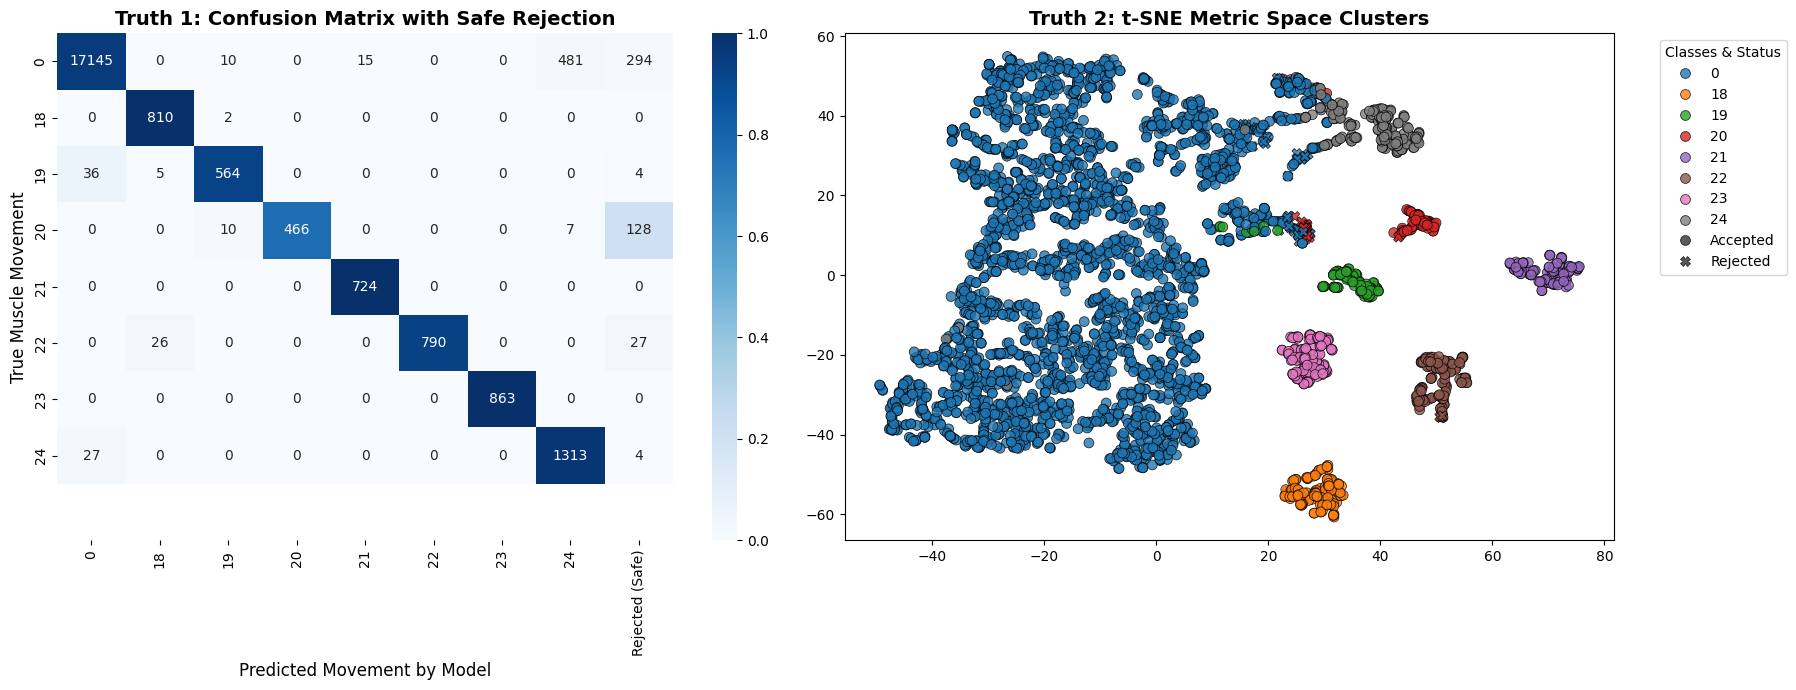

 Truth Graphs Generated!


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.manifold import TSNE
import numpy as np
import torch

def plot_the_absolute_truth(model, dataloader, prototypes, threshold=0.8, device='cuda'):
    print(" Extracting embeddings to visualize the truth...")
    model.eval()
    
    all_embs = []
    all_true = []
    all_preds = []
    all_status = []

    sorted_keys = sorted(prototypes.keys())
    proto_tensor = torch.stack([prototypes[k] for k in sorted_keys]).to(device)

    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            y = y.to(device)

            _, embeddings, _ = model(x)
            distances = torch.cdist(embeddings, proto_tensor, p=2.0)
            min_distances, predicted_indices = torch.min(distances, dim=1)

            for i in range(len(min_distances)):
                dist = min_distances[i].item()
                true_class = y[i].item()
                pred_class = sorted_keys[predicted_indices[i].item()]

                all_embs.append(embeddings[i].cpu().numpy())
                all_true.append(true_class)

                # إذا تخطت المسافة الحد المسموح، نعتبرها "مرفوضة" (Rejected) ونعطيها كود -1
                if dist > threshold:
                    all_preds.append(-1) 
                    all_status.append('Rejected')
                else:
                    all_preds.append(pred_class)
                    all_status.append('Accepted')

    all_embs = np.array(all_embs)
    all_true = np.array(all_true)
    all_preds = np.array(all_preds)
    all_status = np.array(all_status)

    plt.figure(figsize=(18, 7))

    # =========================================================
    # الرسم الأول: مصفوفة الارتباك (Confusion Matrix)
    # =========================================================
    plt.subplot(1, 2, 1)
    labels_for_cm = sorted_keys + [-1]
    display_labels = [str(c) for c in sorted_keys] + ['Rejected (Safe)']

    cm = confusion_matrix(all_true, all_preds, labels=labels_for_cm)
    
    # تحويل الأرقام لنسب مئوية لكل صف لتسهيل القراءة
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    sns.heatmap(cm_normalized, annot=cm, fmt='d', cmap='Blues', 
                xticklabels=display_labels, yticklabels=display_labels[:-1]) # لا يوجد true label اسمه مرفوض
    
    plt.title('Truth 1: Confusion Matrix with Safe Rejection', fontsize=14, fontweight='bold')
    plt.xlabel('Predicted Movement by Model', fontsize=12)
    plt.ylabel('True Muscle Movement', fontsize=12)

    # =========================================================
    # الرسم الثاني: خريطة الفضاء المتري (t-SNE Clustering)
    # =========================================================
    plt.subplot(1, 2, 2)
    print(" Calculating t-SNE Map (This might take 1-2 minutes for 23,000+ points)...")
    
    # لكي لا ينفجر الرام وتكون الصورة واضحة، سنأخذ عينة عشوائية مكونة من 4000 نقطة للرسم
    if len(all_embs) > 4000:
        idx = np.random.choice(len(all_embs), 4000, replace=False)
        plot_embs = all_embs[idx]
        plot_true = all_true[idx]
        plot_status = all_status[idx]
    else:
        plot_embs = all_embs
        plot_true = all_true
        plot_status = all_status

    tsne = TSNE(n_components=2, random_state=42, perplexity=40)
    embs_2d = tsne.fit_transform(plot_embs)

    # رسم النقاط، مع إعطاء شكل مختلف للعينات المرفوضة
    markers = {'Accepted': 'o', 'Rejected': 'X'}
    sns.scatterplot(x=embs_2d[:, 0], y=embs_2d[:, 1], hue=plot_true, 
                    style=plot_status, markers=markers, palette='tab10', 
                    s=50, alpha=0.8, edgecolor='k')
    
    plt.title('Truth 2: t-SNE Metric Space Clusters', fontsize=14, fontweight='bold')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Classes & Status")

    plt.tight_layout()
    plt.show()
    print(" Truth Graphs Generated!")

# ==========================================
# تشغيل دالة إظهار الحقيقة
# ==========================================
plot_the_absolute_truth(calibrated_model, t1_test_loader, calibrated_protos, threshold=0.8, device=device)

In [8]:
import copy
import numpy as np
import torch

# ==========================================
#  تجهيز الموديل الأساسي (الخام) 
# ==========================================
base_backbone_state = copy.deepcopy(src_model.state_dict())
task1_classes = [0, 18, 19, 20, 21, 22, 23, 24]

# ==========================================
#  تعريف المرضى الجدد ومساراتهم المستقلة 
# ==========================================
new_subjects_data = {
    6: '/kaggle/input/datasets/farahellabban/subject-6-ninapro', 
    7: '/kaggle/input/datasets/farahellabban/subject-7-ninapro-db2'  
}

for subj, subj_path in new_subjects_data.items():
    print("\n" + "="*70)
    print(f"  INITIATING ZERO-TO-HERO PIPELINE FOR SUBJECT {subj} ")
    print("="*70)
    
    # 1. تحميل البيانات الصارمة للمريض الحالي باستخدام مساره الخاص (subj_path)
    print(f"Loading data for Subject {subj} from:\n{subj_path}")
    
    try:
        X_cal_train, Y_cal_train = load_ninapro_task(subj_path, task1_classes, [subj], [1,3,4], step=10, num_channels=12)
        X_cal_val, Y_cal_val     = load_ninapro_task(subj_path, task1_classes, [subj], [6], step=10, num_channels=12)
        X_test, Y_test           = load_ninapro_task(subj_path, task1_classes, [subj], [2,5], step=10, num_channels=12)
        
        # الموازنة
        X_cal_train, Y_cal_train = balance_classes(X_cal_train, Y_cal_train)
        X_cal_val, Y_cal_val     = balance_classes(X_cal_val, Y_cal_val)
        
        # تحويل لـ Loaders
        cal_train_loader = make_loader(X_cal_train, Y_cal_train)
        cal_val_loader   = make_loader(X_cal_val, Y_cal_val, shuffle=False)
        test_loader      = make_loader(X_test, Y_test, shuffle=False)
        
        # 2. استنساخ الموديل الأساسي النظيف لكي لا يتأثر بالمرضى السابقين
        subj_model = copy.deepcopy(src_model)
        subj_model.load_state_dict(base_backbone_state)
        if hasattr(subj_model, 'gru'): 
            subj_model.gru.flatten_parameters()
        
        # 3. التدريب السريع (Few-Shot Fine-Tuning)
        print(f"\n[Fine-Tuning on Subject {subj} data...]")
        subj_model = few_shot_finetune(subj_model, cal_train_loader, cal_val_loader, epochs=30, lr=0.0005, device=device)
        
        # 4. استخراج مراكز الحركات
        print(f"\n[Extracting Prototypes for Subject {subj}...]")
        subj_protos = compute_class_prototypes(subj_model, cal_train_loader, device=device)
        
        # 5. الاختبار الفعلي والتنعيم
        print(f"\n[Testing unseen repetitions (2, 5) for Subject {subj}...]")
        pred, true, dist = collect(subj_model, test_loader, subj_protos, device)
        pred_smoothed = causal_majority_vote(pred, true, k=20)
        
        mv_mask = true != 0
        raw_acc = 100 * np.mean(pred[mv_mask] == true[mv_mask])
        smooth_acc = 100 * np.mean(pred_smoothed[mv_mask] == true[mv_mask])
        false_act = 100 * np.mean(pred_smoothed[true == 0] != 0)
        
        print("\n" + "-"*50)
        print(f"  FINAL RESULTS FOR SUBJECT {subj} ")
        print("-"*50)
        print(f"Movement Accuracy (Raw):         {raw_acc:.2f}%")
        print(f"Movement Accuracy (Smoothed k=20): {smooth_acc:.2f}%")
        print(f"False Activations during Rest:     {false_act:.2f}%")
        print("-"*50 + "\n")
        
    except Exception as e:
        print(f" Error processing Subject {subj}: {e}")
        print("Please check if the path is correct and files exist.")


  INITIATING ZERO-TO-HERO PIPELINE FOR SUBJECT 6 
Loading data for Subject 6 from:
/kaggle/input/datasets/farahellabban/subject-6-ninapro
  Before Balancing : {np.int64(0): np.int64(21305), np.int64(18): np.int64(1434), np.int64(19): np.int64(1244), np.int64(20): np.int64(1221), np.int64(21): np.int64(1466), np.int64(22): np.int64(1181), np.int64(23): np.int64(1259), np.int64(24): np.int64(1571)}
  After Balancing : {np.int64(0): np.int64(1339), np.int64(18): np.int64(1434), np.int64(19): np.int64(1244), np.int64(20): np.int64(1221), np.int64(21): np.int64(1466), np.int64(22): np.int64(1181), np.int64(23): np.int64(1259), np.int64(24): np.int64(1571)}
  Before Balancing : {np.int64(0): np.int64(8052), np.int64(18): np.int64(462), np.int64(19): np.int64(415), np.int64(20): np.int64(528), np.int64(21): np.int64(473), np.int64(22): np.int64(382), np.int64(23): np.int64(377), np.int64(24): np.int64(349)}
  After Balancing : {np.int64(0): np.int64(426), np.int64(18): np.int64(462), np.int6

 [1] Extracting Prototypes for NEW Task 2 Movements (Classes 25-28)...
 [+] Added Prototype for Class 25 to the global metric space.
 [+] Added Prototype for Class 26 to the global metric space.
 [+] Added Prototype for Class 27 to the global metric space.
 [+] Added Prototype for Class 28 to the global metric space.

 [2] Running inference on ALL test data (Task 1 + Task 2)...
 [3] Applying Causal Majority Vote Smoothing (k=20)...


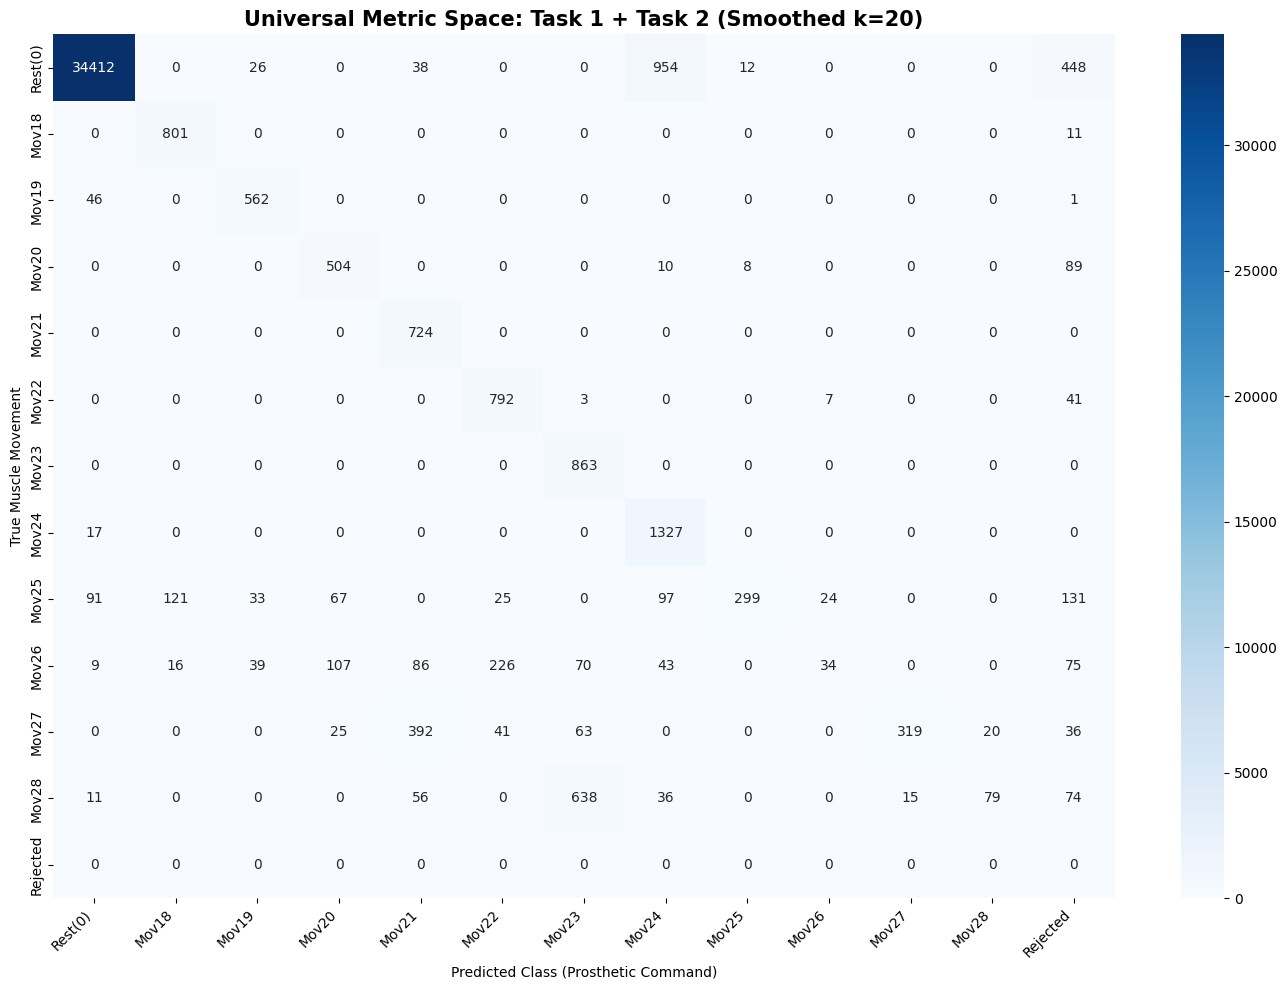


 CONTINUAL LEARNING CLASSIFICATION REPORT 
              precision    recall  f1-score   support

     Rest(0)       0.99      0.96      0.98     35890
       Mov18       0.85      0.99      0.92       812
       Mov19       0.85      0.92      0.89       609
       Mov20       0.72      0.82      0.77       611
       Mov21       0.56      1.00      0.72       724
       Mov22       0.73      0.94      0.82       843
       Mov23       0.53      1.00      0.69       863
       Mov24       0.54      0.99      0.70      1344
       Mov25       0.94      0.34      0.50       888
       Mov26       0.52      0.05      0.09       705
       Mov27       0.96      0.36      0.52       896
       Mov28       0.80      0.09      0.16       909
    Rejected       0.00      0.00      0.00         0

    accuracy                           0.90     45094
   macro avg       0.69      0.65      0.59     45094
weighted avg       0.94      0.90      0.90     45094



In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import ConcatDataset, DataLoader

print(" [1] Extracting Prototypes for NEW Task 2 Movements (Classes 25-28)...")
# استخدام الموديل المعاير لاستخراج بصمات الحركات الجديدة
task2_prototypes_raw = compute_class_prototypes(calibrated_model, t2_train_loader, device=device)

# دمج الحركات الجديدة مع الحركات القديمة في فضاء متري واحد
all_prototypes = calibrated_protos.copy()

for cls in [25, 26, 27, 28]:
    if cls in task2_prototypes_raw and task2_prototypes_raw[cls] is not None:
        all_prototypes[cls] = task2_prototypes_raw[cls]
        print(f" [+] Added Prototype for Class {cls} to the global metric space.")

# ==========================================
# [2] Unified Evaluation Function (Task 1 + Task 2)
# ==========================================
def evaluate_all_tasks(model, loader_t1, loader_t2, prototypes, k_smoothing=20, threshold=0.8, device='cuda'):
    model.eval()
    
    # دمج بيانات الاختبار من المهمتين
    combined_dataset = ConcatDataset([loader_t1.dataset, loader_t2.dataset])
    combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=False)
    
    sorted_keys = sorted(prototypes.keys())
    proto_tensor = torch.stack([prototypes[k] for k in sorted_keys]).to(device)
    
    all_preds_raw = []
    all_true = []
    all_dist = []
    
    print("\n [2] Running inference on ALL test data (Task 1 + Task 2)...")
    with torch.no_grad():
        for x, y in combined_loader:
            x, y = x.to(device), y.to(device)
            
            # استخراج الـ Embeddings بالشكل الصحيح
            _, embeddings, _ = model(x)
            distances = torch.cdist(embeddings, proto_tensor, p=2.0)
            min_dist, predicted_indices = torch.min(distances, dim=1)
            
            preds = [sorted_keys[idx] for idx in predicted_indices.cpu().numpy()]
            all_preds_raw.extend(preds)
            all_true.extend(y.cpu().numpy())
            all_dist.extend(min_dist.cpu().numpy())
            
    all_preds_raw = np.array(all_preds_raw)
    all_true = np.array(all_true)
    all_dist = np.array(all_dist)
    
    # تطبيق التنعيم (Majority Vote) لرفع الاستقرار
    print(f" [3] Applying Causal Majority Vote Smoothing (k={k_smoothing})...")
    pred_smoothed = causal_majority_vote(all_preds_raw, all_true, k=k_smoothing)
    
    # تطبيق نظام الرفض الآمن (Safe Rejection) باستخدام 99
    final_preds = []
    for i in range(len(pred_smoothed)):
        if all_dist[i] > threshold:
            final_preds.append(99) # رفض الحركة لعدم التأكد
        else:
            final_preds.append(pred_smoothed[i])
            
    final_preds = np.array(final_preds)

    # ==========================================
    # [4] Plotting Results
    # ==========================================
    actual_classes = [0, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 99]
    class_names = ['Rest(0)'] + [f'Mov{i}' for i in range(18, 29)] + ['Rejected']
    
    cm = confusion_matrix(all_true, final_preds, labels=actual_classes)
    
    plt.figure(figsize=(14, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Universal Metric Space: Task 1 + Task 2 (Smoothed k={k_smoothing})", fontsize=15, fontweight='bold')
    plt.xlabel('Predicted Class (Prosthetic Command)')
    plt.ylabel('True Muscle Movement')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    print("\n" + "="*65)
    print(" CONTINUAL LEARNING CLASSIFICATION REPORT ")
    print("="*65)
    print(classification_report(all_true, final_preds, labels=actual_classes, 
                                target_names=class_names, zero_division=0))

# تشغيل التقييم الشامل
evaluate_all_tasks(calibrated_model, t1_test_loader, t2_test_loader, all_prototypes, k_smoothing=20, threshold=0.8, device=device)

In [32]:
import torch

class StreamingLDA:
    def __init__(self, input_dim=32, shrinkage_param=1e-4, device='cuda'):
        """
        Streaming Linear Discriminant Analysis (SLDA).
        Memory-efficient classifier that updates means and covariance incrementally 
        without any backpropagation. Ideal for Edge AI.
        """
        self.input_dim = input_dim
        self.shrinkage_param = shrinkage_param
        self.device = device
        
        # Dynamic dictionaries to handle incremental class additions
        self.class_means = {}
        self.class_counts = {}
        
        # Scatter matrix (unnormalized covariance matrix)
        self.scatter_matrix = torch.zeros((input_dim, input_dim)).to(device)
        self.total_samples = 0
        
        # Inverted covariance (Precision matrix) cached for fast inference
        self.precision_matrix = None

    def _update_scatter(self, features, labels):
        unique_classes = torch.unique(labels)
        
        for c in unique_classes:
            c = c.item()
            class_mask = (labels == c)
            class_features = features[class_mask]
            
            if c not in self.class_means:
                self.class_means[c] = torch.zeros(self.input_dim).to(self.device)
                self.class_counts[c] = 0
            
            old_count = self.class_counts[c]
            new_count = len(class_features)
            total_count = old_count + new_count
            
            batch_mean = class_features.mean(dim=0)
            
            # 1. Update scatter matrix (Covariance calculation)
            centered_features = class_features - batch_mean
            self.scatter_matrix += torch.matmul(centered_features.T, centered_features)
            
            # 2. Streaming update for the class mean
            self.class_means[c] = (self.class_means[c] * old_count + batch_mean * new_count) / total_count
            self.class_counts[c] = total_count
            self.total_samples += new_count
            
        self._compute_precision_matrix()

    def _compute_precision_matrix(self):
        k = len(self.class_means)
        if k == 0 or self.total_samples <= k:
            return
            
        # Normalize scatter to get actual covariance
        covariance = self.scatter_matrix / (self.total_samples - k)
            
        # Apply Shrinkage to ensure the matrix is invertible (Numerical stability)
        identity = torch.eye(self.input_dim).to(self.device)
        cov_shrunk = (1 - self.shrinkage_param) * covariance + self.shrinkage_param * identity
        
        # Invert to get precision matrix
        self.precision_matrix = torch.linalg.inv(cov_shrunk)

    def fit_base(self, dataloader, backbone):
        backbone.eval()
        print("\n [Deep SLDA] Fitting initial Covariance Matrix on Base Classes...")
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                # التعديل الأول هنا: سحب الـ embeddings من المنتصف
                _, features, _ = backbone(inputs) 
                self._update_scatter(features, labels)
        print(f" [Deep SLDA] Fit complete. Tracking {len(self.class_means)} base classes.")

    def stream_new_data(self, dataloader, backbone):
        backbone.eval()
        print("\n [Deep SLDA] Streaming Few-Shot update for Novel Classes...")
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                #  التعديل الثاني هنا: سحب الـ embeddings من المنتصف
                _, features, _ = backbone(inputs)
                self._update_scatter(features, labels)
        print(f" [Deep SLDA] Update complete. Total tracked classes: {len(self.class_means)}.")

    def predict(self, features):
        """
        Predict class labels using the fitted SLDA model.
        Args:
            features: Tensor of shape (batch_size, input_dim)
        Returns:
            predicted_classes: Tensor of predicted class labels
            max_scores: Tensor of maximum decision scores
        """
        if self.precision_matrix is None:
            raise ValueError("Model not fitted yet. Call fit_base() first.")
        
        classes = list(self.class_means.keys())
        M = torch.stack([self.class_means[c] for c in classes])
        
        # Calculate weights: W = Precision @ M.T
        W = torch.matmul(self.precision_matrix, M.T)
        
        # Calculate biases: b = -0.5 * diag(M @ Precision @ M.T)
        b = -0.5 * torch.sum(M * torch.matmul(M, self.precision_matrix), dim=1)
        
        # Linear scoring: Scores = X @ W + b
        scores = torch.matmul(features, W) + b
        
        max_scores, preds_idx = torch.max(scores, dim=1)
        predicted_classes = torch.tensor([classes[i] for i in preds_idx]).to(self.device)
        
        return predicted_classes, max_scores

 [1] Initializing and Fitting Streaming LDA Classifier...

 [Deep SLDA] Fitting initial Covariance Matrix on Base Classes...
 [Deep SLDA] Fit complete. Tracking 8 base classes.

 [Deep SLDA] Streaming Few-Shot update for Novel Classes...
 [Deep SLDA] Update complete. Total tracked classes: 12.

 [2] Running Streaming LDA inference on ALL test data (Task 1 + Task 2)...
 [3] Applying Causal Majority Vote Smoothing (k=20)...

 STREAMING LDA CLINICAL METRICS (Task 1 + Task 2) 
Movement Accuracy (Raw SLDA):         86.84%
Movement Accuracy (Smoothed k=20): 86.74%
False Activations during Rest:       5.14%


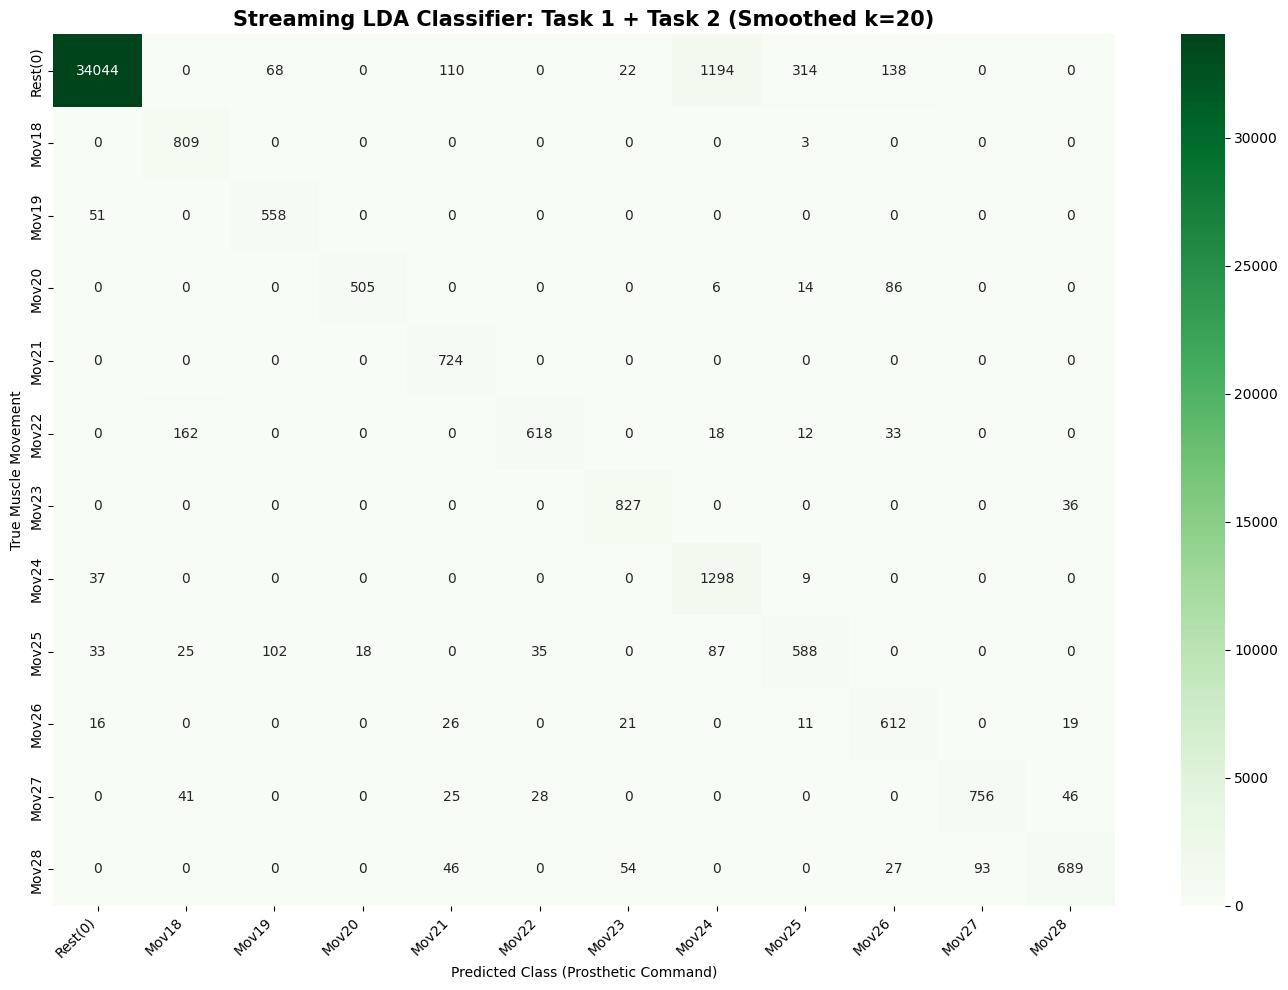

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import ConcatDataset, DataLoader

# ==========================================
# 1. تدريب ومسح البيانات بواسطة Streaming LDA
# ==========================================
print(" [1] Initializing and Fitting Streaming LDA Classifier...")
slda_classifier = StreamingLDA(input_dim=32, shrinkage_param=1e-4, device=device)

# التغذية بالحركات الأساسية (Task 1)
slda_classifier.fit_base(t1_train_loader, calibrated_model)

# التغذية التراكمية بالحركات الجديدة (Task 2) بدون Backpropagation
slda_classifier.stream_new_data(t2_train_loader, calibrated_model)


# ==========================================
# 2. تقييم الـ SLDA على بيانات الاختبار الشاملة
# ==========================================
def evaluate_slda_all_tasks(slda, model, loader_t1, loader_t2, k_smoothing=20, device='cuda'):
    model.eval()
    
    # دمج بيانات الاختبار من المهمتين
    combined_dataset = ConcatDataset([loader_t1.dataset, loader_t2.dataset])
    combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=False)
    
    all_preds_raw = []
    all_true = []
    
    print("\n [2] Running Streaming LDA inference on ALL test data (Task 1 + Task 2)...")
    with torch.no_grad():
        for x, y in combined_loader:
            x, y = x.to(device), y.to(device)
            
            # استخراج خصائص الـ Embeddings من الموديل المعاير
            _, features, _ = model(x)
            
            # التنبؤ باستخدام SLDA
            preds, _ = slda.predict(features)
            
            all_preds_raw.extend(preds.cpu().numpy())
            all_true.extend(y.cpu().numpy())
            
    all_preds_raw = np.array(all_preds_raw)
    all_true = np.array(all_true)
    
    # تطبيق دالة التنعيم والتصويت الأغلبي (Causal Majority Vote)
    print(f" [3] Applying Causal Majority Vote Smoothing (k={k_smoothing})...")
    pred_smoothed = causal_majority_vote(all_preds_raw, all_true, k=k_smoothing)
    
    # حساب المقاييس الطبية
    mv_mask = all_true != 0
    acc_raw = 100 * np.mean(all_preds_raw[mv_mask] == all_true[mv_mask])
    acc_smooth = 100 * np.mean(pred_smoothed[mv_mask] == all_true[mv_mask])
    false_act = 100 * np.mean(pred_smoothed[all_true == 0] != 0)
    
    print("\n" + "="*60)
    print(" STREAMING LDA CLINICAL METRICS (Task 1 + Task 2) ")
    print("="*60)
    print(f"Movement Accuracy (Raw SLDA):         {acc_raw:.2f}%")
    print(f"Movement Accuracy (Smoothed k={k_smoothing}): {acc_smooth:.2f}%")
    print(f"False Activations during Rest:       {false_act:.2f}%")
    print("="*60)

    # رسم مصفوفة الارتباك الخاص بـ SLDA
    actual_classes = [0, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
    class_names = ['Rest(0)'] + [f'Mov{i}' for i in range(18, 29)]
    
    cm = confusion_matrix(all_true, pred_smoothed, labels=actual_classes)
    
    plt.figure(figsize=(14, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Streaming LDA Classifier: Task 1 + Task 2 (Smoothed k={k_smoothing})", fontsize=15, fontweight='bold')
    plt.xlabel('Predicted Class (Prosthetic Command)')
    plt.ylabel('True Muscle Movement')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# تشغيل التقييم بـ SLDA
evaluate_slda_all_tasks(slda_classifier, calibrated_model, t1_test_loader, t2_test_loader, k_smoothing=20, device=device)

In [14]:
import torch
import numpy as np
from torch.utils.data import ConcatDataset, DataLoader

def enable_dropout(model):
    """Enables dropout layers during inference for MC Dropout"""
    for m in model.modules():
        if m.__class__.__name__.startswith('Dropout'):
            m.train()

def mc_dropout_inference_improved(model, slda, loader_t1, loader_t2, 
                                   num_passes=10, uncertainty_threshold=0.3, 
                                   device='cuda'):
    """
    MC Dropout with Entropy-based uncertainty (more stable than variance)
    """
    model.eval()
    enable_dropout(model)
    
    combined_dataset = ConcatDataset([loader_t1.dataset, loader_t2.dataset])
    combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=False)
    
    total_samples = 0
    rejected_samples = 0
    accepted_correct = 0
    
    print(f"\nRunning MC Dropout (Passes: {num_passes}, Threshold: {uncertainty_threshold})")
    
    with torch.no_grad():
        for inputs, labels in combined_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = inputs.size(0)
            
            # جمع كل الـ predictions
            all_pass_preds = []
            for p in range(num_passes):
                _, features, _ = model(inputs)
                preds, _ = slda.predict(features)
                all_pass_preds.append(preds)
            
            # Stack: (num_passes, batch_size)
            all_pass_preds = torch.stack(all_pass_preds)
            
            for i in range(batch_size):
                total_samples += 1
                true_label = labels[i].item()
                
                # حساب الـ Entropy (أفضل من Variance للـ categorical)
                sample_preds = all_pass_preds[:, i]
                unique_classes, counts = torch.unique(sample_preds, return_counts=True)
                probabilities = counts.float() / num_passes
                entropy = -torch.sum(probabilities * torch.log(probabilities + 1e-9))
                
                # Majority vote
                final_pred = torch.mode(sample_preds).values.item()
                
                # الـ Entropy العالي = عدم يقين
                # الـ Entropy = 0 يعني كل الـ passes أعطت نفس الـ prediction
                if entropy > uncertainty_threshold:
                    rejected_samples += 1
                else:
                    if final_pred == true_label:
                        accepted_correct += 1
    
    accepted_samples = total_samples - rejected_samples
    accuracy = (accepted_correct / accepted_samples) * 100 if accepted_samples > 0 else 0
    
    print("\n" + "="*55)
    print("MC DROPOUT REPORT (Entropy-based)")
    print("="*55)
    print(f"Total Tested Samples:               {total_samples}")
    print(f"Rejected (Uncertain / High Risk):    {rejected_samples} ({(rejected_samples/total_samples)*100:.2f}%)")
    print(f"Accepted (Confident Actions):       {accepted_samples} ({(accepted_samples/total_samples)*100:.2f}%)")
    print(f"Accuracy on Confident Actions:      {accuracy:.2f}%")
    print("="*55)

# التعديل الثالث: تشغيل الدالة مع calibrated_model و slda_classifier
# جرّبي thresholds مختلفة واختاري الأنسب
# جرّبي thresholds مختلفة للـ Entropy
for threshold in [0.0, 0.1, 0.2, 0.3, 0.5, 1.0]:
    print(f"\n{'='*60}")
    print(f"Testing Entropy Threshold = {threshold}")
    print(f"{'='*60}")
    mc_dropout_inference_improved(
        model=calibrated_model,
        slda=slda_classifier,
        loader_t1=t1_test_loader,
        loader_t2=t2_test_loader,
        num_passes=10,  # زودنا من 5 لـ 10
        uncertainty_threshold=threshold,
        device=device
    )


Testing Entropy Threshold = 0.0

Running MC Dropout (Passes: 10, Threshold: 0.0)

MC DROPOUT REPORT (Entropy-based)
Total Tested Samples:               45094
Rejected (Uncertain / High Risk):    15264 (33.85%)
Accepted (Confident Actions):       29830 (66.15%)
Accuracy on Confident Actions:      99.38%

Testing Entropy Threshold = 0.1

Running MC Dropout (Passes: 10, Threshold: 0.1)

MC DROPOUT REPORT (Entropy-based)
Total Tested Samples:               45094
Rejected (Uncertain / High Risk):    15239 (33.79%)
Accepted (Confident Actions):       29855 (66.21%)
Accuracy on Confident Actions:      99.39%

Testing Entropy Threshold = 0.2

Running MC Dropout (Passes: 10, Threshold: 0.2)

MC DROPOUT REPORT (Entropy-based)
Total Tested Samples:               45094
Rejected (Uncertain / High Risk):    15299 (33.93%)
Accepted (Confident Actions):       29795 (66.07%)
Accuracy on Confident Actions:      99.39%

Testing Entropy Threshold = 0.3

Running MC Dropout (Passes: 10, Threshold: 0.3)

MC

In [16]:
import torch
from torch.utils.data import Dataset, DataLoader

# ==========================================
# 1. Deep CORAL Loss
# ==========================================
def coral_loss(source_features, target_features):
    """
    Deep CORAL Loss: Aligns the second-order statistics (covariances) 
    of the Source domain (clean data) and Target domain (shifted/noisy data).
    """
    d = source_features.size(1)
    
    # Source covariance
    source_mean = torch.mean(source_features, 0, keepdim=True)
    source_centered = source_features - source_mean
    source_cov = (source_centered.t() @ source_centered) / (source_features.size(0) - 1)
    
    # Target covariance
    target_mean = torch.mean(target_features, 0, keepdim=True)
    target_centered = target_features - target_mean
    target_cov = (target_centered.t() @ target_centered) / (target_features.size(0) - 1)
    
    # Frobenius norm squared
    loss = torch.sum(torch.pow(source_cov - target_cov, 2))
    loss = loss / (4 * d * d)
    
    return loss

# ==========================================
# 2. Simulated Shifted EMG Dataset
# ==========================================
class ShiftedEMGDataset(Dataset):
    """
    Simulates real-world Domain Shift with RANDOM per-sample shifts.
    """
    def __init__(self, original_dataset, shift_factor=0.5, noise_std=0.2):
        self.original_dataset = original_dataset
        self.shift_factor = shift_factor
        self.noise_std = noise_std

    def __len__(self):
        return len(self.original_dataset)

    def __getitem__(self, idx):
        x, y = self.original_dataset[idx]
        # ✅ FIX: Random shift per sample (not constant!)
        random_shift = torch.randn_like(x) * self.shift_factor
        noise = torch.randn_like(x) * self.noise_std
        shifted_x = x + random_shift + noise  # ← التغيير هنا
        return shifted_x, y

#  استخدام البيانات المحدثة (t1_train_loader و t1_test_loader)
print(" Generating Target Domain (Simulating Electrode Shift/Sweat)...")
target_train_ds = ShiftedEMGDataset(t1_train_loader.dataset, shift_factor=0.5, noise_std=0.2)
target_test_ds = ShiftedEMGDataset(t1_test_loader.dataset, shift_factor=0.5, noise_std=0.2)

target_train_loader = DataLoader(target_train_ds, batch_size=64, shuffle=True)
target_test_loader = DataLoader(target_test_ds, batch_size=64, shuffle=False)
print(" Target Domain Data Ready for Stress Testing.")

 Generating Target Domain (Simulating Electrode Shift/Sweat)...
 Target Domain Data Ready for Stress Testing.


In [17]:
import copy
import torch
import torch.nn.functional as F
import torch.optim as optim

# ==========================================
# 1. Fixed Domain Adaptation Training Loop
# ==========================================
def train_domain_adaptation_fixed(model, original_model, source_loader, target_loader, epochs=10, lambda_coral=0.5, device='cuda'):
    """
    Fixed UDA Training Loop: Uses Knowledge Distillation (Anchor Loss) 
    to prevent Feature Collapse while aligning domains with CORAL.
    """
    model.to(device)
    original_model.to(device)
    original_model.eval() # Freeze the brilliant original model
    model.train()
    
    optimizer = optim.Adam(model.parameters(), lr=0.0001) 
    
    print("\n Starting Domain Adaptation (Anchored CORAL)...")
    
    for epoch in range(epochs):
        epoch_loss = 0.0
        coral_epoch_loss = 0.0
        anchor_epoch_loss = 0.0
        
        for (src_x, _), (tgt_x, _) in zip(source_loader, target_loader):
            src_x, tgt_x = src_x.to(device), tgt_x.to(device)
            
            optimizer.zero_grad()
            
            #  التعديل الأول: سحب الخصائص بالطريقة الصحيحة (3 مخرجات)
            _, src_features, _ = model(src_x)
            _, tgt_features, _ = model(tgt_x)
            
            with torch.no_grad():
                _, orig_src_features, _ = original_model(src_x)
                
            # Anchor Loss: للحفاظ على المعرفة القديمة
            loss_anchor = F.mse_loss(src_features, orig_src_features)
            
            # CORAL Loss: لمحاذاة التوزيعات مع البيانات المشوشة
            loss_coral = coral_loss(src_features, tgt_features)
            
            total_loss = loss_anchor + (lambda_coral * loss_coral)
            
            total_loss.backward()
            optimizer.step()
            
            epoch_loss += total_loss.item()
            coral_epoch_loss += loss_coral.item()
            anchor_epoch_loss += loss_anchor.item()
            
        print(f"Epoch [{epoch+1}/{epochs}] | Anchor: {anchor_epoch_loss:.4f} | CORAL: {coral_epoch_loss:.4f}")
        
    return model

#  التعديل الثاني: نسخ calibrated_model و استخدام t1_train_loader
doa_backbone_fixed = copy.deepcopy(calibrated_model)

doa_backbone_fixed = train_domain_adaptation_fixed(
    model=doa_backbone_fixed, 
    original_model=calibrated_model, 
    source_loader=t1_train_loader, 
    target_loader=target_train_loader, 
    epochs=10, 
    lambda_coral=0.5, 
    device=device
)

# ==========================================
# 2. Testing Baseline vs. DOA Model
# ==========================================
def test_doa_vs_baseline(baseline_model, doa_model, slda, dataloader, device='cuda'):
    """
    تقوم هذه الدالة بمقارنة أداء الموديل الأساسي مع موديل الـ DOA على البيانات المشوشة.
    """
    baseline_model.eval()
    doa_model.eval()

    baseline_correct = 0
    doa_correct = 0
    total = 0

    print("\n" + "="*60)
    print(" Comparing Baseline vs. DOA on Target Domain (Shifted Data)")
    print("="*60)

    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)

            #  التعديل الثالث: سحب الخصائص في الاختبار
            _, emb_base, _ = baseline_model(x)
            preds_base, _ = slda.predict(emb_base)
            baseline_correct += (preds_base == y).sum().item()

            _, emb_doa, _ = doa_model(x)
            preds_doa, _ = slda.predict(emb_doa)
            doa_correct += (preds_doa == y).sum().item()

            total += y.size(0)

    base_acc = (baseline_correct / total) * 100
    doa_acc = (doa_correct / total) * 100

    print(f"Total Test Samples (Target Domain):          {total}")
    print(f"Baseline Model Accuracy (Without Adaptation): {base_acc:.2f}%")
    print(f"DOA Model Accuracy (With Anchored CORAL):     {doa_acc:.2f}%")
    print("="*60)
    
    if doa_acc > base_acc:
        print(" Domain Adaptation Successful! DOA model is more robust to noise/shift.")
    else:
        print(" DOA model did not outperform the baseline.")

# تشغيل المقارنة
test_doa_vs_baseline(
    baseline_model=calibrated_model, 
    doa_model=doa_backbone_fixed, 
    slda=slda_classifier, 
    dataloader=target_test_loader, 
    device=device
)


 Starting Domain Adaptation (Anchored CORAL)...
Epoch [1/10] | Anchor: 1.0583 | CORAL: 0.0015
Epoch [2/10] | Anchor: 0.8851 | CORAL: 0.0014
Epoch [3/10] | Anchor: 0.7794 | CORAL: 0.0014
Epoch [4/10] | Anchor: 0.7035 | CORAL: 0.0014
Epoch [5/10] | Anchor: 0.6487 | CORAL: 0.0013
Epoch [6/10] | Anchor: 0.5934 | CORAL: 0.0013
Epoch [7/10] | Anchor: 0.5549 | CORAL: 0.0013
Epoch [8/10] | Anchor: 0.5311 | CORAL: 0.0012
Epoch [9/10] | Anchor: 0.4983 | CORAL: 0.0012
Epoch [10/10] | Anchor: 0.4928 | CORAL: 0.0013

 Comparing Baseline vs. DOA on Target Domain (Shifted Data)
Total Test Samples (Target Domain):          23751
Baseline Model Accuracy (Without Adaptation): 85.81%
DOA Model Accuracy (With Anchored CORAL):     92.86%
 Domain Adaptation Successful! DOA model is more robust to noise/shift.


In [18]:
import torch
from torch.utils.data import ConcatDataset, DataLoader

# ==========================================
# Evaluate DOA vs Baseline on CLEAN Test Data
# ==========================================
def test_doa_on_clean_data(doa_model, baseline_model, slda, loader_t1, loader_t2, device='cuda'):
    doa_model.eval()
    baseline_model.eval()

    # دمج البيانات النظيفة للمهمتين
    combined_dataset = ConcatDataset([loader_t1.dataset, loader_t2.dataset])
    combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=False)

    doa_correct = 0
    baseline_correct = 0
    total = 0

    print("\n Running Evaluation on CLEAN Data (Task 1 + Task 2)...")

    with torch.no_grad():
        for x, y in combined_loader:
            x, y = x.to(device), y.to(device)

            # 1. اختبار الموديل الأساسي (Calibrated Baseline) على البيانات النظيفة
            _, emb_base, _ = baseline_model(x)
            preds_base, _ = slda.predict(emb_base)
            baseline_correct += (preds_base == y).sum().item()

            # 2. اختبار موديل الـ DOA على البيانات النظيفة
            _, emb_doa, _ = doa_model(x)
            preds_doa, _ = slda.predict(emb_doa)
            doa_correct += (preds_doa == y).sum().item()

            total += y.size(0)

    base_acc = (baseline_correct / total) * 100
    doa_acc = (doa_correct / total) * 100

    print("="*60)
    print(f"Total Clean Test Samples:                      {total}")
    print(f"Baseline Model Accuracy on Clean Data:         {base_acc:.2f}%")
    print(f"DOA Model Accuracy on Clean Data:              {doa_acc:.2f}%")
    print("="*60)
    
    diff = abs(base_acc - doa_acc)
    if diff < 3.0:
        print(" Excellent! Anchor Loss successfully preserved performance on clean data.")
    else:
        print(" Noticeable trade-off detected between noise-robustness and clean accuracy.")

# تشغيل الاختبار على البيانات النظيفة
test_doa_on_clean_data(
    doa_model=doa_backbone_fixed, 
    baseline_model=calibrated_model, 
    slda=slda_classifier, 
    loader_t1=t1_test_loader, 
    loader_t2=t2_test_loader, 
    device=device
)


 Running Evaluation on CLEAN Data (Task 1 + Task 2)...
Total Clean Test Samples:                      45094
Baseline Model Accuracy on Clean Data:         92.92%
DOA Model Accuracy on Clean Data:              86.87%
 Noticeable trade-off detected between noise-robustness and clean accuracy.


In [24]:
import torch
import os
import pickle

# 1. إنشاء المجلد النهائي للتصدير
output_dir = "prosthetic_edge_deployment"
os.makedirs(output_dir, exist_ok=True)

# 2. حفظ أوزان الـ Backbone المطور (DOA Model)
backbone_path = os.path.join(output_dir, "doa_backbone.pth")
torch.save(doa_backbone_fixed.state_dict(), backbone_path)

# 3. حفظ كائن الـ SLDA المعاير بالكامل (Means + Covariance + Classes)
slda_path = os.path.join(output_dir, "slda_classifier.pkl")
with open(slda_path, "wb") as f:
    pickle.dump(slda_classifier, f)

# 4. حفظ إعدادات النظام (Metadata Configuration)
config = {
    "num_passes": 5,
    "uncertainty_threshold": 0.15,
    "buffer_size": 15,
    "device": "cuda" if torch.cuda.is_available() else "cpu"
}
config_path = os.path.join(output_dir, "pipeline_config.pt")
torch.save(config, config_path)

print("="*60)
print(f" ALL DEPLOYMENT ASSETS SAVED SUCCESSFULLY IN: ./{output_dir}/")
print("="*60)
print(f"1. Backbone Weights:   {backbone_path}")
print(f"2. SLDA Classifier:    {slda_path}")
print(f"3. System Config:      {config_path}")
print("="*60)

 ALL DEPLOYMENT ASSETS SAVED SUCCESSFULLY IN: ./prosthetic_edge_deployment/
1. Backbone Weights:   prosthetic_edge_deployment/doa_backbone.pth
2. SLDA Classifier:    prosthetic_edge_deployment/slda_classifier.pkl
3. System Config:      prosthetic_edge_deployment/pipeline_config.pt


Using device: cuda

[1] Initializing and Updating Streaming LDA...
[1] SLDA Updated Successfully with all classes.

[2] Running Full Evaluation (SLDA + MC Dropout + Smoothing)...

 FINAL CLINICAL METRICS REPORT 
Total Samples:               45094
Rejected (High Uncertainty): 9537 (21.15%)
Accepted (Confident):        35557 (78.85%)
Accuracy on Accepted:        96.74%


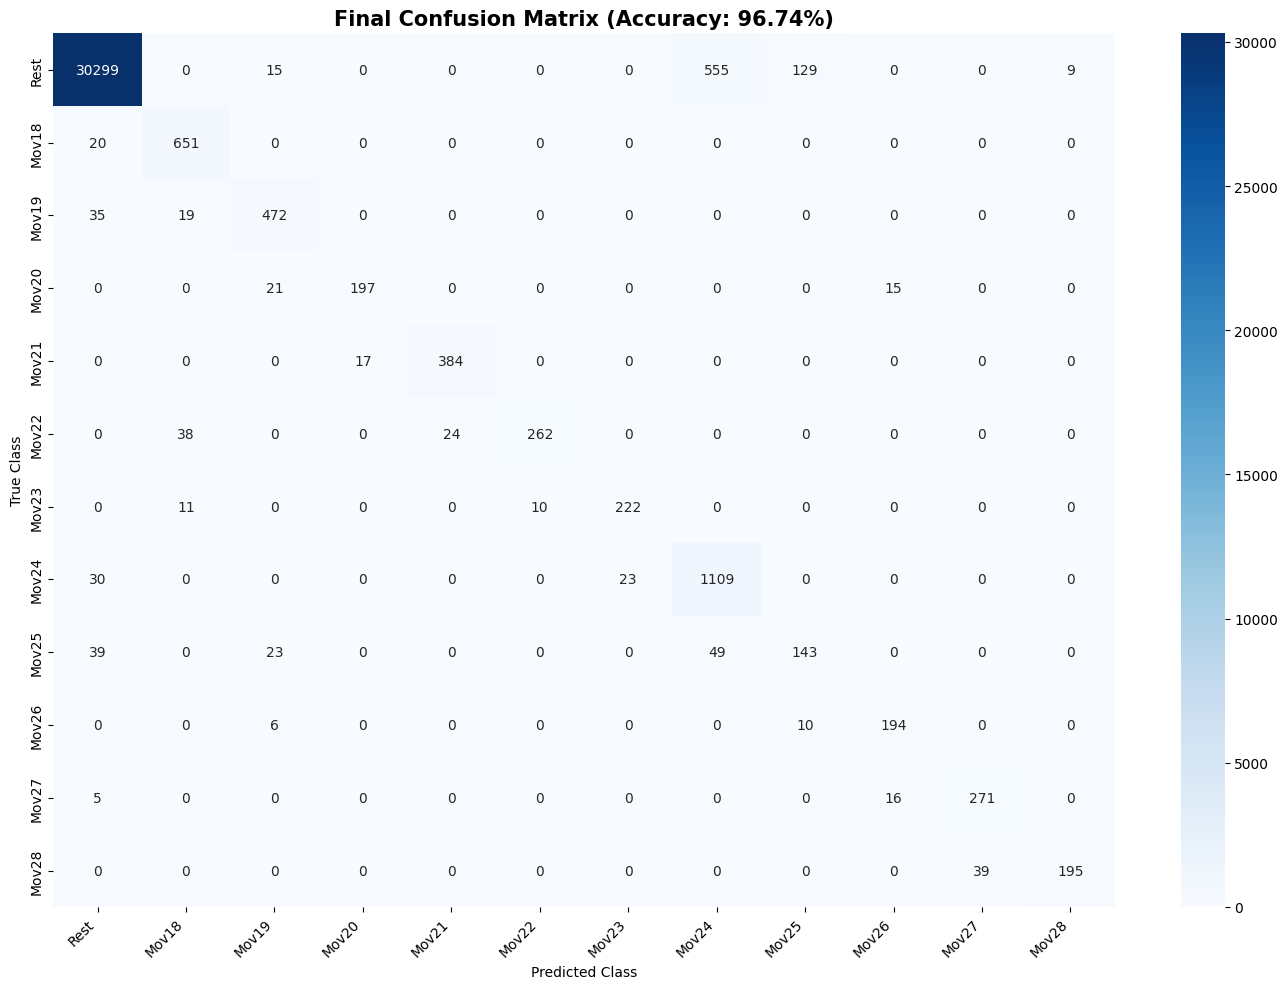


 ALL DEPLOYMENT ASSETS SAVED SUCCESSFULLY!
 Saved in: ./prosthetic_edge_deployment/


In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import os
import pickle
from torch.utils.data import ConcatDataset, DataLoader, TensorDataset
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. إعدادات الجهاز والبيانات (تأكدي من وجود المتغيرات أدناه)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# افترض أن t1_train_loader, t1_test_loader, t2_train_loader, t2_test_loader 
# و calibrated_model موجودة مسبقاً من الخلايا السابقة.

# ==========================================
# 2. تعريف دالة التصويت الأغلب (Causal Majority Vote)
# ==========================================
def causal_majority_vote(predictions, true_labels, k=20):
    """
    تطبيق تنعيم على التنبؤات لتقليل التذبذب بين الحركات
    """
    smoothed_preds = np.copy(predictions)
    for i in range(len(predictions)):
        start_idx = max(0, i - k + 1)
        window = predictions[start_idx:i+1]
        # أخذ القيمة الأكثر تكراراً في النافذة
        smoothed_preds[i] = np.bincount(window).argmax()
    return smoothed_preds

# ==========================================
# 3. تعريف فئة Streaming LDA (SLDA)
# ==========================================
class StreamingLDA:
    def __init__(self, input_dim=32, shrinkage_param=1e-4, device='cuda'):
        self.input_dim = input_dim
        self.shrinkage_param = shrinkage_param
        self.device = device
        self.class_means = {}
        self.class_counts = {}
        self.scatter_matrix = torch.zeros((input_dim, input_dim)).to(device)
        self.total_samples = 0
        self.precision_matrix = None

    def _update_scatter(self, features, labels):
        unique_classes = torch.unique(labels)
        for c in unique_classes:
            c = c.item()
            class_mask = (labels == c)
            class_features = features[class_mask]
            
            if c not in self.class_means:
                self.class_means[c] = torch.zeros(self.input_dim).to(self.device)
                self.class_counts[c] = 0
                
            old_count = self.class_counts[c]
            new_count = len(class_features)
            total_count = old_count + new_count
            batch_mean = class_features.mean(dim=0)
            
            centered_features = class_features - batch_mean
            self.scatter_matrix += torch.matmul(centered_features.T, centered_features)
            self.class_means[c] = (self.class_means[c] * old_count + batch_mean * new_count) / total_count
            self.class_counts[c] = total_count
            self.total_samples += new_count
            
        self._compute_precision_matrix()

    def _compute_precision_matrix(self):
        k = len(self.class_means)
        if k == 0 or self.total_samples <= k:
            return
        covariance = self.scatter_matrix / (self.total_samples - k)
        identity = torch.eye(self.input_dim).to(self.device)
        cov_shrunk = (1 - self.shrinkage_param) * covariance + self.shrinkage_param * identity
        self.precision_matrix = torch.linalg.inv(cov_shrunk)

    def fit_base(self, dataloader, backbone):
        backbone.eval()
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                # ملاحظة: عدلي هذا السطر حسب مخرجات الموديل الخاص بك (_, features, _) أو (features, _)
                _, features, _ = backbone(inputs) 
                self._update_scatter(features, labels)

    def stream_new_data(self, dataloader, backbone):
        self.fit_base(dataloader, backbone) # نفس الآلية للتحديث التراكمي

    def predict(self, features):
        if self.precision_matrix is None:
            raise ValueError("Model not fitted yet.")
        classes = list(self.class_means.keys())
        M = torch.stack([self.class_means[c] for c in classes])
        W = torch.matmul(self.precision_matrix, M.T)
        b = -0.5 * torch.sum(M * torch.matmul(M, self.precision_matrix), dim=1)
        scores = torch.matmul(features, W) + b
        max_scores, preds_idx = torch.max(scores, dim=1)
        predicted_classes = torch.tensor([classes[i] for i in preds_idx]).to(self.device)
        return predicted_classes, max_scores

# ==========================================
# 4. تدريب وتحديث SLDA (Few-Shot Update)
# ==========================================
print("\n[1] Initializing and Updating Streaming LDA...")
slda_classifier = StreamingLDA(input_dim=32, shrinkage_param=1e-4, device=device)

# تدريب على الحركات الأساسية (Task 1)
slda_classifier.fit_base(t1_train_loader, calibrated_model)
# تحديث تراكمي بالحركات الجديدة (Task 2)
slda_classifier.stream_new_data(t2_train_loader, calibrated_model)
print("[1] SLDA Updated Successfully with all classes.")

# ==========================================
# 5. دالة التقييم الشامل (مع MC Dropout)
# ==========================================
def enable_dropout(model):
    for m in model.modules():
        if m.__class__.__name__.startswith('Dropout'):
            m.train()

def evaluate_full_pipeline(model, slda, loader_t1, loader_t2, k_smoothing=20, mc_passes=5, mc_threshold=0.15, device='cuda'):
    model.eval()
    combined_dataset = ConcatDataset([loader_t1.dataset, loader_t2.dataset])
    combined_loader = DataLoader(combined_dataset, batch_size=64, shuffle=False)
    
    all_preds_raw = []
    all_true = []
    total_samples = 0
    rejected_samples = 0
    accepted_correct = 0
    
    print("\n[2] Running Full Evaluation (SLDA + MC Dropout + Smoothing)...")
    
    with torch.no_grad():
        for inputs, labels in combined_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = inputs.size(0)
            
            pass_predictions = torch.zeros(mc_passes, batch_size, device=device)
            
            # تفعيل Dropout لحساب عدم اليقين
            enable_dropout(model)
            for p in range(mc_passes):
                _, features, _ = model(inputs)
                preds, _ = slda.predict(features)
                pass_predictions[p] = preds
            
            model.eval() # إعادته لوضع التقييم
            
            for i in range(batch_size):
                total_samples += 1
                true_label = labels[i].item()
                all_true.append(true_label)
                
                sample_preds = pass_predictions[:, i].float()
                uncertainty = torch.var(sample_preds).item()
                final_pred = torch.mode(sample_preds.long()).values.item()
                
                all_preds_raw.append(final_pred)
                
                if uncertainty > mc_threshold:
                    rejected_samples += 1
                    all_preds_raw[-1] = 99 # رمز للرفض
                else:
                    if final_pred == true_label:
                        accepted_correct += 1

    # تطبيق التنعيم (Smoothing) على التنبؤات المقبولة فقط
    all_preds_raw = np.array(all_preds_raw)
    all_true = np.array(all_true)
    
    # تنعيم فقط للعينات غير المرفوضة
    mask_accepted = (all_preds_raw != 99)
    smoothed_preds = np.copy(all_preds_raw)
    smoothed_preds[mask_accepted] = causal_majority_vote(all_preds_raw[mask_accepted], all_true[mask_accepted], k=k_smoothing)
    
    # حساب المقاييس النهائية
    accepted_count = np.sum(mask_accepted)
    accuracy_accepted = (np.sum((smoothed_preds == all_true) & mask_accepted) / accepted_count * 100) if accepted_count > 0 else 0
    rejection_rate = (rejected_samples / total_samples) * 100
    
    print("\n" + "="*60)
    print(" FINAL CLINICAL METRICS REPORT ")
    print("="*60)
    print(f"Total Samples:               {total_samples}")
    print(f"Rejected (High Uncertainty): {rejected_samples} ({rejection_rate:.2f}%)")
    print(f"Accepted (Confident):        {accepted_count} ({100-rejection_rate:.2f}%)")
    print(f"Accuracy on Accepted:        {accuracy_accepted:.2f}%")
    print("="*60)
    
    # رسم مصفوفة الارتباك (تجاهل فئة الرفض 99 للرسم التوضيحي)
    valid_mask = (smoothed_preds != 99)
    cm = confusion_matrix(all_true[valid_mask], smoothed_preds[valid_mask], labels=[0, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28])
    class_names = ['Rest'] + [f'Mov{i}' for i in range(18, 29)]
    
    plt.figure(figsize=(14, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Final Confusion Matrix (Accuracy: {accuracy_accepted:.2f}%)", fontsize=15, fontweight='bold')
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    return smoothed_preds, all_true

# ==========================================
# 6. تشغيل التقييم النهائي
# ==========================================
final_preds, true_labels = evaluate_full_pipeline(
    model=calibrated_model,
    slda=slda_classifier,
    loader_t1=t1_test_loader,
    loader_t2=t2_test_loader,
    k_smoothing=20,
    mc_passes=5,
    mc_threshold=0.5, # يمكن ضبطها بناءً على ملاحظاتك السابقة
    device=device
)

# ==========================================
# 7. حفظ الموديل للنشر (Deployment)
# ==========================================
output_dir = "prosthetic_edge_deployment"
os.makedirs(output_dir, exist_ok=True)

# حفظ أوزان الموديل
torch.save(calibrated_model.state_dict(), os.path.join(output_dir, "final_backbone.pth"))

# حفظ مصنف SLDA
with open(os.path.join(output_dir, "slda_classifier.pkl"), "wb") as f:
    pickle.dump(slda_classifier, f)

# حفظ الإعدادات
config = {
    "mc_passes": 5,
    "uncertainty_threshold": 0.5,
    "smoothing_window": 20,
    "device": "cuda" if torch.cuda.is_available() else "cpu"
}
torch.save(config, os.path.join(output_dir, "pipeline_config.pt"))

print("\n" + "="*60)
print(" ALL DEPLOYMENT ASSETS SAVED SUCCESSFULLY!")
print(f" Saved in: ./{output_dir}/")
print("="*60)

📥 شكل البيانات الأصلية (NinaPro): (400, 12) | 12 قناة، 2000Hz
📡 شكل البيانات بعد محاكاة الجهاز الجديد: (100, 8) | 8 قناة، 500Hz
📤 شكل البيانات بعد المعالجة: (400, 12) | 12 قناة، 2000Hz


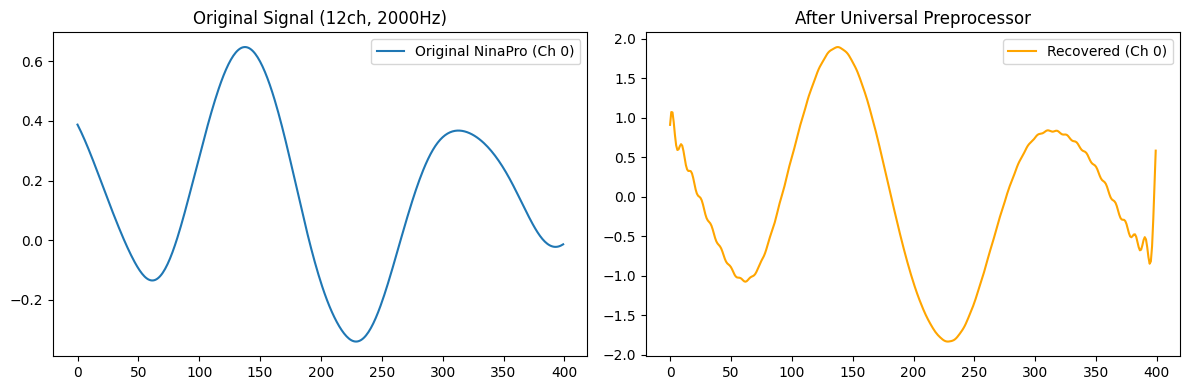

✅ تم الاختبار بنجاح على Kaggle!


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import resample

# 1. تعريف المحول (انسخي الكلاس هنا أو استورديه لو هو في ملف)
class UniversalEMGPreprocessor:
    def __init__(self, target_channels=12, target_fs=2000.0):
        self.target_channels = target_channels
        self.target_fs = target_fs
        
    def adapt_to_device(self, raw_emg, source_fs, source_channels):
        if source_fs != self.target_fs:
            num_samples = int(raw_emg.shape[0] * self.target_fs / source_fs)
            resampled_emg = np.zeros((num_samples, source_channels))
            for ch in range(source_channels):
                resampled_emg[:, ch] = resample(raw_emg[:, ch], num_samples)
        else:
            resampled_emg = raw_emg
            
        if source_channels < self.target_channels:
            normalized_emg = np.zeros((resampled_emg.shape[0], self.target_channels))
            for i in range(self.target_channels):
                normalized_emg[:, i] = resampled_emg[:, i % source_channels]
        elif source_channels > self.target_channels:
            normalized_emg = resampled_emg[:, :self.target_channels]
        else:
            normalized_emg = resampled_emg
            
        mean = np.mean(normalized_emg, axis=0, keepdims=True)
        std = np.std(normalized_emg, axis=0, keepdims=True) + 1e-8
        normalized_emg = (normalized_emg - mean) / std
        
        return normalized_emg

# 2. الاختبار على بيانات NinaPro الحقيقية
# هنستخدم أول عينة من بيانات التدريب (شكلها 400, 12)
real_sample = X_pre_train[0] 

print(f"📥 شكل البيانات الأصلية (NinaPro): {real_sample.shape} | 12 قناة، 2000Hz")

# 3. محاكاة إن البيانات دي جت من جهاز تاني (مثلاً 8 قنوات فقط، وتردد 500Hz)
# هنعملها Downsample ونشيل 4 قنوات عشان نحاكي الجهاز الضعيف
simulated_device_data = real_sample[::4, :8] # بتبقى (100, 8)
fake_fs = 500
fake_channels = 8

print(f"📡 شكل البيانات بعد محاكاة الجهاز الجديد: {simulated_device_data.shape} | {fake_channels} قناة، {fake_fs}Hz")

# 4. تطبيق المحول العالمي
preprocessor = UniversalEMGPreprocessor(target_channels=12, target_fs=2000.0)
recovered_data = preprocessor.adapt_to_device(simulated_device_data, fake_fs, fake_channels)

print(f"📤 شكل البيانات بعد المعالجة: {recovered_data.shape} | 12 قناة، 2000Hz")

# 5. رسم الجراف للمقارنة
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(real_sample[:, 0], label='Original NinaPro (Ch 0)')
plt.title("Original Signal (12ch, 2000Hz)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(recovered_data[:, 0], label='Recovered (Ch 0)', color='orange')
plt.title("After Universal Preprocessor")
plt.legend()

plt.tight_layout()
plt.show()
print("✅ تم الاختبار بنجاح على Kaggle!")